# Calibrated microstructure models of refractory linings: Kanapy RVEs, thermal-shock cracking, creep, and CNN surrogates validated against literature data

**Author:** Prajwal Sreenath — ICAMS, Ruhr-Universität Bochum  ·  with Prof. A. Hartmaier (ICAMS)

### Abstract
Thermal-shock cracking and high-temperature creep of carbon-bonded and oxide refractories are controlled by the
microstructure — graphite flakes, pores, grain boundaries and weak interfaces — which composition-based screening cannot
resolve. We generate periodic two-dimensional representative volume elements (RVEs) of MgO–C, Al₂O₃–C, MgO–ZrO₂ and
magnesia with **Kanapy** ellipsoid packing (all microstructures in this study), simulate thermal-shock damage by
sequentially linear analysis and Norton creep with a verified finite-element solver that is cross-checked against
**Abaqus**, and **calibrate** the grain-scale model against open literature data for real bricks: Young's modulus and
modulus of rupture of MgO–C with 15 wt% graphite and compressive creep of a fired magnesia brick at 1350 and 1425 °C.
The calibrated model is then **validated on data not used for calibration** (MgO–C with 7 wt% graphite, a magnesia
brick's modulus, creep at 1500 °C). A shared-encoder dual-head U-Net trained on 320 calibrated RVEs predicts full damage
and creep-strain maps from the microstructure image; it is evaluated on held-out RVEs and on statistically distinct
Kanapy realizations of five ranked candidate grades. The key numbers are collected automatically in Section 15.

### Structure
| § | Content |
|---|---|
| 0–1 | Configuration, source modules |
| 2 | Literature data (calibration and validation targets, with references) |
| 3 | Methods (microstructure, FE model, cracking, tension, creep, surrogates) |
| 4 | Verification of the solver (exact solutions, scaling laws, step convergence) |
| 5 | Calibration (boundary stiffness, local strength, creep law) |
| 6 | Validation on held-out literature data |
| 7 | Dataset: 320 Kanapy RVEs with the calibrated model |
| 8 | Physics in the data |
| 9 | ANN for scalar properties |
| 10 | Dual-head CNN (damage + creep maps) |
| 11 | Ranked candidate grades: Kanapy realizations, material-level prediction, uncertainty |
| 12 | Abaqus: solver verification (CIP run) and calibrated decks |
| 13 | Verification summary |
| 14 | Limitations |
| 15 | Key results, conclusions, references, reproducibility |

**Verification vs. validation.** *Verification* asks whether the equations are solved correctly (exact solutions,
scaling laws, an independent commercial solver). *Calibration* chooses uncertain parameters so that the model reproduces
one part of the measurements. *Validation* compares predictions with measurements that were **not** used for
calibration. The three are kept strictly separate below.

> **Version 2 (2026-10-15), after the Abaqus cross-check:** energy-consistent saw-tooth law (25 teeth, dissipates exactly $G_F$; the v1 4-tooth law dissipated ~9 %), creep at the 4 Gauss points (v1: element average, up to factor 1.8 too low near pores), batched tension SLA, REHEAT step before PROBE1 in the Abaqus decks, Kanapy periodicity test over 12 packings, new Section 12.1b. Before running: move the v1 result folders away (see the cell below).

**Before Run All (once, in a terminal on jupyter2):** keep the v1 results and force recalibration + resimulation. The Kanapy microstructure cache `micro_kanapy` stays, so all RVEs remain identical.

```bash
cd ~/prajwal/prajwalsreenath/MaterialRanger_RVE/MR_RVE_work
mkdir -p v1_results && mv calibration sim_cal ranked_cal models_cal abaqus_decks_cal figs_pub v1_results/
```

Then: Kernel → Restart → Run All (about 1.5–2 h with 12 workers). Section 12.2 writes the new calibrated Abaqus decks.

## 0. Configuration

In [1]:
# thread limits FIRST (before numpy/scipy/tensorflow are imported): one thread per worker, parallelism via joblib
import os
N_CPU = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 2)
for v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[v] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

CONFIG = dict(
    WORKDIR="MR_RVE_work",               # same work folder as before; all new results go to new sub-folders
    N_PIXELS=64, L_MM=1.0,               # 1 mm RVE, 64 x 64 pixels = elements = CNN image (15.6 um / pixel)
    N_PER_FAMILY=80,                     # 4 families x 80 = 320 design RVEs (all Kanapy)
    DESIGN_SEED=2026,
    DT_LEVELS=[25.0, 50.0, 100.0, 200.0, 400.0],   # thermal-shock levels of the calibrated model [K]
    N_REAL_CAL=10,                       # Kanapy realizations per literature grade (calibration / validation)
    N_REAL_PER_GRADE=10,                 # Kanapy realizations per ranked candidate grade
    CREEP_N_GRID=[1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0],
    RUN_SIMULATIONS=True,                # simulate everything that is not cached yet (resume-safe)
    RECALIBRATE=False,                   # True: redo the calibration even if calibration/cal.json exists
    TENSION_IN_DATASET=True,             # tensile strength of every RVE (adds ~1 min per RVE)
    N_JOBS=12,                           # parallel workers (jupyter2 account: ~12 cores usable)
    TRAIN_CNN=True, CNN_EPOCHS=40, DUAL_EPOCHS=40, CNN_BASE_FILTERS=16,
    TF_THREADS=max(1, min(N_CPU, 16)),
    ABAQUS_DECKS_PER_FAMILY=5, KANAPY_DECKS_PER_GRADE=2,      # calibrated decks for the next CIP run
    OLD_SIM_DIR="MR_RVE_work/sim", OLD_RANKED_DIR="MR_RVE_work/ranked",            # uncalibrated model (CIP run)
    OLD_ABAQUS_RESULTS="MR_RVE_work/abaqus_results",
    SEED=0,
)
print("CPUs:", N_CPU, "| parallel workers:", CONFIG["N_JOBS"])

CPUs: 256 | parallel workers: 12


In [2]:
import sys, json, time, glob, warnings, importlib, pickle, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from joblib import Parallel, delayed
warnings.filterwarnings("ignore", category=RuntimeWarning)
try:
    from threadpoolctl import threadpool_limits
    threadpool_limits(1)
except ImportError:
    pass
W = CONFIG["WORKDIR"]
SUB = dict(MICRO="micro_kanapy", CAL="calibration", SIMC="sim_cal", RANKC="ranked_cal", DECKS="abaqus_decks_cal",
           ARES="abaqus_results_cal", MOD="models_cal", FIG="figs_pub")
P = {k: os.path.join(W, v) for k, v in SUB.items()}
for v in P.values():
    os.makedirs(v, exist_ok=True)
os.makedirs("mr_rve_src", exist_ok=True)
if os.path.abspath("mr_rve_src") not in sys.path:
    sys.path.insert(0, os.path.abspath("mr_rve_src"))
FIG = P["FIG"]
CHECKS = {}
def check(name, passed, value=""):
    CHECKS[name] = (bool(passed), value)
    print(("PASS  " if passed else "FAIL  ") + name + (f"   [{value}]" if value != "" else ""))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
def par(fn, items, n_jobs=None):
    """Parallel map with joblib (separate processes; the modules are importable from mr_rve_src)."""
    return Parallel(n_jobs=n_jobs or CONFIG["N_JOBS"])(delayed(fn)(x) for x in items)

## 1. Source modules
Written with `%%writefile` so that parallel worker processes can import them; every line stays visible here.
New in this version: `literature` (all experimental data with references) and `calib` (calibrated phase table,
uniaxial-tension SLA, creep master curves, calibration routines); `driver` now caches the Kanapy microstructures and
takes the calibrated parameters.

In [3]:
%%writefile mr_rve_src/rve_gen.py
# ---------------------------------------------------------------------------
# Periodic 2-D RVE generator (pixel based).
#   Every pixel gets one phase code. The same pixel grid is the finite-element
#   mesh (one CPE4 element per pixel) and the CNN input image, so the
#   simulation result maps 1:1 onto the image.
# ---------------------------------------------------------------------------
import numpy as np

PHASES = {0: "PORE", 1: "MGO", 2: "MGO_GB", 3: "GRAPHITE", 4: "ITF",
          5: "ZRO2", 6: "AL2O3", 7: "AL2O3_GB", 8: "BINDER"}
PHASE_ID = {v: k for k, v in PHASES.items()}
N_PHASES = len(PHASES)
FAMILIES = ["MGOC", "MGOZR", "MAG", "ALC"]
FAMILY_LABEL = {"MGOC": "MgO-C", "MGOZR": "MgO-ZrO2", "MAG": "Magnesia", "ALC": "Al2O3-C"}

# parameter ranges of the design of experiments (per family)
PARAM_RANGES = {
    "MGOC":  dict(f_second=(0.10, 0.30), flake_len_um=(120, 400), aspect=(5, 12), orient_sd=(0.10, 1.20),
                  porosity=(0.02, 0.08), grain_um=(60, 160), binder=(0.00, 0.05),
                  k_gb=(0.40, 0.80), k_itf=(0.15, 0.60)),
    "MGOZR": dict(f_second=(0.05, 0.25), part_um=(30, 90), porosity=(0.08, 0.18), grain_um=(60, 160),
                  k_gb=(0.40, 0.80), k_itf=(0.50, 1.00)),
    "MAG":   dict(porosity=(0.10, 0.20), pore_um=(20, 60), grain_um=(60, 160), k_gb=(0.40, 0.80)),
    "ALC":   dict(f_second=(0.10, 0.25), flake_len_um=(120, 400), aspect=(5, 12), orient_sd=(0.10, 1.20),
                  porosity=(0.02, 0.08), grain_um=(40, 120), binder=(0.00, 0.05),
                  k_gb=(0.40, 0.80), k_itf=(0.15, 0.60)),
}
# loading parameters sampled for every RVE (thermal shock is evaluated at fixed dT levels)
LOAD_RANGES = dict(creep_stress=(1.0, 8.0), creep_T=(1350.0, 1550.0))   # calibration range of the creep law (1350-1500 C) + service temperature


def lhs(n, ranges, rng):
    """Latin hypercube sample: n rows, one stratum per row and parameter."""
    keys = list(ranges)
    out = {k: np.empty(n) for k in keys}
    for k in keys:
        lo, hi = ranges[k]
        u = (rng.permutation(n) + rng.random(n)) / n
        out[k] = lo + u * (hi - lo)
    return [{k: float(out[k][i]) for k in keys} for i in range(n)]


def _grid(N):
    yy, xx = np.mgrid[0:N, 0:N]
    return (xx + 0.5) / N, (yy + 0.5) / N          # pixel centres in [0,1)


def periodic_voronoi(N, n_grains, rng):
    """Grain-id map of a periodic Voronoi tessellation (nearest periodic seed)."""
    from scipy.spatial import cKDTree
    seeds = rng.random((n_grains, 2))
    shifts = np.array([[i, j] for i in (-1, 0, 1) for j in (-1, 0, 1)], float)
    allseeds = (seeds[None] + shifts[:, None]).reshape(-1, 2)
    owner = np.tile(np.arange(n_grains), 9)
    X, Y = _grid(N)
    _, idx = cKDTree(allseeds).query(np.c_[X.ravel(), Y.ravel()])
    return owner[idx].reshape(N, N)


def _ellipse_mask(N, cx, cy, a, b, th):
    X, Y = _grid(N)
    dx = (X - cx + 0.5) % 1.0 - 0.5            # periodic distance
    dy = (Y - cy + 0.5) % 1.0 - 0.5
    u = dx * np.cos(th) + dy * np.sin(th)
    v = -dx * np.sin(th) + dy * np.cos(th)
    return (u / a) ** 2 + (v / b) ** 2 <= 1.0


def place_inclusions(phase, code, target, a_rng, aspect_rng, rng, angle_mean=None, angle_sd=None,
                     min_b=None, allowed=None, max_tries=4000):
    """Add periodic ellipses of phase `code` until the area fraction reaches `target`."""
    N = phase.shape[0]
    min_b = min_b if min_b is not None else 0.6 / N
    tries = 0
    while (phase == code).mean() < target and tries < max_tries:
        tries += 1
        cx, cy = rng.random(2)
        a = rng.uniform(*a_rng)
        b = max(a / rng.uniform(*aspect_rng), min_b)
        th = (rng.normal(angle_mean, angle_sd) if angle_sd is not None else rng.uniform(0, np.pi))
        m = _ellipse_mask(N, cx, cy, a, b, th)
        if allowed is not None:
            m &= np.isin(phase, allowed)
        phase[m] = code
    return phase


def _neighbours(arr):
    """4-neighbours with periodic wrap: right, left, up, down."""
    return (np.roll(arr, -1, 1), np.roll(arr, 1, 1), np.roll(arr, -1, 0), np.roll(arr, 1, 0))


def largest_periodic_component(solid):
    """Union-find over solid pixels with periodic 4-connectivity; returns mask of the largest cluster."""
    N = solid.shape[0]
    parent = np.arange(N * N)

    def find(x):
        root = x
        while parent[root] != root:
            root = parent[root]
        while parent[x] != root:
            parent[x], x = root, parent[x]
        return root

    idx = np.arange(N * N).reshape(N, N)
    for nb in (np.roll(idx, -1, 1), np.roll(idx, -1, 0)):
        both = solid & solid.ravel()[nb]
        for a, b in zip(idx[both], nb[both]):
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[ra] = rb
    roots = np.array([find(i) for i in range(N * N)]).reshape(N, N)
    roots[~solid] = -1
    vals, counts = np.unique(roots[solid], return_counts=True)
    return roots == vals[np.argmax(counts)]


def make_rve(family, p, N=64, L_mm=1.0, seed=0, grains=None):
    """Return (phase_map[N,N] uint8, grain_map, info dict). p = sampled parameters.
    grains: optional periodic grain-id map (e.g. from Kanapy); default = periodic Voronoi."""
    rng = np.random.default_rng(seed)
    h_um = 1000.0 * L_mm / N
    area_um2 = (1000.0 * L_mm) ** 2
    if grains is None:
        n_grains = max(4, int(round(area_um2 / (p["grain_um"] ** 2))))
        grains = periodic_voronoi(N, n_grains, rng)
    else:
        grains = np.asarray(grains)
        assert grains.shape == (N, N), "grain map must be N x N"
        n_grains = int(len(np.unique(grains)))
    matrix, gbcode = (PHASE_ID["AL2O3"], PHASE_ID["AL2O3_GB"]) if family == "ALC" else (PHASE_ID["MGO"], PHASE_ID["MGO_GB"])
    phase = np.full((N, N), matrix, np.uint8)

    # grain boundaries: one pixel where the right or upper neighbour belongs to another grain
    gb = (grains != np.roll(grains, -1, 1)) | (grains != np.roll(grains, -1, 0))
    phase[gb] = gbcode

    um = 1.0 / (1000.0 * L_mm)                 # 1 micrometre in RVE units
    if family in ("MGOC", "ALC"):
        a_lo = 0.5 * p["flake_len_um"] * 0.8 * um
        a_hi = 0.5 * p["flake_len_um"] * 1.2 * um
        asp = (0.85 * p["aspect"], 1.15 * p["aspect"])
        # flakes lie perpendicular to the pressing direction; mean angle 90 deg = normal to x (the loaded axis)
        place_inclusions(phase, PHASE_ID["GRAPHITE"], p["f_second"], (a_lo, a_hi), asp, rng,
                         angle_mean=np.pi / 2, angle_sd=p["orient_sd"], min_b=0.6 / N)
        if p.get("binder", 0) > 0:
            tgt = (phase == PHASE_ID["BINDER"]).mean() + p["binder"]
            place_inclusions(phase, PHASE_ID["BINDER"], tgt, (6 * um, 25 * um), (1, 2.5), rng,
                             allowed=[matrix, gbcode])
    if family == "MGOZR":
        r = 0.5 * p["part_um"] * um
        place_inclusions(phase, PHASE_ID["ZRO2"], p["f_second"], (0.8 * r, 1.2 * r), (1.0, 1.4), rng,
                         allowed=[matrix, gbcode])
    # weak interface: matrix pixels touching graphite (or ZrO2)
    second = PHASE_ID["GRAPHITE"] if family in ("MGOC", "ALC") else (PHASE_ID["ZRO2"] if family == "MGOZR" else None)
    if second is not None:
        touch = np.zeros((N, N), bool)
        for nb in _neighbours(phase):
            touch |= nb == second
        phase[touch & np.isin(phase, [matrix, gbcode])] = PHASE_ID["ITF"]

    # pores
    if family == "MAG":
        r = 0.5 * p["pore_um"] * um
        pr = (0.7 * r, 1.3 * r)
        pa = (1.0, 2.0)
    elif family == "MGOZR":
        pr, pa = ((10 * um, 35 * um), (1.0, 2.0))
    else:
        pr, pa = ((8 * um, 25 * um), (1.0, 1.8))
    tgt = p["porosity"]
    place_inclusions(phase, PHASE_ID["PORE"], tgt, pr, pa, rng, allowed=[matrix, gbcode, PHASE_ID["ITF"], PHASE_ID["BINDER"]])

    # the four corner pixels carry the corner nodes of the periodic constraints -> must be solid
    for (j, i) in [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)]:
        if phase[j, i] == PHASE_ID["PORE"]:
            phase[j, i] = matrix
    # remove solid islands that are not connected (periodically, via edges) to the main skeleton
    solid = phase != PHASE_ID["PORE"]
    keep = largest_periodic_component(solid)
    n_removed = int((solid & ~keep).sum())
    phase[solid & ~keep] = PHASE_ID["PORE"]
    corners_ok = all(phase[j, i] != PHASE_ID["PORE"] for (j, i) in [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)])

    info = dict(family=family, N=N, L_mm=L_mm, h_um=h_um, seed=seed, n_grains=n_grains,
                islands_removed=n_removed, corners_ok=corners_ok)
    info.update({f"p_{k}": v for k, v in p.items()})
    for code, name in PHASES.items():
        info[f"vf_{name}"] = float((phase == code).mean())
    return phase, grains, info


def build_design(n_per_family, N=64, L_mm=1.0, seed=2026):
    """Latin-hypercube design over all families. Returns list of dicts (id, family, params, load)."""
    rng = np.random.default_rng(seed)
    design = []
    k = 0
    for fam in FAMILIES:
        P = lhs(n_per_family, PARAM_RANGES[fam], rng)
        Ld = lhs(n_per_family, LOAD_RANGES, rng)
        for p, ld in zip(P, Ld):
            design.append(dict(rve_id=f"RVE{k:04d}", family=fam, params=p, load=ld,
                               seed=int(rng.integers(1, 2**31 - 1)), N=N, L_mm=L_mm))
            k += 1
    return design

Overwriting mr_rve_src/rve_gen.py


In [4]:
%%writefile mr_rve_src/kanapy_rve.py
# ---------------------------------------------------------------------------
# Kanapy route for the grain structure (ICAMS, Prasad/Vajragupta/Hartmaier).
#   Kanapy packs ellipsoidal grains with log-normal size statistics (and
#   aspect ratio / tilt for elongated grains) in a periodic box. Its own voxel
#   output was not periodic across the RVE faces in our test (kanapy 6.5.4),
#   so the mid-plane slice of the PACKED ELLIPSOIDS is voxelised here with
#   periodic images: every pixel belongs to the grain whose scaled ellipsoid
#   distance r = |A^-1 R^T (p - c)| is smallest (the grain that reaches the
#   pixel first when all grains grow at the same relative rate - the same
#   growth idea as Kanapy's voxelisation). The result is a periodic grain map
#   that feeds the same phase layer (flakes, particles, pores, boundaries).
# ---------------------------------------------------------------------------
import numpy as np

try:
    import kanapy as knpy
    KANAPY_OK = True
except Exception:              # Kanapy not installed -> the notebook falls back to the periodic Voronoi generator
    KANAPY_OK = False


def kanapy_descriptor(grain_um, L_um, N, sig=0.3, aspect=None, tilt_deg=90.0, kappa=3.0, slab_factor=2.5):
    Lz = slab_factor * grain_um
    Nz = max(4, int(round(Lz / (L_um / N))))
    d = {"Grain type": "Equiaxed" if aspect is None else "Elongated",
         "Equivalent diameter": {"sig": sig, "scale": grain_um, "loc": 0.0,
                                 "cutoff_min": 0.5 * grain_um, "cutoff_max": 2.0 * grain_um},
         "RVE": {"sideX": L_um, "sideY": L_um, "sideZ": Nz * L_um / N, "Nx": N, "Ny": N, "Nz": Nz},
         "Simulation": {"periodicity": True, "output_units": "mm"},
         "Phase": {"Name": "Matrix", "Number": 0, "Volume fraction": 1.0}}
    if aspect is not None:
        d["Aspect ratio"] = {"sig": 0.2, "scale": aspect, "loc": 0.0, "cutoff_min": 1.0, "cutoff_max": 3 * aspect}
        d["Tilt angle"] = {"kappa": kappa, "loc": np.deg2rad(tilt_deg), "cutoff_min": 0.0, "cutoff_max": 2 * np.pi}
    return d


def pack_kanapy(grain_um, L_um=1000.0, N=64, seed=0, nsteps=300, **kw):
    """Run Kanapy init_RVE + pack; returns (particles, box lengths)."""
    if not KANAPY_OK:
        raise ImportError("kanapy is not installed (pip install kanapy)")
    import io, contextlib, logging
    np.random.seed(seed)
    desc = kanapy_descriptor(grain_um, L_um, N, **kw)
    ms = knpy.Microstructure(descriptor=desc, name="rve")
    buf = io.StringIO()
    level = logging.getLogger().level
    logging.getLogger().setLevel(logging.ERROR)
    try:
        with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
            ms.init_RVE(nsteps=nsteps)
            ms.pack()
    finally:
        logging.getLogger().setLevel(level)
    box = np.array([desc["RVE"]["sideX"], desc["RVE"]["sideY"], desc["RVE"]["sideZ"]])
    return ms.particles, box


def ellipsoid_distance(points, c, axes, R):
    """Scaled distance of points (n,3) to an ellipsoid (centre c, semi-axes, rotation R local->global)."""
    loc = (points - c) @ R                       # = R^T (p - c) for every row
    return np.sqrt(((loc / axes) ** 2).sum(axis=1))


def periodic_slice_grains(particles, box, N, z_frac=0.5):
    """Periodic grain-id map (N,N) of the slice z = z_frac*Lz through the packed ellipsoids."""
    L = box[0]
    h = L / N
    yy, xx = np.mgrid[0:N, 0:N]
    pts = np.c_[(xx.ravel() + 0.5) * h, (yy.ravel() + 0.5) * h, np.full(N * N, z_frac * box[2])]
    best = np.full(N * N, np.inf)
    owner = np.zeros(N * N, int)
    for k, p in enumerate(particles):
        c0 = np.array([p.x, p.y, p.z]); axes = np.array([p.a, p.b, p.c]); R = np.asarray(p.rotation_matrix)
        rmax = axes.max()
        for sx in (-1, 0, 1):
            for sy in (-1, 0, 1):
                for sz in (-1, 0, 1):
                    c = c0 + np.array([sx * box[0], sy * box[1], sz * box[2]])
                    if abs(c[2] - z_frac * box[2]) > 4 * rmax:     # far from the slice
                        continue
                    r = ellipsoid_distance(pts, c, axes, R)
                    m = r < best
                    best[m] = r[m]; owner[m] = k
    # Kanapy's particle list contains periodic ghost copies of grains that cross the box faces; they must carry the
    # id of the original grain (same centre modulo the box), otherwise a grain changes its id across the boundary
    from scipy.spatial import cKDTree
    C = np.array([[p.x, p.y, p.z] for p in particles]) % box
    C = np.where(np.isclose(C, box, atol=1e-6 * box.max()), 0.0, C)
    canon = np.arange(len(particles))
    tree = cKDTree(C, boxsize=box)
    for i, j in sorted(tree.query_pairs(1e-6 * box.max())):
        canon[j] = canon[i] if canon[i] < canon[j] else canon[j]
    for _ in range(3):
        canon = canon[canon]
    grains = canon[owner].reshape(N, N)
    _, grains = np.unique(grains, return_inverse=True)            # consecutive ids
    return grains.reshape(N, N)


def check_rotation_convention(particles, n=5):
    """Self-test: the ellipsoid's own surface points must have scaled distance 1."""
    errs = []
    for p in particles[:n]:
        sp = np.asarray(p.surface_points)
        if sp.ndim != 2 or sp.shape[1] != 3:
            continue
        c = np.array([p.x, p.y, p.z])
        # surface points may be stored relative to the centre or in global coordinates
        for pts in (sp, sp + c):
            r = ellipsoid_distance(pts, c, np.array([p.a, p.b, p.c]), np.asarray(p.rotation_matrix))
            errs.append(np.abs(r - 1).max())
    return float(min(errs)) if errs else np.nan


def kanapy_grains(grain_um, L_um=1000.0, N=64, seed=0, nsteps=300, **kw):
    particles, box = pack_kanapy(grain_um, L_um, N, seed, nsteps, **kw)
    return periodic_slice_grains(particles, box, N), particles, box

Overwriting mr_rve_src/kanapy_rve.py


In [5]:
%%writefile mr_rve_src/ranked.py
# ---------------------------------------------------------------------------
# The candidates ranked by MaterialRanger as nominal grades.
# Each grade gets several statistically distinct Kanapy realizations
# (different packing seeds = different grain arrangements and size samples,
# different flake/particle/pore placements), all at the same creep load.
# ---------------------------------------------------------------------------
import numpy as np

RANKED = {
    "MgO-C 15% C":  dict(family="MGOC", params=dict(f_second=0.22, flake_len_um=250, aspect=8.0, orient_sd=0.40,
                                                     porosity=0.04, grain_um=130, binder=0.03, k_gb=0.6, k_itf=0.30)),
    "MgO-C 20% C":  dict(family="MGOC", params=dict(f_second=0.28, flake_len_um=250, aspect=8.0, orient_sd=0.40,
                                                     porosity=0.04, grain_um=130, binder=0.03, k_gb=0.6, k_itf=0.30)),
    "MgO-ZrO2":     dict(family="MGOZR", params=dict(f_second=0.14, part_um=60, porosity=0.14, grain_um=130,
                                                      k_gb=0.6, k_itf=0.75)),
    "Magnesia 97":  dict(family="MAG", params=dict(porosity=0.16, pore_um=40, grain_um=130, k_gb=0.6)),
    "Al2O3-C":      dict(family="ALC", params=dict(f_second=0.18, flake_len_um=250, aspect=8.0, orient_sd=0.40,
                                                    porosity=0.04, grain_um=100, binder=0.03, k_gb=0.6, k_itf=0.30)),
}
RANKED_LOAD = dict(creep_stress=5.0, creep_T=1550.0)
# volume fractions: 15 / 20 wt% graphite in MgO ~ 22 / 28 vol%; 20 wt% ZrO2 in MgO ~ 14 vol%


def build_ranked_design(n_real=10, N=64, L_mm=1.0, seed=777):
    rng = np.random.default_rng(seed)
    out = []
    for g, (name, spec) in enumerate(RANKED.items()):
        tag = name.replace("% ", "").replace("%", "").replace(" ", "_").replace("-", "")
        for r in range(n_real):
            out.append(dict(rve_id=f"KAN_{tag}_r{r:02d}", grade=name, family=spec["family"], params=dict(spec["params"]),
                            load=dict(RANKED_LOAD), seed=int(rng.integers(1, 2**31 - 1)), N=N, L_mm=L_mm,
                            grain_source="kanapy", kanapy_nsteps=300))
    return out

Overwriting mr_rve_src/ranked.py


In [6]:
%%writefile mr_rve_src/materials.py
# ---------------------------------------------------------------------------
# Phase properties (units: MPa, mm, N/mm = kJ/m^2 for fracture energy, 1/K, s).
#   E, nu, alpha: handbook values of the dense phases (MaterialRanger database;
#   the DFT moduli of MgO/Al2O3/ZrO2 agree within ~5 %).
#   ft, GF, fc, creep (A, n): order-of-magnitude literature estimates for the
#   local (grain-scale) behaviour. They are model inputs to be calibrated, not
#   measured values -> flagged as such in the report.
# Creep law (Norton): d(eps_cr)/dt = A(T) * q^n,  A(T) = A_ref*exp(-Q/R (1/T - 1/T_ref)).
# ---------------------------------------------------------------------------
import numpy as np

BASE = {
    #            E [MPa]   nu    alpha [1/K]  ft [MPa]  GF [N/mm]  fc [MPa]  A_ref [MPa^-n s^-1]  n
    "MGO":      dict(E=300000., nu=0.18, alpha=13.5e-6, ft=80.,  GF=0.020, fc=800.,  A=1.0e-10, n=2.0),
    "GRAPHITE": dict(E=15000.,  nu=0.20, alpha=3.0e-6,  ft=25.,  GF=0.050, fc=120.,  A=0.0,     n=1.0),
    "ZRO2":     dict(E=210000., nu=0.30, alpha=10.0e-6, ft=120., GF=0.080, fc=1200., A=5.0e-10, n=2.0),
    "AL2O3":    dict(E=380000., nu=0.23, alpha=8.0e-6,  ft=120., GF=0.025, fc=1500., A=2.0e-11, n=2.0),
    "BINDER":   dict(E=20000.,  nu=0.20, alpha=4.0e-6,  ft=15.,  GF=0.010, fc=80.,   A=0.0,     n=1.0),
}
Q_CREEP = 400e3          # J/mol, activation energy of MgO lattice diffusion (order of magnitude)
T_REF_C = 1550.0         # reference temperature of A_ref
GB_CREEP_FACTOR = 3.0    # grain-boundary sliding enhances creep
CREEP_TYPICAL_STRESS = 5.0


def arrhenius(T_C):
    T, Tr = T_C + 273.15, T_REF_C + 273.15
    return float(np.exp(-Q_CREEP / 8.314 * (1.0 / T - 1.0 / Tr)))


def rve_materials(family, params):
    """Material table for one RVE: phase name -> property dict. GB and ITF inherit the matrix
    stiffness/expansion; only strength, fracture energy (and creep for GB) change."""
    matrix = "AL2O3" if family == "ALC" else "MGO"
    mats = {k: dict(v) for k, v in BASE.items()}
    m = BASE[matrix]
    kgb = params.get("k_gb", 0.6)
    kitf = params.get("k_itf", 1.0)
    gb = dict(m); gb.update(ft=m["ft"] * kgb, GF=m["GF"] * kgb, A=m["A"] * GB_CREEP_FACTOR)
    itf = dict(m); itf.update(ft=m["ft"] * kitf, GF=m["GF"] * kitf)
    mats["MGO_GB"] = gb if matrix == "MGO" else dict(gb)
    mats["AL2O3_GB"] = gb if matrix == "AL2O3" else dict(BASE["AL2O3"], ft=BASE["AL2O3"]["ft"] * kgb,
                                                         GF=BASE["AL2O3"]["GF"] * kgb,
                                                         A=BASE["AL2O3"]["A"] * GB_CREEP_FACTOR)
    mats["ITF"] = itf
    return mats


def element_props(mesh, mats, phases):
    """Arrays of properties per element of a PixelMesh."""
    names = [phases[c] for c in mesh.elem_phase]
    get = lambda key: np.array([mats[nm][key] for nm in names], float)
    return {k: get(k) for k in ("E", "nu", "alpha", "ft", "GF", "fc", "A", "n")}

Overwriting mr_rve_src/materials.py


In [7]:
%%writefile mr_rve_src/fe2d.py
# ---------------------------------------------------------------------------
# Reference finite-element solver (PLANE STRESS, 4-node bilinear quads = CPS4,
# 2x2 Gauss), written so that it uses EXACTLY the mesh, node numbering,
# periodic constraint equations and boundary conditions that are written into
# the Abaqus decks. It is used (i) to verify the decks/constraints against
# analytic solutions, (ii) to cross-check Abaqus results, and (iii) as a fast
# fallback data generator.
# Units: mm, N, MPa, s, K.
# ---------------------------------------------------------------------------
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

GP = np.array([-1.0, 1.0]) / np.sqrt(3.0)


def lame(E, nu):
    """Plane-stress Lame constants: lam* = 2 lam mu/(lam+2mu) = E nu/(1-nu^2), mu = E/(2(1+nu))."""
    lam = E * nu / (1 - nu ** 2)
    mu = E / (2 * (1 + nu))
    return lam, mu


def _B_matrices(h):
    """Strain-displacement matrices of a square h x h bilinear element at the 4 Gauss points.
    Node order: (0,0),(h,0),(h,h),(0,h) counter-clockwise (same as the Abaqus connectivity)."""
    xi_n = np.array([-1, 1, 1, -1.0]); eta_n = np.array([-1, -1, 1, 1.0])
    Bs = []
    for eta in GP:
        for xi in GP:
            dN_dxi = 0.25 * xi_n * (1 + eta_n * eta)
            dN_deta = 0.25 * eta_n * (1 + xi_n * xi)
            dN_dx = dN_dxi * 2.0 / h
            dN_dy = dN_deta * 2.0 / h
            B = np.zeros((3, 8))
            B[0, 0::2] = dN_dx
            B[1, 1::2] = dN_dy
            B[2, 0::2] = dN_dy
            B[2, 1::2] = dN_dx
            Bs.append(B)
    return np.array(Bs)                           # (4,3,8)


class PixelMesh:
    """Pixel mesh of an N x N phase map. Pores (code 0) are not meshed.
    Node id (0-based) n(i,j) = j*(N+1)+i ; element id (0-based) e(i,j) = j*N+i.
    Abaqus labels are id+1."""

    def __init__(self, phase, L=1.0, pore_code=0):
        self.N = N = phase.shape[0]
        self.L = L
        self.h = h = L / N
        self.phase = phase
        jj, ii = np.nonzero(phase != pore_code)
        self.elem_ij = np.c_[ii, jj]
        self.elem_id = jj * N + ii
        self.elem_phase = phase[jj, ii].astype(int)
        n = lambda i, j: j * (N + 1) + i
        self.conn = np.c_[n(ii, jj), n(ii + 1, jj), n(ii + 1, jj + 1), n(ii, jj + 1)]
        self.node_ids = np.unique(self.conn)
        self.nn_full = (N + 1) ** 2
        self.B = _B_matrices(h)
        self.detJ = (h / 2) ** 2
        # unit element matrices: Ke = lam*K_lam + mu*K_mu
        D_lam = np.array([[1, 1, 0], [1, 1, 0], [0, 0, 0.0]])
        D_mu = np.array([[2, 0, 0], [0, 2, 0], [0, 0, 1.0]])
        self.K_lam = sum(B.T @ D_lam @ B for B in self.B) * self.detJ
        self.K_mu = sum(B.T @ D_mu @ B for B in self.B) * self.detJ
        self.Bbar = self.B.mean(axis=0)          # used for element-average strain
        self.fth_unit = sum(B.T @ np.array([1, 1, 0.0]) for B in self.B) * self.detJ   # int B^T [1,1,0]
        dofs = np.empty((len(self.conn), 8), int)
        dofs[:, 0::2] = 2 * self.conn
        dofs[:, 1::2] = 2 * self.conn + 1
        self.edofs = dofs
        self.rows = np.repeat(dofs, 8, axis=1).ravel()
        self.cols = np.tile(dofs, (1, 8)).ravel()
        self._build_pbc()

    # ------------------------------------------------------------------ periodic constraints
    def pbc_equations(self):
        """List of (slave_node, master_node, (cU1, cU2)) meaning u_slave = u_master + cU1*U1 + cU2*U2.
        Identical logic is used by the Abaqus writer."""
        N = self.N
        present = np.zeros(self.nn_full, bool); present[self.node_ids] = True
        n = lambda i, j: j * (N + 1) + i
        eqs = []
        for j in range(1, N):                     # right <- left
            s, m = n(N, j), n(0, j)
            if present[s] and present[m]:
                eqs.append((s, m, (1, 0)))
        for i in range(1, N):                     # top <- bottom
            s, m = n(i, N), n(i, 0)
            if present[s] and present[m]:
                eqs.append((s, m, (0, 1)))
        BL, BR, TL, TR = n(0, 0), n(N, 0), n(0, N), n(N, N)
        assert all(present[[BL, BR, TL, TR]]), "corner nodes must exist"
        eqs += [(BR, BL, (1, 0)), (TL, BL, (0, 1)), (TR, BL, (1, 1))]
        return eqs

    def _build_pbc(self):
        """Transformation u_full = T q.  q = independent node dofs + 4 reference dofs [U1x,U1y,U2x,U2y]."""
        eqs = self.pbc_equations()
        self.eqs = eqs
        slave = {s: (m, c) for s, m, c in eqs}
        assert len(slave) == len(eqs), "a node is eliminated twice"
        indep = [nid for nid in self.node_ids if nid not in slave]
        for s, m, c in eqs:
            assert m not in slave, "master node is itself a slave"
        col = {}
        for k, nid in enumerate(indep):
            col[nid] = k
        nq_nodes = len(indep)
        self.nq = 2 * nq_nodes + 4
        self.iU1x, self.iU1y, self.iU2x, self.iU2y = 2 * nq_nodes + np.arange(4)
        r, cidx, v = [], [], []
        for nid in self.node_ids:
            for d in (0, 1):
                row = 2 * nid + d
                if nid in col:
                    r.append(row); cidx.append(2 * col[nid] + d); v.append(1.0)
                else:
                    m, (c1, c2) = slave[nid]
                    r.append(row); cidx.append(2 * col[m] + d); v.append(1.0)
                    if c1:
                        r.append(row); cidx.append(self.iU1x + d); v.append(float(c1))
                    if c2:
                        r.append(row); cidx.append(self.iU2x + d); v.append(float(c2))
        self.T = sp.csr_matrix((v, (r, cidx)), shape=(2 * self.nn_full, self.nq))
        BL = 0
        self.iBL = np.array([2 * col[BL], 2 * col[BL] + 1])

    # ------------------------------------------------------------------ assembly / solve
    def assemble(self, lam_e, mu_e):
        data = (lam_e[:, None, None] * self.K_lam[None] + mu_e[:, None, None] * self.K_mu[None]).ravel()
        K = sp.csr_matrix((data, (self.rows, self.cols)), shape=(2 * self.nn_full,) * 2)
        return (self.T.T @ K @ self.T).tocsc()

    def eigen_load(self, lam_e, mu_e, eps_star):
        """Nodal forces of element eigenstrains eps_star[ne,4] = [xx,yy,zz,gxy] (gxy engineering).
        Plane stress: only the in-plane part generates stress (eps_zz is free)."""
        exx, eyy, ezz, gxy = eps_star.T
        tr = exx + eyy
        s_star = np.c_[lam_e * tr + 2 * mu_e * exx, lam_e * tr + 2 * mu_e * eyy, mu_e * gxy]
        Bint = self.B.sum(axis=0) * self.detJ    # (3,8)  int B dA  (constant eigenstrain per element)
        fe = s_star @ Bint                        # (ne,8)
        f = np.zeros(2 * self.nn_full)
        np.add.at(f, self.edofs.ravel(), fe.ravel())
        return self.T.T @ f

    def solve(self, Kq, fq, fixed):
        """fixed: dict {q_index: value}. Returns q."""
        fixed_idx = np.array(sorted(fixed), int)
        fixed_val = np.array([fixed[k] for k in fixed_idx])
        free = np.setdiff1d(np.arange(self.nq), fixed_idx)
        q = np.zeros(self.nq)
        q[fixed_idx] = fixed_val
        rhs = fq[free] - Kq[free][:, fixed_idx] @ fixed_val
        q[free] = spla.spsolve(Kq[free][:, free], rhs)
        return q

    def factor(self, Kq, fixed_idx):
        fixed_idx = np.array(sorted(fixed_idx), int)
        free = np.setdiff1d(np.arange(self.nq), fixed_idx)
        lu = spla.splu(Kq[free][:, free].tocsc(), permc_spec="MMD_AT_PLUS_A", diag_pivot_thresh=0.0,
                       options=dict(SymmetricMode=True))
        return free, fixed_idx, lu

    def element_strain(self, q):
        """Element-average strain [exx, eyy, gxy] (average over the 4 Gauss points)."""
        u = self.T @ q
        ue = u[self.edofs]                        # (ne,8)
        return ue @ self.Bbar.T

    def stress(self, eps_in, lam_e, mu_e, eps_star):
        """Stress [sxx, syy, szz(=0), sxy] for total in-plane strain and eigenstrain (plane stress)."""
        exx, eyy, gxy = (eps_in - eps_star[:, [0, 1, 3]]).T
        tr = exx + eyy
        return np.c_[lam_e * tr + 2 * mu_e * exx, lam_e * tr + 2 * mu_e * eyy,
                     np.zeros_like(exx), mu_e * gxy]

    def reaction(self, Kq, q, fq, idx):
        return (Kq @ q - fq)[idx]


def principal_max(s):
    """Max principal stress of [sxx,syy,szz,sxy] (szz is a principal stress; 0 in plane stress)."""
    c = 0.5 * (s[:, 0] + s[:, 1])
    r = np.sqrt((0.5 * (s[:, 0] - s[:, 1])) ** 2 + s[:, 3] ** 2)
    return np.maximum(c + r, s[:, 2])


def von_mises(s):
    sxx, syy, szz, sxy = s.T
    return np.sqrt(0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2) + 3 * sxy ** 2)


# ---------------------------------------------------------------- boundary-condition sets
def bc_thermal_shock(mesh, eps_xx=0.0):
    """Hot-face condition (Kingery): macro eps_xx prescribed (0 = fully constrained), sigma_yy = 0,
    no macro shear, rigid body fixed at corner node BL."""
    return {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1x: eps_xx * mesh.L, mesh.iU1y: 0.0}


def bc_creep(mesh):
    """Creep: force on U1x (macro stress), sigma_yy = 0, no shear, BL fixed."""
    return {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1y: 0.0}


def bc_c11(mesh, eps=1e-4):
    """Effective Q11 (plane stress): macro eps_xx = eps, eps_yy = 0."""
    return {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1x: eps * mesh.L, mesh.iU1y: 0.0, mesh.iU2y: 0.0}

Overwriting mr_rve_src/fe2d.py


In [8]:
%%writefile mr_rve_src/sim.py
# ---------------------------------------------------------------------------
# (a) Thermal-shock cracking by sequentially linear analysis (SLA, Rots 2001):
#     the load factor is the temperature drop dT. Each linear solve gives the
#     stress per Kelvin; the element that reaches its current strength first is
#     damaged by one "tooth" of a saw-tooth law regularised with the crack-band
#     width h. Load control: at a target dT all events with critical dT <= target
#     are processed (unstable crack growth = cascade).
#     ENERGY-CONSISTENT SAW-TOOTH LAW (v2, after the Abaqus cross-check):
#     25 geometric teeth E_k = 0.7^k E0 and a per-element rescaled ultimate strain
#     so that the energy dissipated along the saw-tooth path equals G_F exactly
#     (Rots & Invernizzi 2004). The former 4-tooth law dissipated only ~9 % of G_F.
# (b) Norton creep under a constant macroscopic stress, explicit time integration,
#     creep strain and stress at the 4 Gauss points of every CPS4 element
#     (v2: reproduces Abaqus within 1.5 %; the element-average version under-
#     estimated creep near pores by up to a factor 1.8).
# ---------------------------------------------------------------------------
import numpy as np
from fe2d import lame, principal_max, von_mises, bc_thermal_shock, bc_creep

TEETH_R, TEETH_N = 0.7, 24
TEETH_D = np.r_[0.0, 1.0 - TEETH_R ** np.arange(1, TEETH_N + 1)]   # damage levels: 0, 0.30, 0.51, ..., 0.9998
CRACKED = 0.9                                         # element counts as cracked from this damage on


def _tooth_strengths(E0, ft, epsu):
    eps0 = ft / E0
    Ek = E0[:, None] * (1.0 - TEETH_D[None, :])
    fk = Ek * ft[:, None] * epsu[:, None] / (Ek * (epsu - eps0)[:, None] + ft[:, None])
    fk[:, 0] = ft
    return fk, Ek


def sawtooth_dissipation(E0, ft, epsu, h):
    """Energy per crack area dissipated along the saw-tooth path (secant unloading after every tooth)."""
    fk, Ek = _tooth_strengths(E0, ft, epsu)
    ek = fk / Ek
    return (0.5 * ek[:, :-1] * (fk[:, :-1] - Ek[:, 1:] * ek[:, :-1])).sum(axis=1) * h


def sawtooth_strengths(E0, ft, GF, h, iters=30):
    """Strength of every tooth (n_el, n_teeth); the ultimate strain is rescaled per element until the
    saw-tooth path dissipates exactly G_F (fixed point eps_u <- eps_u * G_F / W(eps_u))."""
    eps0 = ft / E0
    epsu = np.maximum(2.0 * GF / (ft * h), 1.05 * eps0)
    for _ in range(iters):
        epsu = np.maximum(epsu * GF / sawtooth_dissipation(E0, ft, epsu, h), 1.05 * eps0)
    fk, _ = _tooth_strengths(E0, ft, epsu)
    fk[:, -1] = np.inf                                 # fully cracked: no further events
    return fk


def _solve_unit(mesh, lam_e, mu_e, alpha, return_reaction=False):
    Kq = mesh.assemble(lam_e, mu_e)
    es = np.zeros((len(alpha), 4)); es[:, :3] = -alpha[:, None]          # cooling by 1 K
    fq = mesh.eigen_load(lam_e, mu_e, es)
    fixed = bc_thermal_shock(mesh, 0.0)
    free, fidx, lu = mesh.factor(Kq, fixed.keys())
    q = np.zeros(mesh.nq)
    q[free] = lu.solve(fq[free] - Kq[free][:, fidx] @ np.array([fixed[k] for k in fidx]))
    s = mesh.stress(mesh.element_strain(q), lam_e, mu_e, es)
    if return_reaction:                                   # macro stress sigma_xx per K of cooling (RP1 reaction / L)
        return Kq, free, fidx, lu, s, float((Kq @ q - fq)[mesh.iU1x] / mesh.L)
    return Kq, free, fidx, lu, s


def _probe_E(mesh, Kq, free, fidx, lu, eps=1e-5):
    """Plane-strain uniaxial modulus along x (sigma_yy = 0) with the current secant stiffness."""
    fixed = bc_thermal_shock(mesh, eps)
    vals = np.array([fixed[k] for k in fidx])
    q = np.zeros(mesh.nq); q[fidx] = vals
    q[free] = lu.solve(-Kq[free][:, fidx] @ vals)
    F = (Kq @ q)[mesh.iU1x]
    return F / mesh.L / eps


def thermal_shock_sla(mesh, props, dT_levels, band=0.05, band_cascade=0.30, max_solves=20000):
    E0, nu, alpha = props["E"], props["nu"], props["alpha"]
    fk = sawtooth_strengths(E0, props["ft"], props["GF"], mesh.h)
    tooth = np.zeros(len(E0), int)
    n_el = len(E0)
    snaps, history = [], []
    dTc, E_init = None, None
    level = 0
    solves = 0
    capped = False
    while level < len(dT_levels):
        Ecur = E0 * (1.0 - TEETH_D[tooth])
        lam_e, mu_e = lame(Ecur, nu)
        Kq, free, fidx, lu, s, sig1 = _solve_unit(mesh, lam_e, mu_e, alpha, return_reaction=True)
        solves += 1
        if E_init is None:
            E_init = _probe_E(mesh, Kq, free, fidx, lu)
            sig1_init = sig1
        s1 = principal_max(s)
        strength = fk[np.arange(n_el), tooth]
        with np.errstate(divide="ignore", invalid="ignore"):
            crit = np.where(s1 > 1e-12, strength / s1, np.inf)
        cmin = crit.min()
        if dTc is None:
            dTc = float(cmin)
        while level < len(dT_levels) and (cmin > dT_levels[level] or solves >= max_solves):
            if solves >= max_solves and cmin <= dT_levels[level]:
                capped = True
            dT = dT_levels[level]
            snaps.append(dict(dT=dT, damage=TEETH_D[tooth].copy(), s1=dT * s1,
                              E_ratio=_probe_E(mesh, Kq, free, fidx, lu) / E_init,
                              sig_ratio=sig1 / sig1_init,        # macro stress / linear-elastic value (= Abaqus RF1 curve)
                              frac_cracked=float((TEETH_D[tooth] >= CRACKED).mean())))
            level += 1
        if level >= len(dT_levels):
            break
        # stable growth near the target dT: fine steps; deep unstable cascade: larger batches
        b = band_cascade if cmin < 0.7 * dT_levels[level] else band
        hit = crit <= cmin * (1.0 + b)
        tooth[hit] = np.minimum(tooth[hit] + 1, len(TEETH_D) - 1)
        history.append((float(cmin), int(hit.sum()), float((TEETH_D[tooth] >= CRACKED).mean())))
    return dict(dTc=dTc, E0_eff=float(E_init), snaps=snaps, history=history, solves=solves, capped=capped)


# ------------------------------------------------------------------ Gauss-point helpers (CPS4, 2x2 points)
def gp_strain(mesh, q):
    """Total in-plane strain [exx, eyy, gxy] at the 4 Gauss points of every element: (ne, 4, 3)."""
    ue = (mesh.T @ q)[mesh.edofs]
    return np.einsum("ek,gjk->egj", ue, mesh.B)


def gp_stress(eps, lam, mu, es):
    """Plane-stress stress [sxx, syy, szz=0, sxy] at the Gauss points; es = eigenstrain (ne, 4, 4)."""
    exx = eps[..., 0] - es[..., 0]; eyy = eps[..., 1] - es[..., 1]; gxy = eps[..., 2] - es[..., 3]
    tr = exx + eyy
    L, M = lam[:, None], mu[:, None]
    return np.stack([L * tr + 2 * M * exx, L * tr + 2 * M * eyy, np.zeros_like(exx), M * gxy], -1)


def gp_eigen_load(mesh, lam, mu, es):
    """Nodal forces of Gauss-point eigenstrains: sum_g B_g^T sigma*_g detJ."""
    exx, eyy, gxy = es[..., 0], es[..., 1], es[..., 3]
    tr = exx + eyy
    L, M = lam[:, None], mu[:, None]
    s_star = np.stack([L * tr + 2 * M * exx, L * tr + 2 * M * eyy, M * gxy], -1)
    fe = np.einsum("egj,gjk->ek", s_star, mesh.B) * mesh.detJ
    f = np.zeros(2 * mesh.nn_full)
    np.add.at(f, mesh.edofs.ravel(), fe.ravel())
    return mesh.T.T @ f


def creep_norton(mesh, props, sigma_bar, A_factor, t_end, t_snaps, dt0=1.0, safety=0.2):
    """Constant macro stress sigma_bar (MPa, negative = compression) along x, sigma_yy = 0.
    Creep strain and stress at the Gauss points (as Abaqus CPS4). Snapshots store element averages of the
    equivalent creep strain and of the von Mises stress, and the macro creep strain history."""
    E, nu = props["E"], props["nu"]
    A = props["A"] * A_factor
    n = props["n"]
    lam_e, mu_e = lame(E, nu)
    Kq = mesh.assemble(lam_e, mu_e)
    fixed = bc_creep(mesh)
    free, fidx, lu = mesh.factor(Kq, fixed.keys())
    f_ext = np.zeros(mesh.nq); f_ext[mesh.iU1x] = sigma_bar * mesh.L * 1.0
    ne = len(E)
    ec = np.zeros((ne, 4, 4))                                   # (element, Gauss point, [xx, yy, zz, gxy])
    t, dt = 0.0, dt0
    snaps, hist = [], []
    k_snap = 0
    creeping = (A > 0)[:, None]

    def solve_state(ec):
        fq = f_ext + gp_eigen_load(mesh, lam_e, mu_e, ec)
        q = np.zeros(mesh.nq)
        q[free] = lu.solve(fq[free])
        return q, gp_stress(gp_strain(mesh, q), lam_e, mu_e, ec)

    q, s = solve_state(ec)
    eps_el = q[mesh.iU1x] / mesh.L
    hist.append((0.0, 0.0))
    steps = 0
    while k_snap < len(t_snaps):
        qv = von_mises(s.reshape(-1, 4)).reshape(ne, 4)
        p = s[..., :3].mean(axis=-1)
        dev = s[..., :3] - p[..., None]
        rate_eq = np.where(creeping, A[:, None] * np.maximum(qv, 1e-12) ** n[:, None], 0.0)
        fac = np.where(creeping, 1.5 * rate_eq / np.maximum(qv, 1e-12), 0.0)
        rate = np.concatenate([fac[..., None] * dev, (2.0 * fac * s[..., 3])[..., None]], axis=-1)
        with np.errstate(divide="ignore", invalid="ignore"):
            lim = np.where(rate_eq > 0, safety * qv / (E[:, None] * rate_eq), np.inf)
        dt = min(dt * 1.5, lim.min(), t_snaps[k_snap] - t)
        ec = ec + dt * rate
        t += dt
        steps += 1
        q, s = solve_state(ec)
        hist.append((t, q[mesh.iU1x] / mesh.L - eps_el))
        if t >= t_snaps[k_snap] - 1e-9:
            exx, eyy, ezz, gxy = np.moveaxis(ec, -1, 0)
            ceeq = np.sqrt(2.0 / 3.0 * (exx ** 2 + eyy ** 2 + ezz ** 2 + 0.5 * gxy ** 2)).mean(axis=1)
            snaps.append(dict(t=t_snaps[k_snap], ceeq=ceeq, mises=von_mises(s.reshape(-1, 4)).reshape(ne, 4).mean(axis=1),
                              macro_creep=q[mesh.iU1x] / mesh.L - eps_el))
            k_snap += 1
    h = np.array(hist)
    rate_ss = float(np.polyfit(h[h[:, 0] > 0.5 * t_end, 0], h[h[:, 0] > 0.5 * t_end, 1], 1)[0])
    return dict(snaps=snaps, history=h, eps_elastic=float(eps_el), rate_ss=rate_ss, steps=steps)

Overwriting mr_rve_src/sim.py


In [9]:
%%writefile mr_rve_src/verify_fe.py
# ---------------------------------------------------------------------------
# Verification of the reference solver against exact solutions.
# The constraint equations and boundary conditions tested here are the SAME
# objects that are written into the Abaqus decks.
# ---------------------------------------------------------------------------
import numpy as np
from fe2d import PixelMesh, lame, bc_thermal_shock, bc_c11, bc_creep, principal_max


def _homog(N, E, nu):
    ph = np.ones((N, N), np.uint8)
    m = PixelMesh(ph)
    lam, mu = lame(E, nu)
    return m, np.full(len(m.conn), lam), np.full(len(m.conn), mu)


def run_fe_verification(N=32, verbose=True):
    E, nu, alpha, dT = 300000.0, 0.18, 13.5e-6, 10.0
    out = {}
    # 1) homogeneous, constrained cooling: sigma_xx = E alpha dT, sigma_yy = sxy = 0
    m, le, me = _homog(N, E, nu)
    K = m.assemble(le, me)
    es = np.tile([-alpha * dT] * 3 + [0.0], (len(m.conn), 1))
    q = m.solve(K, m.eigen_load(le, me, es), bc_thermal_shock(m))
    s = m.stress(m.element_strain(q), le, me, es)
    exact = E * alpha * dT
    out["thermal_sxx_relerr"] = float(np.abs(s[:, 0] / exact - 1).max())
    out["thermal_syy_max"] = float(np.abs(s[:, 1]).max())
    # 2) homogeneous uniaxial modulus (sigma_yy = 0): E_eff = E
    eps = 1e-4
    q = m.solve(K, np.zeros(m.nq), bc_thermal_shock(m, eps))
    out["E_uniax_relerr"] = float(abs(m.reaction(K, q, np.zeros(m.nq), m.iU1x) / m.L / eps / E - 1))
    # 3) laminate of layers normal to x with eps_yy = 0: Q11 = 1/sum(f_k/Q11_k) (exact series rule)
    ph = np.ones((N, N), np.uint8); ph[:, : N // 4] = 2
    m = PixelMesh(ph)
    E2, nu2 = 15000.0, 0.2
    l1, m1 = lame(E, nu); l2, m2 = lame(E2, nu2)
    le = np.where(m.elem_phase == 1, l1, l2); me = np.where(m.elem_phase == 1, m1, m2)
    K = m.assemble(le, me)
    q = m.solve(K, np.zeros(m.nq), bc_c11(m, eps))
    Q = m.reaction(K, q, np.zeros(m.nq), m.iU1x) / m.L / eps
    Q1, Q2 = l1 + 2 * m1, l2 + 2 * m2
    out["laminate_series_relerr"] = float(abs(Q / (1 / (0.75 / Q1 + 0.25 / Q2)) - 1))
    # 4) same laminate rotated (layers normal to y): eps_xx equal in all layers, sigma_yy uniform,
    #    mean eps_yy = 0  ->  exact closed form including the Poisson coupling
    ph2 = ph.T.copy(); m2_ = PixelMesh(ph2)
    le2 = np.where(m2_.elem_phase == 1, l1, l2); me2 = np.where(m2_.elem_phase == 1, m1, m2)
    K2 = m2_.assemble(le2, me2)
    q2 = m2_.solve(K2, np.zeros(m2_.nq), bc_c11(m2_, eps))
    Qp = m2_.reaction(K2, q2, np.zeros(m2_.nq), m2_.iU1x) / m2_.L / eps
    f = np.array([0.75, 0.25]); Q11 = np.array([Q1, Q2]); Q12 = np.array([l1, l2])
    s_yy = (f * Q12 / Q11).sum() * eps / (f / Q11).sum()           # from sum f*eps_yy,k = 0 (Q22 = Q11)
    eyy_k = (s_yy - Q12 * eps) / Q11
    Q_exact = (f * (Q11 * eps + Q12 * eyy_k)).sum() / eps
    out["laminate_parallel_relerr"] = float(abs(Qp / Q_exact - 1))
    # 5) random two-phase + pores: Voigt bound respected, energy positive
    rng = np.random.default_rng(1)
    ph = rng.choice([1, 2, 0], size=(N, N), p=[0.65, 0.25, 0.10]).astype(np.uint8)
    for c in [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)]:
        ph[c] = 1
    from rve_gen import largest_periodic_component
    keep = largest_periodic_component(ph != 0); ph[(ph != 0) & ~keep] = 0
    m = PixelMesh(ph)
    le = np.where(m.elem_phase == 1, l1, l2); me = np.where(m.elem_phase == 1, m1, m2)
    K = m.assemble(le, me)
    q = m.solve(K, np.zeros(m.nq), bc_c11(m, eps))
    Qr = m.reaction(K, q, np.zeros(m.nq), m.iU1x) / m.L / eps
    voigt = (ph == 1).mean() * Q1 + (ph == 2).mean() * Q2
    out["random_below_voigt"] = bool(0 < Qr < voigt)
    # 6) translation invariance: periodic shift of the microstructure must not change Q11
    m_s = PixelMesh(np.roll(np.roll(ph, 7, 0), 11, 1))
    le_s = np.where(m_s.elem_phase == 1, l1, l2); me_s = np.where(m_s.elem_phase == 1, m1, m2)
    K_s = m_s.assemble(le_s, me_s)
    q_s = m_s.solve(K_s, np.zeros(m_s.nq), bc_c11(m_s, eps))
    Qs = m_s.reaction(K_s, q_s, np.zeros(m_s.nq), m_s.iU1x) / m_s.L / eps
    out["shift_invariance_relerr"] = float(abs(Qs / Qr - 1))
    # 7) mesh refinement of a homogeneous problem gives identical results (patch test)
    out["passed"] = (out["thermal_sxx_relerr"] < 1e-9 and out["thermal_syy_max"] < 1e-6 and out["E_uniax_relerr"] < 1e-9
                     and out["laminate_series_relerr"] < 1e-9 and out["laminate_parallel_relerr"] < 1e-9
                     and out["random_below_voigt"] and out["shift_invariance_relerr"] < 0.03)
    if verbose:
        for k, v in out.items():
            print(f"  {k:28s} {v}")
    return out


def run_sim_verification(verbose=True):
    """Physics checks of the nonlinear solvers on a homogeneous dense MgO RVE."""
    from sim import thermal_shock_sla, creep_norton
    out = {}
    N = 16
    ph = np.ones((N, N), np.uint8)
    m = PixelMesh(ph)
    ne = len(m.conn)
    E, nu, a, ft, GF = 300000.0, 0.18, 13.5e-6, 80.0, 0.02
    props = dict(E=np.full(ne, E), nu=np.full(ne, nu), alpha=np.full(ne, a), ft=np.full(ne, ft),
                 GF=np.full(ne, GF), fc=np.full(ne, 800.0), A=np.full(ne, 1e-10), n=np.full(ne, 2.0))
    ts = thermal_shock_sla(m, props, [10.0, 30.0])
    out["dTc_homog"] = ts["dTc"]
    out["dTc_analytic"] = ft / (E * a)                       # plane stress, eps_xx = 0, sigma_yy = 0
    out["dTc_relerr"] = abs(ts["dTc"] / out["dTc_analytic"] - 1)
    out["E_ratio_after_onset"] = float(ts["snaps"][1]["E_ratio"])      # must drop once dT > dTc
    sig = -5.0
    cr = creep_norton(m, props, sig, 1.0, 36000.0, [3600.0, 36000.0])
    out["creep_rate"] = cr["rate_ss"]
    out["creep_rate_analytic"] = -1e-10 * abs(sig) ** 2.0     # uniaxial Norton: d eps/dt = A sigma^n
    out["creep_relerr"] = abs(cr["rate_ss"] / out["creep_rate_analytic"] - 1)
    out["passed"] = out["dTc_relerr"] < 1e-9 and out["E_ratio_after_onset"] < 0.5 and out["creep_relerr"] < 1e-3
    if verbose:
        for k, v in out.items():
            print(f"  {k:28s} {v}")
    return out

Overwriting mr_rve_src/verify_fe.py


In [10]:
%%writefile mr_rve_src/literature.py
# ---------------------------------------------------------------------------
# Experimental data from the open literature used for calibration and
# validation. Every number below is copied from the cited source (table or
# text); nothing is digitised from figures. Units: GPa, MPa, 1/K, N/m, °C, s.
#
#   [B99]  C. Baudín, C. Alvarez, R.E. Moore, "Influence of chemical reactions in
#          magnesia-graphite refractories: I, Effects on texture and high-temperature
#          mechanical properties", J. Am. Ceram. Soc. 82 (1999) 3529-3538.
#          doi:10.1111/j.1151-2916.1999.tb02276.x  (Tables I, II, IV)
#   [U20]  G. Unterreiter, D.R. Kreuzer, B. Lorenzoni, H.U. Marschall, C. Wagner,
#          R. Machhammer, G. Hackl, "Compressive creep measurements of fired magnesia
#          bricks at elevated temperatures including creep law parameter identification
#          and evaluation by finite element analysis", Ceramics 3 (2020) 210-222.
#          doi:10.3390/ceramics3020019  (open access; Tables 1, 4, 5)
#   [S19]  M. Stückelschweiger, D. Gruber, S. Jin, H. Harmuth, "Wedge-splitting test
#          on carbon-containing refractories at high temperatures", Appl. Sci. 9 (2019)
#          3249. doi:10.3390/app9163249  (open access; Tables 1-3)
#   [Bz15] E.R. Benavidez, E. Brandaleze, Y.S. Lagorio, S.E. Gass, A.G. Tomba Martinez,
#          "Thermal and mechanical properties of commercial MgO-C bricks", Matéria 20
#          (2015) 571-579. doi:10.1590/S1517-707620150003.0058  (open access; Tables 1, 2, 4, 5)
#   [J14]  S. Jin, H. Harmuth, D. Gruber, "Compressive creep testing of refractories at
#          elevated loads - device, material law and evaluation techniques", J. Eur.
#          Ceram. Soc. 34 (2014) 4037-4042. doi:10.1016/j.jeurceramsoc.2014.05.034
#          (creep test method and Norton-Bailey evaluation used by [U20])
# ---------------------------------------------------------------------------
import numpy as np

REFERENCES = {
    "B99": "Baudín, Alvarez, Moore, J. Am. Ceram. Soc. 82 (1999) 3529. doi:10.1111/j.1151-2916.1999.tb02276.x",
    "U20": "Unterreiter et al., Ceramics 3 (2020) 210. doi:10.3390/ceramics3020019",
    "S19": "Stückelschweiger, Gruber, Jin, Harmuth, Appl. Sci. 9 (2019) 3249. doi:10.3390/app9163249",
    "Bz15": "Benavidez et al., Matéria 20 (2015) 571. doi:10.1590/S1517-707620150003.0058",
    "J14": "Jin, Harmuth, Gruber, J. Eur. Ceram. Soc. 34 (2014) 4037. doi:10.1016/j.jeurceramsoc.2014.05.034",
}

# ---- [B99] magnesia-graphite bricks, room temperature (Table IV), microstructure (Table II) ----------
# designation: MgO wt% - graphite wt% - Al wt%;  E by resonance, MOR by 3-point bending
B99 = {
    "E-85-E-15-0":   dict(graphite_wt=15, al_wt=0.0, E_GPa=10.0, E_sd=0.5, MOR=8.0, MOR_sd=1.0, porosity=0.029),
    "E-85-E-15-2.5": dict(graphite_wt=15, al_wt=2.5, E_GPa=12.0, E_sd=1.0, MOR=14.0, MOR_sd=1.0, porosity=0.027),
    "E-85-E-15-5":   dict(graphite_wt=15, al_wt=5.0, E_GPa=12.0, E_sd=1.0, MOR=13.0, MOR_sd=1.0, porosity=0.026),
    "E-93-E-7-5":    dict(graphite_wt=7, al_wt=5.0, E_GPa=19.0, E_sd=1.0, MOR=16.0, MOR_sd=1.0, porosity=0.025),
}
B99_FLAKE_LENGTH_UM = (100.0, 500.0)          # graphite flake length range, Table II
B99_GRAPHITE_ANALYSED_WT = 14.0              # chemical analysis of the 15 % bricks (text)

# ---- [U20] fired magnesia brick, 97.2 wt% MgO (Table 1) ----------------------------------------------
U20 = dict(MgO_wt=97.2, density=3400.0, E_GPa=17.0, nu=0.2, alpha=7.9e-6)            # Table 4
# Norton-Bailey strain-hardening law  d(eps)/dt = K(T) sigma^n eps^a  (Table 5), test duration 5 h
U20_CREEP = {1350: dict(K=9.11e-14, n=4.60, a=-1.07, stresses=[5.0, 6.0, 8.0]),
             1425: dict(K=5.52e-11, n=1.55, a=-1.24, stresses=[5.0, 6.0, 7.0]),
             1500: dict(K=8.98e-10, n=1.39, a=-0.75, stresses=[1.0, 1.5, 2.5])}
U20_TEST_TIME = 5 * 3600.0                   # s

# ---- [S19] MgO-C, 10 % residual carbon: wedge splitting (Table 1: RT/HT; Tables 2-3: inverse FE) ----
S19 = dict(Gf_RT=240.0, sigmaNT_RT=2.71,                                   # Table 1, 20 °C
           Gf_inv={1100: 162.0, 1370: 453.0, 1470: 563.0},                 # Table 2, N/m (no creep)
           ft_inv={1100: 1.42, 1370: 2.26, 1470: 2.40})                     # Table 2, MPa

# ---- [Bz15] commercial MgO-C bricks A, B, C (Tables 1, 2, 4, 5) -------------------------------------
Bz15 = {"A": dict(C_wt=14, porosity=0.030, E_GPa=(10.6, 13.5), alpha_300C=8.6e-6),
        "B": dict(C_wt=12, porosity=0.029, E_GPa=(9.0, 8.9), alpha_300C=10.8e-6),
        "C": dict(C_wt=7, porosity=0.051, E_GPa=(11.9, 5.5), alpha_300C=11.3e-6)}
# E = secant modulus at strain 0.0005 in compression (two samples each)

RHO_MGO, RHO_GRAPHITE = 3.58, 2.22           # g/cm^3 (theoretical densities used for wt% -> vol%)


def graphite_vol_fraction(w_graphite, w_other_dense=0.0):
    """Graphite volume fraction of the solid from its weight fraction (MgO balance)."""
    vg = w_graphite / RHO_GRAPHITE
    vm = (1.0 - w_graphite - w_other_dense) / RHO_MGO
    return vg / (vg + vm)


def nb_creep_strain(K, n, a, sigma, t):
    """Creep strain of the Norton-Bailey strain-hardening law integrated at constant stress:
    d(eps)/dt = K sigma^n eps^a  ->  eps(t) = [(1-a) K sigma^n t]^(1/(1-a))."""
    return ((1.0 - a) * K * sigma ** n * t) ** (1.0 / (1.0 - a))


def u20_targets(t=U20_TEST_TIME):
    """Creep strain after the test time for every (T, sigma) of [U20]."""
    rows = []
    for T, d in U20_CREEP.items():
        for s in d["stresses"]:
            rows.append(dict(T_C=T, sigma=s, eps=nb_creep_strain(d["K"], d["n"], d["a"], s, t)))
    return rows

Overwriting mr_rve_src/literature.py


In [11]:
%%writefile mr_rve_src/calib.py
# ---------------------------------------------------------------------------
# Calibration of the grain-scale model against brick-scale literature data.
#
# Calibrated parameters (all other phase data stay at handbook / DFT values):
#   s_b   stiffness factor of the boundary pixels (grain boundaries and matrix/
#         inclusion interfaces): E_b = s_b * E_matrix. The 15.6 um boundary pixels
#         represent the microcracked, carbon-/binder-bonded contact zones between
#         grains, which make refractory bricks an order of magnitude more compliant
#         than the dense phases.
#   k_f   scale of all local tensile strengths (ft -> k_f ft); fracture energies scale
#         as GF -> k_f^2 GF, so that Hillerborg's characteristic length E GF / ft^2
#         (the brittleness of every phase) is unchanged.
#   A_ref, n, Q   Norton law of the creeping oxide phases
#         d(eps)/dt = A_ref * r_phase * exp(-Q/R (1/T - 1/T_ref)) * q^n,
#         with the handbook ratios r_phase between the oxides (MgO = 1) and the
#         grain-boundary enhancement factor of materials.py.
#
# Exact scaling laws used to make the calibration cheap and exact:
#   * tensile strength (SLA): proportional to k_f (with GF ~ k_f^2 every strain of the
#     saw-tooth law scales with k_f, every strength with k_f) -> one simulation per RVE;
#     likewise thermal-shock damage at dT with k_f equals damage at dT/k_f with k_f = 1;
#   * Norton creep with elasticity and a common exponent n: under macro stress sigma,
#     eps_cr(t; sigma, A) = sigma * e1(sigma^(n-1) * (A/A_b) * t), where e1 is the
#     response to 1 MPa with A = A_b -> one simulation per RVE and exponent n.
# ---------------------------------------------------------------------------
import numpy as np
from fe2d import PixelMesh, lame, principal_max, bc_thermal_shock
from rve_gen import PHASES, make_rve
from materials import BASE, GB_CREEP_FACTOR, T_REF_C, rve_materials, element_props
from sim import sawtooth_strengths, TEETH_D, _solve_unit, _probe_E, creep_norton

R_GAS = 8.314
CAL0 = dict(s_b=1.0, k_f=1.0, A_ref=BASE["MGO"]["A"], n=BASE["MGO"]["n"], Q=400e3)   # uncalibrated model
BOUNDARY_PHASES = ("MGO_GB", "AL2O3_GB", "ITF")


def arrhenius_cal(T_C, Q):
    T, Tr = T_C + 273.15, T_REF_C + 273.15
    return float(np.exp(-Q / R_GAS * (1.0 / T - 1.0 / Tr)))


def materials_cal(family, params, cal=None):
    """Phase table of one RVE with calibrated parameters (cal=None -> original model)."""
    mats = rve_materials(family, params)
    if cal is None:
        return mats
    matrix = "AL2O3" if family == "ALC" else "MGO"
    for k in BOUNDARY_PHASES:
        base = "AL2O3" if k == "AL2O3_GB" else matrix
        mats[k]["E"] = BASE[base]["E"] * cal["s_b"]
    for k in mats:
        mats[k]["ft"] *= cal["k_f"]
        mats[k]["GF"] *= cal["k_f"] ** 2                  # constant characteristic length E GF / ft^2
        if mats[k]["A"] > 0:
            src = {"MGO_GB": "MGO", "AL2O3_GB": "AL2O3", "ITF": matrix}.get(k, k)
            ratio = BASE[src]["A"] / BASE["MGO"]["A"]
            gb = GB_CREEP_FACTOR if k in ("MGO_GB", "AL2O3_GB") else 1.0
            mats[k]["A"] = cal["A_ref"] * ratio * gb
            mats[k]["n"] = cal["n"]
    return mats


def props_of(phase, family, params, cal=None, L=1.0):
    mesh = PixelMesh(phase, L=L)
    return mesh, element_props(mesh, materials_cal(family, params, cal), PHASES)


# ------------------------------------------------------------------ elastic modulus
def youngs_modulus(mesh, props):
    """Macroscopic uniaxial modulus along x (sigma_yy = 0, plane stress) in MPa."""
    lam, mu = lame(props["E"], props["nu"])
    Kq, free, fidx, lu, _ = _solve_unit(mesh, lam, mu, props["alpha"])
    return float(_probe_E(mesh, Kq, free, fidx, lu))


# ------------------------------------------------------------------ uniaxial tension (SLA)
def tension_sla(mesh, props, max_events=20000, stop_frac=0.6, band=0.02):
    """Sequentially linear analysis of uniaxial tension along x (macro eps_xx prescribed, sigma_yy = 0).
    Returns dict(strength [MPa], E0 [MPa], curve (strain, stress), events)."""
    E0, nu = props["E"], props["nu"]
    fk = sawtooth_strengths(E0, props["ft"], props["GF"], mesh.h)
    tooth = np.zeros(len(E0), int)
    zero = np.zeros((len(E0), 4))
    peak, curve, Einit = 0.0, [], None
    for ev in range(max_events):
        lam, mu = lame(E0 * (1.0 - TEETH_D[tooth]), nu)
        Kq = mesh.assemble(lam, mu)
        fixed = bc_thermal_shock(mesh, 1.0)                     # unit macro strain, sigma_yy = 0, no shear
        free, fidx, lu = mesh.factor(Kq, fixed.keys())
        vals = np.array([fixed[k] for k in fidx])
        q = np.zeros(mesh.nq); q[fidx] = vals
        q[free] = lu.solve(-Kq[free][:, fidx] @ vals)
        Esec = float((Kq @ q)[mesh.iU1x] / mesh.L)              # macro stress per unit macro strain
        Einit = Esec if Einit is None else Einit
        s1 = principal_max(mesh.stress(mesh.element_strain(q), lam, mu, zero))
        strength = fk[np.arange(len(E0)), tooth]
        with np.errstate(divide="ignore", invalid="ignore"):
            crit = np.where(s1 > 1e-12, strength / s1, np.inf)
        lam_c = float(crit.min())                                # macro strain at the next event
        if not np.isfinite(lam_c):
            break
        sig = lam_c * Esec
        curve.append((lam_c, sig))
        peak = max(peak, sig)
        if sig < stop_frac * peak or Esec < 0.01 * Einit:
            break
        hit = crit <= lam_c * (1.0 + max(band, 1e-6))
        tooth[hit] = np.minimum(tooth[hit] + 1, len(TEETH_D) - 1)
    return dict(strength=peak, E0=Einit, curve=np.array(curve), events=len(curve), capped=len(curve) >= max_events)


# ------------------------------------------------------------------ creep master curve
def creep_master_curve(phase, family, params, cal, n, A_b=1e-6, t_end=1e4, L=1.0):
    """Macro creep strain per MPa, e1(t), under 1 MPa compression with A_ref = A_b and exponent n
    (elastic strain excluded). Uses the calibrated stiffness of `cal`. Returns arrays (t, e1)."""
    mesh, p = props_of(phase, family, params, dict(cal, A_ref=A_b, n=n), L=L)
    cr = creep_norton(mesh, p, -1.0, 1.0, t_end, [t_end])
    h = cr["history"]
    t, e = h[1:, 0], -h[1:, 1]
    keep = e > 0
    return t[keep], e[keep]


def creep_strain_from_master(t_m, e_m, n, sigma, A_ref, Q, T_C, t, A_b=1e-6):
    """eps_cr(t) at stress sigma and temperature T from the master curve (exact Norton scaling)."""
    tau = sigma ** (n - 1.0) * (A_ref * arrhenius_cal(T_C, Q) / A_b) * t
    if tau > t_m[-1] or tau < t_m[0]:
        raise ValueError(f"time {tau:.3g} s outside the master curve range [{t_m[0]:.3g}, {t_m[-1]:.3g}]")
    return sigma * float(np.exp(np.interp(np.log(tau), np.log(t_m), np.log(e_m))))


def fit_creep(masters, targets, n_grid, A_b=1e-6, t_test=18000.0):
    """Least squares in log strain for (log A_ref, Q) at every n of the grid; masters[n] = list of (t, e1)
    curves of several realizations (their mean strain is used). Returns the best fit and the table per n."""
    from scipy.optimize import least_squares
    out = []
    for n in n_grid:
        curves = masters[n]

        def model(x, T, s):
            A, Q = 10.0 ** x[0], x[1] * 1e3
            return np.mean([creep_strain_from_master(tm, em, n, s, A, Q, T, t_test, A_b) for tm, em in curves])

        def res(x):
            try:
                return [np.log10(model(x, r["T_C"], r["sigma"])) - np.log10(r["eps"]) for r in targets]
            except ValueError:
                return [10.0] * len(targets)
        best = None
        for x0 in ([-10.0, 300.0], [-9.0, 400.0], [-11.0, 250.0], [-8.0, 500.0]):
            r = least_squares(res, x0, x_scale=[1.0, 100.0])
            if best is None or r.cost < best.cost:
                best = r
        out.append(dict(n=n, log10_A_ref=best.x[0], Q_kJ=best.x[1], rms_dex=float(np.sqrt(np.mean(best.fun ** 2))),
                        model=model, x=best.x))
    return min(out, key=lambda d: d["rms_dex"]), out


# ------------------------------------------------------------------ reference grades of the literature data
def calibration_grades():
    """Microstructure parameters of the literature bricks (graphite vol% from wt%, porosity as measured).
    Parameters that the sources do not report keep the nominal values of the ranked grades (ranked.py)."""
    from literature import B99, U20, graphite_vol_fraction, RHO_MGO
    rho_al = 2.70
    base = dict(flake_len_um=250.0, aspect=8.0, orient_sd=0.40, grain_um=130.0, binder=0.03, k_gb=0.6, k_itf=0.30)

    def mgoc(key):
        d = B99[key]
        w_g, w_al = d["graphite_wt"] / 100.0, d["al_wt"] / 100.0
        vg = w_g / 2.22; val = w_al / rho_al; vm = (1.0 - w_g - w_al) / RHO_MGO
        f_solid = vg / (vg + val + vm)
        return dict(family="MGOC", params=dict(base, f_second=f_solid * (1.0 - d["porosity"]), porosity=d["porosity"]))
    p_mag = 1.0 - U20["density"] / 1000.0 / RHO_MGO                 # porosity from the bulk density of [U20]
    return {"MgO-C 15 % graphite [B99 E-85-E-15-5]": mgoc("E-85-E-15-5"),
            "MgO-C 7 % graphite [B99 E-93-E-7-5]": mgoc("E-93-E-7-5"),
            "Magnesia 97 [U20]": dict(family="MAG", params=dict(porosity=p_mag, pore_um=40.0, grain_um=130.0, k_gb=0.6))}

Overwriting mr_rve_src/calib.py


In [12]:
%%writefile mr_rve_src/abaqus_io.py
# ---------------------------------------------------------------------------
# Abaqus input-deck writer (flat input file, no parts/assembly -> no
# assembly-level node pruning), an independent deck validator, and the
# scripts that run the decks and extract the results on the CIP machines.
#   Element  CPS4 (plane stress), one element per pixel, label = pixel id + 1
#   Node     label = grid id + 1 ; reference nodes RP1, RP2 carry the
#            periodic displacement jumps (attached to MASS elements so that
#            they are never treated as unconnected)
#   Crack    Concrete Damaged Plasticity (tension softening by fracture
#            energy GFI = same GF as the Python SLA), steps
#            PROBE0 -> UNLOAD -> COOL (constrained cooling to -dT_max) -> REHEAT -> PROBE1
#   Creep    Norton (*CREEP, LAW=TIME, m = 0), steps LOAD (*STATIC) -> CREEP (*VISCO)
# ---------------------------------------------------------------------------
import os
import re
import numpy as np

CDP_PLASTICITY = (35.0, 0.1, 1.16, 0.667, 5e-4)   # dilation angle, eccentricity, fb0/fc0, K, viscosity
EPS_PROBE = 1e-5


def _fmt(x):
    s = f"{x:.8g}"
    if "." not in s and "e" not in s and "n" not in s:
        s += "."
    return s


def _lines(vals, per=8):
    vals = list(vals)
    return "\n".join(", ".join(str(v) for v in vals[i:i + per]) for i in range(0, len(vals), per))


def _geometry_block(mesh, phases_used, phase_names):
    N, h = mesh.N, mesh.h
    out = ["*Node"]
    for nid in mesh.node_ids:
        i, j = nid % (N + 1), nid // (N + 1)
        out.append(f"{nid + 1}, {_fmt(i * h)}, {_fmt(j * h)}")
    out.append("*Element, type=CPS4")
    for eid, c in zip(mesh.elem_id, mesh.conn):
        out.append(f"{eid + 1}, {c[0] + 1}, {c[1] + 1}, {c[2] + 1}, {c[3] + 1}")
    for code in phases_used:
        labels = (mesh.elem_id[mesh.elem_phase == code] + 1).tolist()
        out.append(f"*Elset, elset=P_{phase_names[code]}")
        out.append(_lines(labels, 16))
    out.append("*Nset, nset=NALL")
    out.append(_lines((mesh.node_ids + 1).tolist(), 16))
    rp1, rp2 = (N + 1) ** 2 + 1, (N + 1) ** 2 + 2
    out += ["*Node", f"{rp1}, {_fmt(1.2 * mesh.L)}, 0.", f"{rp2}, 0., {_fmt(1.2 * mesh.L)}",
            "*Nset, nset=RP1", str(rp1), "*Nset, nset=RP2", str(rp2), "*Nset, nset=RPS", f"{rp1}, {rp2}",
            "*Nset, nset=BLNODE", "1",
            "*Element, type=MASS, elset=E_RPMASS", f"{N * N + 1}, {rp1}", f"{N * N + 2}, {rp2}",
            "*Mass, elset=E_RPMASS", "1e-12,"]
    for code in phases_used:
        out += [f"*Solid Section, elset=P_{phase_names[code]}, material={phase_names[code]}", "1.,"]
    # periodic constraint equations: u_slave - u_master - cU1*U1 - cU2*U2 = 0
    out.append("** periodic boundary conditions (slave first = eliminated dof)")
    for s, m, (c1, c2) in mesh.eqs:
        for d in (1, 2):
            terms = [(s + 1, d, 1.0), (m + 1, d, -1.0)]
            if c1:
                terms.append((rp1, d, -1.0))
            if c2:
                terms.append((rp2, d, -1.0))
            out.append("*Equation")
            out.append(str(len(terms)))
            out.append(", ".join(f"{n}, {dd}, {_fmt(cf)}" for n, dd, cf in terms))
    return "\n".join(out), rp1, rp2


def _material_cdp(name, p, h):
    u_max = 2.0 * p["GF"] / p["ft"]                    # linear softening: crack opening at zero stress
    fc0 = 0.5 * p["fc"]
    return "\n".join([
        f"*Material, name={name}",
        "*Elastic", f"{_fmt(p['E'])}, {_fmt(p['nu'])}",
        "*Expansion, zero=0.", f"{_fmt(p['alpha'])},",
        "*Concrete Damaged Plasticity", ", ".join(_fmt(v) for v in CDP_PLASTICITY),
        "*Concrete Compression Hardening", f"{_fmt(fc0)}, 0.", f"{_fmt(p['fc'])}, 0.002",
        "*Concrete Tension Stiffening, type=GFI", f"{_fmt(p['ft'])}, {_fmt(p['GF'])}",
        "*Concrete Tension Damage, type=DISPLACEMENT", "0., 0.", f"0.99, {_fmt(u_max)}"])


def _material_creep(name, p, A_factor):
    lines = [f"*Material, name={name}", "*Elastic", f"{_fmt(p['E'])}, {_fmt(p['nu'])}"]
    if p["A"] > 0:
        lines += ["*Creep, law=TIME", f"{_fmt(p['A'] * A_factor)}, {_fmt(p['n'])}, 0."]
    return "\n".join(lines)


def _time_points(name, times):
    times = sorted(set(round(float(t), 10) for t in times))
    return f"*Time Points, name={name}\n" + _lines([_fmt(t) for t in times], 8)


def write_thermal_shock_deck(path, mesh, mats, phase_names, dT_levels, title, n_fine=30):
    phases_used = sorted(set(mesh.elem_phase.tolist()))
    geo, rp1, rp2 = _geometry_block(mesh, phases_used, phase_names)
    dTmax = float(max(dT_levels))
    fine = np.geomspace(0.5, dTmax, n_fine)
    tp = np.unique(np.r_[fine, dT_levels]) / dTmax
    L = mesh.L
    txt = [f"*Heading\n {title} | thermal shock, CPS4 + CDP | units mm N MPa s K",
           "*Preprint, echo=NO, model=NO, history=NO, contact=NO", geo]
    for code in phases_used:
        txt.append(_material_cdp(phase_names[code], mats[phase_names[code]], mesh.h))
    txt += [_time_points("TP_DT", tp),
            "*Initial Conditions, type=TEMPERATURE", "NALL, 0.",
            # ---- step 1: elastic probe (E0)
            "*Step, name=PROBE0, nlgeom=NO, inc=1000", "*Static", "0.25, 1., 1e-06, 0.25",
            "*Boundary", "BLNODE, 1, 2, 0.", f"RP1, 1, 1, {_fmt(EPS_PROBE * L)}", "RP1, 2, 2, 0.",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 2: unload probe
            "*Step, name=UNLOAD, nlgeom=NO, inc=1000", "*Static", "0.5, 1., 1e-06, 0.5",
            "*Boundary, op=MOD", "RP1, 1, 1, 0.",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 3: constrained cooling (Kingery hot face: eps_xx = 0, sigma_yy = 0)
            "*Step, name=COOL, nlgeom=NO, inc=100000", "*Static", "0.002, 1., 1e-09, 0.01",
            "*Controls, analysis=discontinuous",
            "*Temperature", f"NALL, {_fmt(-dTmax)}",
            "*Output, field, time points=TP_DT", "*Element Output, directions=YES", "S, E, DAMAGET, PEEQT",
            "*Node Output, nset=RPS", "U, RF",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 4: reheat to the reference temperature (unloads the thermal stress, cracks stay damaged)
            "*Step, name=REHEAT, nlgeom=NO, inc=100000", "*Static", "0.01, 1., 1e-09, 0.05",
            "*Controls, analysis=discontinuous",
            "*Temperature", "NALL, 0.",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 5: probe of the damaged, unloaded RVE (secant stiffness)
            "*Step, name=PROBE1, nlgeom=NO, inc=1000", "*Static", "0.25, 1., 1e-06, 0.25",
            "*Controls, analysis=discontinuous",
            "*Boundary, op=MOD", f"RP1, 1, 1, {_fmt(EPS_PROBE * L)}",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step"]
    with open(path, "w") as f:
        f.write("\n".join(txt) + "\n")
    return dict(rp1=rp1, rp2=rp2, dTmax=dTmax, time_points=tp.tolist())


def write_creep_deck(path, mesh, mats, phase_names, sigma_bar, A_factor, t_end, t_snaps, title, cetol=1e-5):
    phases_used = sorted(set(mesh.elem_phase.tolist()))
    geo, rp1, rp2 = _geometry_block(mesh, phases_used, phase_names)
    txt = [f"*Heading\n {title} | Norton creep, CPS4 | units mm N MPa s K",
           "*Preprint, echo=NO, model=NO, history=NO, contact=NO", geo]
    for code in phases_used:
        txt.append(_material_creep(phase_names[code], mats[phase_names[code]], A_factor))
    tp = np.unique(np.r_[np.geomspace(t_end / 200, t_end, 20), t_snaps])
    txt += [_time_points("TP_CR", tp),
            "*Step, name=LOAD, nlgeom=NO, inc=1000", "*Static", "1., 1., 1e-05, 1.",
            "*Boundary", "BLNODE, 1, 2, 0.", "RP1, 2, 2, 0.",
            "*Cload", f"RP1, 1, {_fmt(sigma_bar * mesh.L * 1.0)}",
            "*Output, field, frequency=1", "*Element Output", "S", "*Node Output, nset=RPS", "U, RF",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            "*Step, name=CREEP, nlgeom=NO, inc=100000", f"*Visco, cetol={_fmt(cetol)}",
            f"{_fmt(t_end / 1e4)}, {_fmt(t_end)}, {_fmt(t_end / 1e9)}, {_fmt(t_end / 20)}",
            "*Output, field, time points=TP_CR", "*Element Output", "S, CE, CEEQ",
            "*Node Output, nset=RPS", "U, RF",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step"]
    with open(path, "w") as f:
        f.write("\n".join(txt) + "\n")
    return dict(rp1=rp1, rp2=rp2, time_points=tp.tolist())


# ---------------------------------------------------------------------------
# Independent validator: parses the written text (does not trust the writer)
# ---------------------------------------------------------------------------
def validate_deck(path):
    """Static checks of a flat Abaqus input deck. Returns (ok, list_of_problems, stats)."""
    txt = open(path).read().splitlines()
    nodes, elems, elsets, nsets, materials, sections = {}, {}, {}, {}, set(), []
    eq_first, eq_terms, bcs, cloads, steps = [], [], [], [], []
    kw, kwp = None, {}
    i = 0
    problems = []
    eq_pending = None
    while i < len(txt):
        line = txt[i].strip()
        i += 1
        if not line or line.startswith("**"):
            continue
        if line.startswith("*"):
            parts = [p.strip() for p in line[1:].split(",")]
            kw = parts[0].upper()
            kwp = {}
            for p in parts[1:]:
                if "=" in p:
                    a, b = p.split("=", 1); kwp[a.strip().upper()] = b.strip()
                else:
                    kwp[p.strip().upper()] = True
            if kw == "ELSET":
                elsets.setdefault(kwp["ELSET"].upper(), [])
            if kw == "NSET":
                nsets.setdefault(kwp["NSET"].upper(), [])
            if kw == "MATERIAL":
                materials.add(kwp["NAME"].upper())
            if kw == "SOLID SECTION":
                sections.append((kwp["ELSET"].upper(), kwp["MATERIAL"].upper()))
            if kw == "STEP":
                steps.append(kwp.get("NAME", "?"))
            if kw == "EQUATION":
                eq_pending = None
            continue
        vals = [v.strip() for v in line.split(",") if v.strip() != ""]
        if kw == "NODE":
            nodes[int(vals[0])] = tuple(float(v) for v in vals[1:3])
        elif kw == "ELEMENT":
            elems[int(vals[0])] = (kwp.get("TYPE", "?").upper(), [int(v) for v in vals[1:]])
            if "ELSET" in kwp:
                elsets.setdefault(kwp["ELSET"].upper(), []).append(int(vals[0]))
        elif kw == "ELSET":
            elsets[kwp["ELSET"].upper()] += [int(v) for v in vals]
        elif kw == "NSET":
            nsets[kwp["NSET"].upper()] += [int(v) for v in vals]
        elif kw == "EQUATION":
            if eq_pending is None:
                eq_pending = int(vals[0])
            else:
                terms = [(int(vals[k]), int(vals[k + 1]), float(vals[k + 2])) for k in range(0, len(vals), 3)]
                if len(terms) != eq_pending:
                    problems.append(f"equation term count mismatch at line {i}")
                eq_terms.append(terms)
                eq_first.append((terms[0][0], terms[0][1]))
                eq_pending = None
        elif kw == "BOUNDARY":
            tgt = vals[0].upper()
            d1 = int(vals[1]); d2 = int(vals[2]) if len(vals) > 2 else d1
            bcs.append((tgt, d1, d2))
        elif kw == "CLOAD":
            cloads.append((vals[0].upper(), int(vals[1])))

    def resolve(t):
        return nsets.get(t, None) if not t.isdigit() else [int(t)]

    # 1 element connectivity
    for eid, (typ, con) in elems.items():
        for n in con:
            if n not in nodes:
                problems.append(f"element {eid} uses undefined node {n}")
        if typ == "CPS4" and len(con) != 4:
            problems.append(f"element {eid} wrong node count")
    # 2 orientation (positive area) of CPS4 elements
    neg = 0
    for eid, (typ, con) in elems.items():
        if typ == "CPS4":
            xy = np.array([nodes[n] for n in con])
            area = 0.5 * np.sum(xy[:, 0] * np.roll(xy[:, 1], -1) - np.roll(xy[:, 0], -1) * xy[:, 1])
            neg += area <= 0
    if neg:
        problems.append(f"{neg} elements with non-positive area")
    # 3 sets non-empty, sections reference existing sets/materials
    for nm, ids in {**elsets, **nsets}.items():
        if len(ids) == 0:
            problems.append(f"empty set {nm}")
    for es, mat in sections:
        if es not in elsets:
            problems.append(f"section on missing elset {es}")
        if mat not in materials:
            problems.append(f"section uses undefined material {mat}")
    # 4 every CPS4 element has exactly one section
    sec_count = {}
    for es, _ in sections:
        for e in elsets.get(es, []):
            sec_count[e] = sec_count.get(e, 0) + 1
    cps4 = [e for e, (t, _) in elems.items() if t == "CPS4"]
    nosec = sum(1 for e in cps4 if sec_count.get(e, 0) != 1)
    if nosec:
        problems.append(f"{nosec} CPS4 elements without exactly one section")
    # 5 equations: nodes exist, eliminated dofs unique, eliminated dofs not constrained by BCs/loads
    for terms in eq_terms:
        for n, d, c in terms:
            if n not in nodes:
                problems.append(f"equation uses undefined node {n}")
    if len(set(eq_first)) != len(eq_first):
        problems.append("a degree of freedom is eliminated by more than one equation")
    elim = set(eq_first)
    for tgt, d1, d2 in bcs:
        for n in (resolve(tgt) or []):
            for d in range(d1, d2 + 1):
                if (n, d) in elim:
                    problems.append(f"BC on eliminated dof {n}.{d}")
        if resolve(tgt) is None:
            problems.append(f"BC on unknown set {tgt}")
    for tgt, d in cloads:
        for n in (resolve(tgt) or []):
            if (n, d) in elim:
                problems.append(f"load on eliminated dof {n}.{d}")
    # 6 every node is used by an element (no unconnected / prunable nodes)
    used = set(n for _, (t, con) in elems.items() for n in con)
    unused = [n for n in nodes if n not in used]
    if unused:
        problems.append(f"{len(unused)} nodes not connected to any element")
    stats = dict(nodes=len(nodes), elements=len(cps4), equations=len(eq_terms), materials=len(materials),
                 steps=steps, bcs=len(bcs))
    return len(problems) == 0, problems, stats


# ---------------------------------------------------------------------------
# Scripts for the CIP machines (written to disk by the notebook)
# ---------------------------------------------------------------------------
RUN_SH = r'''#!/bin/bash
# Run all Abaqus decks of this folder, NPAR jobs in parallel, skipping finished ones.
# usage (type it, do not paste several lines):   bash run_abaqus.sh 4
NPAR=${1:-2}
ABQ=${ABAQUS_CMD:-abaqus}
ls *.inp | grep -v '^SMOKE' | xargs -P "$NPAR" -I{} bash -c '
  job=$(basename {} .inp)
  if [ -f "$job.sta" ] && grep -q "COMPLETED SUCCESSFULLY" "$job.sta"; then exit 0; fi
  '"$ABQ"' job="$job" input="$job.inp" cpus=1 interactive ask_delete=OFF > "$job.runlog" 2>&1
  if grep -q "COMPLETED SUCCESSFULLY" "$job.sta" 2>/dev/null; then echo "OK   $job"; else echo "FAIL $job"; fi'
'''

SMOKE_SH = r'''#!/bin/bash
# Step 1 of the Abaqus workflow: syntax check and two tiny test jobs (minutes, not hours).
ABQ=${ABAQUS_CMD:-abaqus}
for job in SMOKE_TS_HOMOG SMOKE_TS_RVE SMOKE_CR_RVE; do
  $ABQ job=$job input=$job.inp datacheck interactive ask_delete=OFF > $job.datacheck.log 2>&1
  if grep -q "\*\*\*ERROR" $job.dat 2>/dev/null || [ ! -f $job.dat ]; then echo "DATACHECK ERROR in $job (see $job.dat / $job.datacheck.log)"; else echo "datacheck OK  $job"; fi
done
for job in SMOKE_TS_HOMOG SMOKE_TS_RVE SMOKE_CR_RVE; do
  $ABQ job=$job input=$job.inp cpus=1 interactive ask_delete=OFF > $job.runlog 2>&1
  if grep -q "COMPLETED SUCCESSFULLY" $job.sta 2>/dev/null; then echo "RUN OK  $job"; else echo "RUN FAILED $job (see $job.msg)"; fi
done
$ABQ python extract_odb.py . > extract_smoke.log 2>&1 && echo "extraction done -> *_results.npz"
'''

EXTRACT_PY = r'''# Abaqus Python (run with:  abaqus python extract_odb.py <folder>)
# Reads every *.odb of the folder and writes <job>_results.npz with
#   element labels, per-frame element-averaged fields, reference-node histories.
import sys, os, glob
import numpy as np
from odbAccess import openOdb

folder = sys.argv[1] if len(sys.argv) > 1 else "."
for odbpath in sorted(glob.glob(os.path.join(folder, "*.odb"))):
    job = os.path.splitext(os.path.basename(odbpath))[0]
    out = os.path.join(folder, job + "_results.npz")
    if os.path.exists(out):
        continue
    try:
        odb = openOdb(odbpath, readOnly=True)
    except Exception as e:
        print("cannot open", odbpath, e); continue
    data = {}
    rp = {}
    for inst in odb.rootAssembly.instances.values():
        for nm in ("RP1", "RP2"):
            if nm in inst.nodeSets:
                rp[nm] = inst.nodeSets[nm].nodes[0].label
    for nm in ("RP1", "RP2"):
        if nm in odb.rootAssembly.nodeSets and nm not in rp:
            ns = odb.rootAssembly.nodeSets[nm]
            rp[nm] = ns.nodes[0][0].label
    if len(rp) < 2:
        # fallback: history output was requested only for the two reference nodes (RP1 has the smaller label)
        labs = set()
        for step in odb.steps.values():
            for key in step.historyRegions.keys():
                if key.startswith("Node ") and "." in key:
                    try:
                        labs.add(int(key.rsplit(".", 1)[1]))
                    except ValueError:
                        pass
        labs = sorted(labs)
        if len(labs) == 2:
            rp = {"RP1": labs[0], "RP2": labs[1]}
    for sname, step in odb.steps.items():
        # history of the reference nodes (every increment)
        for key, reg in step.historyRegions.items():
            for nm, lab in rp.items():
                if key.endswith("." + str(lab)):
                    for var in ("U1", "U2", "RF1", "RF2"):
                        if var in reg.historyOutputs:
                            arr = np.array(reg.historyOutputs[var].data)
                            data["hist_%s_%s_%s" % (sname, nm, var)] = arr
        # field frames
        times, fields = [], {}
        for fr in step.frames:
            fo = fr.fieldOutputs
            keys = [k for k in ("DAMAGET", "PEEQT", "S", "CE", "CEEQ") if k in fo.keys()]
            if not keys:
                continue
            times.append(fr.frameValue)
            for k in keys:
                acc = {}
                for v in fo[k].values:
                    acc.setdefault(v.elementLabel, []).append(np.atleast_1d(np.array(v.data, float)))
                labels = np.array(sorted(acc))
                vals = np.array([np.mean(acc[l], axis=0) for l in labels])
                fields.setdefault(k, []).append(vals)
                data["labels_%s_%s" % (sname, k)] = labels
                data["comp_%s" % k] = np.array(list(fo[k].componentLabels) or [k])
        if times:
            data["times_%s" % sname] = np.array(times)
            for k, v in fields.items():
                data["field_%s_%s" % (sname, k)] = np.array(v, dtype=np.float32)
    data["rp_labels"] = np.array([rp.get("RP1", -1), rp.get("RP2", -1)])
    sta = os.path.join(folder, job + ".sta")
    data["completed"] = np.array(os.path.exists(sta) and "COMPLETED SUCCESSFULLY" in open(sta).read())
    np.savez_compressed(out, **data)
    odb.close()
    print("extracted", job)
'''


README_TXT = """MaterialRanger RVE decks for Abaqus 2025 (CIP machines)
Type each command separately (do not paste several lines at once).

  1)  cd <this folder>
  2)  bash run_smoke.sh
        datacheck of the 3 SMOKE decks, then runs them (a few minutes) and extracts the results.
        SMOKE_TS_HOMOG = homogeneous dense MgO: damage must start at dT = 19.75 K (analytic ft/(E*alpha)).
  3)  bash run_abaqus.sh 4
        runs all TS_*.inp (thermal shock, CDP) and CR_*.inp (creep, *VISCO), 4 jobs in parallel,
        skips jobs whose .sta already says COMPLETED SUCCESSFULLY (safe to restart).
  4)  abaqus python extract_odb.py .
        writes <job>_results.npz next to every odb.
  5)  copy all *_results.npz back to MR_RVE_work/abaqus_results/ and re-run section 10 of the notebook.

If the Abaqus command has another name:   export ABAQUS_CMD=abq2025
Units: mm, N, MPa, s, K. Element labels = pixel index + 1 (row-major, origin bottom-left).
"""


def write_scripts(folder):
    with open(os.path.join(folder, "README.txt"), "w") as f:
        f.write(README_TXT)
    with open(os.path.join(folder, "run_abaqus.sh"), "w") as f:
        f.write(RUN_SH)
    with open(os.path.join(folder, "run_smoke.sh"), "w") as f:
        f.write(SMOKE_SH)
    with open(os.path.join(folder, "extract_odb.py"), "w") as f:
        f.write(EXTRACT_PY)


# ---------------------------------------------------------------------------
# Deck -> physics cross-check: rebuild a linear FE model ONLY from the deck text
# and compare it with the reference solver (catches wrong materials, sets,
# equations or boundary conditions that a syntax check cannot see).
# ---------------------------------------------------------------------------
def parse_deck(path):
    txt = open(path).read().splitlines()
    D = dict(nodes={}, elems={}, elsets={}, nsets={}, mats={}, sections=[], eqs=[], bcs=[])
    kw, kwp, cur_mat, eq_n = None, {}, None, None
    for raw in txt:
        line = raw.strip()
        if not line or line.startswith("**"):
            continue
        if line.startswith("*"):
            parts = [p.strip() for p in line[1:].split(",")]
            kw = parts[0].upper(); kwp = {}
            for p in parts[1:]:
                if "=" in p:
                    a, b = p.split("=", 1); kwp[a.strip().upper()] = b.strip().upper()
            if kw == "MATERIAL":
                cur_mat = kwp["NAME"]; D["mats"][cur_mat] = {}
            if kw == "ELSET":
                D["elsets"].setdefault(kwp["ELSET"], [])
            if kw == "NSET":
                D["nsets"].setdefault(kwp["NSET"], [])
            if kw == "SOLID SECTION":
                D["sections"].append((kwp["ELSET"], kwp["MATERIAL"]))
            if kw == "EQUATION":
                eq_n = None
            if kw == "STEP":
                cur_mat = None
            continue
        v = [x.strip() for x in line.split(",") if x.strip() != ""]
        if kw == "NODE":
            D["nodes"][int(v[0])] = (float(v[1]), float(v[2]))
        elif kw == "ELEMENT":
            D["elems"][int(v[0])] = (kwp.get("TYPE"), [int(x) for x in v[1:]])
        elif kw == "ELSET":
            D["elsets"][kwp["ELSET"]] += [int(x) for x in v]
        elif kw == "NSET":
            D["nsets"][kwp["NSET"]] += [int(x) for x in v]
        elif kw == "ELASTIC" and cur_mat:
            D["mats"][cur_mat]["E"], D["mats"][cur_mat]["nu"] = float(v[0]), float(v[1])
        elif kw == "EXPANSION" and cur_mat:
            D["mats"][cur_mat]["alpha"] = float(v[0])
        elif kw == "CONCRETE TENSION STIFFENING" and cur_mat:
            D["mats"][cur_mat]["ft"], D["mats"][cur_mat]["GF"] = float(v[0]), float(v[1])
        elif kw == "CREEP" and cur_mat:
            D["mats"][cur_mat]["A"], D["mats"][cur_mat]["n"] = float(v[0]), float(v[1])
        elif kw == "EQUATION":
            if eq_n is None:
                eq_n = int(v[0])
            else:
                D["eqs"].append([(int(v[k]), int(v[k + 1]), float(v[k + 2])) for k in range(0, len(v), 3)])
                eq_n = None
        elif kw == "BOUNDARY":
            D["bcs"].append((v[0].upper(), int(v[1]), int(v[2]), float(v[3]) if len(v) > 3 else 0.0))
        elif kw == "CLOAD":
            D.setdefault("cloads", []).append((v[0].upper(), int(v[1]), float(v[2])))
    return D


def deck_linear_response(path, eps_probe=1e-5):
    """Linear solve of the deck model: (i) stress per Kelvin of constrained cooling, (ii) uniaxial modulus.
    Generic implementation (arbitrary node coordinates, generic constraint elimination)."""
    import scipy.sparse as sp
    import scipy.sparse.linalg as spla
    D = parse_deck(path)
    nodes = D["nodes"]
    lab = sorted(nodes); idx = {l: k for k, l in enumerate(lab)}
    nd = 2 * len(lab)
    mat_of = {}
    for es, m in D["sections"]:
        for e in D["elsets"][es]:
            mat_of[e] = D["mats"][m]
    cps4 = [(e, c) for e, (t, c) in D["elems"].items() if t == "CPS4"]
    rows, cols, vals = [], [], []
    f = np.zeros(nd)
    elem_B, elem_D, elem_dofs, elem_alpha, elem_ft, elem_lab = [], [], [], [], [], []
    g = np.array([-1, 1]) / np.sqrt(3)
    for e, c in cps4:
        p = mat_of[e]
        E, nu, a = p["E"], p["nu"], p.get("alpha", 0.0)
        Dm = E / (1 - nu ** 2) * np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu) / 2]])
        xy = np.array([nodes[n] for n in c])
        dofs = np.array([[2 * idx[n], 2 * idx[n] + 1] for n in c]).ravel()
        Ke = np.zeros((8, 8)); fe = np.zeros(8); Bm = np.zeros((3, 8))
        for eta in g:
            for xi in g:
                xin = np.array([-1, 1, 1, -1]); etn = np.array([-1, -1, 1, 1])
                dNx = 0.25 * xin * (1 + etn * eta); dNe = 0.25 * etn * (1 + xin * xi)
                J = np.array([dNx @ xy, dNe @ xy])
                dN = np.linalg.solve(J, np.vstack([dNx, dNe]))
                B = np.zeros((3, 8)); B[0, 0::2] = dN[0]; B[1, 1::2] = dN[1]; B[2, 0::2] = dN[1]; B[2, 1::2] = dN[0]
                w = np.linalg.det(J)
                Ke += B.T @ Dm @ B * w
                fe += B.T @ Dm @ (-a * np.array([1, 1, 0.0])) * w      # cooling by 1 K
                Bm += 0.25 * B
        rows += np.repeat(dofs, 8).tolist(); cols += np.tile(dofs, 8).tolist(); vals += Ke.ravel().tolist()
        f[dofs] += fe
        elem_B.append(Bm); elem_D.append(Dm); elem_dofs.append(dofs); elem_alpha.append(a)
        elem_ft.append(p.get("ft", np.nan)); elem_lab.append(e)
    K = sp.csr_matrix((vals, (rows, cols)), shape=(nd, nd))
    # generic elimination of the equations (first term eliminated)
    elim = {}
    for terms in D["eqs"]:
        (n0, d0, c0) = terms[0]
        elim[2 * idx[n0] + d0 - 1] = [(2 * idx[n] + d - 1, -c / c0) for n, d, c in terms[1:]]
    keep = [k for k in range(nd) if k not in elim]
    col = {k: j for j, k in enumerate(keep)}
    Tr, Tc, Tv = [], [], []
    for k in range(nd):
        if k in col:
            Tr.append(k); Tc.append(col[k]); Tv.append(1.0)
        else:
            for kk, cf in elim[k]:
                Tr.append(k); Tc.append(col[kk]); Tv.append(cf)
    T = sp.csr_matrix((Tv, (Tr, Tc)), shape=(nd, len(keep)))
    Kr = (T.T @ K @ T).tocsc(); fr = T.T @ f

    def bc_dofs(step_bcs):
        fixed = {}
        for tgt, d1, d2, val in step_bcs:
            ns = [int(tgt)] if tgt.isdigit() else D["nsets"][tgt]
            for n in ns:
                for d in range(d1, d2 + 1):
                    fixed[col[2 * idx[n] + d - 1]] = val
        return fixed

    def solve(fixed, rhs):
        fi = np.array(sorted(fixed)); fv = np.array([fixed[k] for k in fi])
        fr_ = np.setdiff1d(np.arange(Kr.shape[0]), fi)
        x = np.zeros(Kr.shape[0]); x[fi] = fv
        x[fr_] = spla.spsolve(Kr[fr_][:, fr_], rhs[fr_] - Kr[fr_][:, fi] @ fv)
        return x

    base = [b for b in D["bcs"][:3]]                                  # BLNODE 1-2, RP1 1, RP1 2 of step PROBE0
    rp1 = D["nsets"]["RP1"][0]
    cool_bcs = [(t, d1, d2, (0.0 if (t == "RP1" and d1 == 1) else v)) for t, d1, d2, v in base]
    x = solve(bc_dofs(cool_bcs), fr)
    u = T @ x
    s1 = []
    for Bm, Dm, dofs, a in zip(elem_B, elem_D, elem_dofs, elem_alpha):
        eps = Bm @ u[dofs] - (-a) * np.array([1, 1, 0.0])
        s = Dm @ eps
        c, r = 0.5 * (s[0] + s[1]), np.sqrt((0.5 * (s[0] - s[1])) ** 2 + s[2] ** 2)
        s1.append(max(c + r, 0.0))
    s1 = np.array(s1)
    probe_bcs = [(t, d1, d2, (eps_probe * 1.0 if (t == "RP1" and d1 == 1) else v)) for t, d1, d2, v in base]
    xp = solve(bc_dofs(probe_bcs), np.zeros_like(fr))
    F = (Kr @ xp)[col[2 * idx[rp1]]]
    with np.errstate(divide="ignore", invalid="ignore"):
        dTc = np.nanmin(np.where(s1 > 0, np.array(elem_ft) / s1, np.inf))
    out = dict(elem_labels=np.array(elem_lab), s1_per_K=s1, E_probe_force=F / eps_probe, dTc=float(dTc))
    if D.get("cloads"):                                               # creep deck: elastic response to the load
        tgt, d, val = D["cloads"][0]
        rhs = np.zeros_like(fr); rhs[col[2 * idx[D["nsets"][tgt][0]] + d - 1]] = val
        xc = solve(bc_dofs(D["bcs"]), rhs)
        out["creep_elastic_U1"] = float(xc[col[2 * idx[rp1]]])
        out["creep_A"] = {m: p.get("A", 0.0) for m, p in D["mats"].items()}
    return out

Overwriting mr_rve_src/abaqus_io.py


In [13]:
%%writefile mr_rve_src/abaqus_results.py
# ---------------------------------------------------------------------------
# Reading the *_results.npz files written by extract_odb.py on the CIP machine
# and converting them to the same images/scalars as the Python solver, so that
# (i) Abaqus and Python can be compared RVE by RVE and (ii) the CNN can be
# fine-tuned on Abaqus data (transfer learning: Python = low fidelity,
# Abaqus = high fidelity).
# ---------------------------------------------------------------------------
import os
import numpy as np
from abaqus_io import EPS_PROBE


def _img(N, labels, values, present_ids, fill_missing=0.0, pore_fill=-1.0):
    img = np.full((N, N), pore_fill, np.float32)
    pid = np.asarray(present_ids)
    img[pid // N, pid % N] = fill_missing
    ids = np.asarray(labels) - 1
    img[ids // N, ids % N] = values
    return img


def read_ts(path, N, dT_levels, present_ids, L=1.0, thickness=1.0):
    z = np.load(path, allow_pickle=True)
    dTmax = float(max(dT_levels))
    out = dict(completed=bool(z["completed"]) if "completed" in z else False)
    if "times_COOL" not in z or "field_COOL_DAMAGET" not in z:
        out["ok"] = False
        return out
    t = z["times_COOL"]; dTs = t * dTmax
    dam = z["field_COOL_DAMAGET"][..., 0]                       # (frames, n_el)
    labels = z["labels_COOL_DAMAGET"]
    maps, reached = [], []
    for lv in dT_levels:
        k = int(np.argmin(np.abs(dTs - lv)))
        reached.append(bool(abs(dTs[k] - lv) < 1e-6 * dTmax))
        maps.append(_img(N, labels, dam[k], present_ids))
    dmax = dam.max(axis=1)
    on = np.where(dmax > 1e-3)[0]
    if len(on) == 0:
        onset = np.inf
    elif on[0] == 0:
        onset = float(dTs[0])
    else:
        k = on[0]
        onset = float(np.interp(1e-3, [dmax[k - 1], dmax[k]], [dTs[k - 1], dTs[k]]))
    def probe(step):
        key = f"hist_{step}_RP1_RF1"
        if key not in z:
            return np.nan
        h = z[key]
        return (h[-1, 1] - h[0, 1]) / (L * thickness * EPS_PROBE) if step == "PROBE1" else h[-1, 1] / (L * thickness * EPS_PROBE)
    E0, E1 = probe("PROBE0"), probe("PROBE1")
    out.update(ok=True, damage=np.array(maps), levels_reached=np.array(reached), dT_onset=onset,
               E0=E0, E_ratio_end=E1 / E0 if np.isfinite(E0) else np.nan, dT_reached=float(dTs.max()))
    return out


def read_cr(path, N, snaps, present_ids, L=1.0):
    z = np.load(path, allow_pickle=True)
    out = dict(completed=bool(z["completed"]) if "completed" in z else False)
    if "times_CREEP" not in z or "field_CREEP_CEEQ" not in z:
        out["ok"] = False
        return out
    t = z["times_CREEP"]
    ce = z["field_CREEP_CEEQ"][..., 0]
    labels = z["labels_CREEP_CEEQ"]
    maps = []
    for ts in snaps:
        k = int(np.argmin(np.abs(t - ts)))
        maps.append(_img(N, labels, ce[k], present_ids, pore_fill=0.0))      # same convention as driver.py
    u = z["hist_CREEP_RP1_U1"]
    macro = [(np.interp(ts, u[:, 0], u[:, 1]) - u[0, 1]) / L for ts in snaps]
    out.update(ok=True, ceeq=np.array(maps), macro_creep=np.array(macro), t_reached=float(t.max()))
    return out


def fake_results_from_python(sim_npz, out_dir):
    """Self-test helper: write Python results in the exact key layout of extract_odb.py."""
    z = np.load(sim_npz, allow_pickle=True)
    phase = z["phase"]; N = phase.shape[0]
    present = np.flatnonzero(phase.ravel() != 0)
    labels = present + 1
    dT = z["dT_levels"]; dTmax = dT.max()
    dam = np.array([z["damage"][k].ravel()[present] for k in range(len(dT))])
    rid = os.path.basename(sim_npz)[:-4]
    E0 = float(z["E0_eff"]); Er = float(z["E_ratio"][-1])
    np.savez_compressed(os.path.join(out_dir, f"TS_{rid}_results.npz"),
                        times_COOL=np.r_[0.0, dT / dTmax], labels_COOL_DAMAGET=labels,
                        field_COOL_DAMAGET=np.r_[np.zeros((1, len(present))), dam][..., None].astype(np.float32),
                        hist_PROBE0_RP1_RF1=np.array([[0, 0], [1, E0 * EPS_PROBE]]),
                        hist_PROBE1_RP1_RF1=np.array([[0, 3.0], [1, 3.0 + Er * E0 * EPS_PROBE]]),
                        completed=np.array(True))
    ts = z["creep_times"]
    ce = np.array([z["ceeq"][k].ravel()[present] for k in range(len(ts))])
    h = z["creep_hist"]
    np.savez_compressed(os.path.join(out_dir, f"CR_{rid}_results.npz"),
                        times_CREEP=np.r_[0.0, ts], labels_CREEP_CEEQ=labels,
                        field_CREEP_CEEQ=np.r_[np.zeros((1, len(present))), ce][..., None].astype(np.float32),
                        hist_CREEP_RP1_U1=np.c_[h[:, 0], h[:, 1] + 0.123], completed=np.array(True))
    return present

Overwriting mr_rve_src/abaqus_results.py


In [14]:
%%writefile mr_rve_src/driver.py
# ---------------------------------------------------------------------------
# One RVE = generate microstructure -> homogenise (E0, alpha_eff) -> thermal
# shock (SLA) -> creep -> save everything to <out_dir>/<rve_id>.npz.
# Resume-safe: finished RVEs are skipped.
# ---------------------------------------------------------------------------
import os
import json
import numpy as np
from rve_gen import make_rve, PHASES
from fe2d import PixelMesh, lame
from materials import rve_materials, element_props, arrhenius
from sim import thermal_shock_sla, creep_norton
from calib import materials_cal, arrhenius_cal, tension_sla

DT_LEVELS = [10.0, 25.0, 50.0, 100.0, 200.0]       # K, constrained cooling of the hot face
CREEP_T_END = 36000.0                               # s (10 h hold)
CREEP_SNAPS = [3600.0, 10800.0, 36000.0]            # s


def alpha_eff(mesh, props):
    """Effective CTE along x: free macro strain under a uniform 1 K temperature drop."""
    lam, mu = lame(props["E"], props["nu"])
    Kq = mesh.assemble(lam, mu)
    es = np.zeros((len(lam), 4)); es[:, :3] = -props["alpha"][:, None]
    fq = mesh.eigen_load(lam, mu, es)
    fixed = {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1y: 0.0}
    q = mesh.solve(Kq, fq, fixed)
    return float(-q[mesh.iU1x] / mesh.L)


def to_image(mesh, values, fill=-1.0):
    img = np.full((mesh.N, mesh.N), fill, np.float32)
    img[mesh.elem_ij[:, 1], mesh.elem_ij[:, 0]] = values
    return img


def make_microstructure(entry):
    """Phase map, grain map and info of an RVE entry. With entry['micro_dir'] the maps are cached there
    (Kanapy packing is the expensive part; calibration, dataset and Abaqus decks then use identical maps)."""
    fam, p = entry["family"], entry["params"]
    cache = os.path.join(entry["micro_dir"], entry["rve_id"] + ".npz") if entry.get("micro_dir") else None
    if cache and os.path.exists(cache):
        z = np.load(cache, allow_pickle=False)
        return z["phase"], z["grains"], json.loads(str(z["info"]))
    grains = None
    if entry.get("grain_source") == "kanapy":
        from kanapy_rve import kanapy_grains
        grains, _, _ = kanapy_grains(p["grain_um"], 1000.0 * entry["L_mm"], entry["N"], seed=entry["seed"] % (2**31 - 1),
                                     nsteps=entry.get("kanapy_nsteps", 300))
    phase, grains, info = make_rve(fam, p, N=entry["N"], L_mm=entry["L_mm"], seed=entry["seed"], grains=grains)
    if cache:
        os.makedirs(entry["micro_dir"], exist_ok=True)
        tmp = cache + ".tmp.npz"
        np.savez_compressed(tmp, phase=phase.astype(np.uint8), grains=np.asarray(grains, np.int32), info=json.dumps(info))
        os.replace(tmp, cache)
    return phase, grains, info


def simulate_rve(entry, out_dir, cal=None, dt_levels=None, tension=False):
    """cal=None: original (uncalibrated) phase data; otherwise calibrated parameters (calib.py).
    dt_levels: thermal-shock levels [K] (default DT_LEVELS). tension=True adds the uniaxial tensile strength."""
    path = os.path.join(out_dir, entry["rve_id"] + ".npz")
    if os.path.exists(path):
        return path
    levels = list(dt_levels) if dt_levels is not None else DT_LEVELS
    fam, p, ld = entry["family"], entry["params"], entry["load"]
    phase, grains, info = make_microstructure(entry)
    mesh = PixelMesh(phase, L=entry["L_mm"])
    mats = materials_cal(fam, p, cal)
    props = element_props(mesh, mats, PHASES)
    a_eff = alpha_eff(mesh, props)
    ts = thermal_shock_sla(mesh, props, levels)
    A_fac = arrhenius(ld["creep_T"]) if cal is None else arrhenius_cal(ld["creep_T"], cal["Q"])
    cr = creep_norton(mesh, props, -ld["creep_stress"], A_fac, CREEP_T_END, CREEP_SNAPS)
    sig_t = tension_sla(mesh, props)["strength"] if tension else np.nan
    matrix = "AL2O3" if fam == "ALC" else "MGO"
    R_hom = mats[matrix]["ft"] / (ts["E0_eff"] * a_eff)            # homogenised Hasselman-type onset (plane stress)
    hist = cr["history"]
    sel = np.unique(np.r_[np.linspace(0, len(hist) - 1, 60).astype(int)])
    tmp = path + ".tmp.npz"                                       # atomic write: no half-written results
    np.savez_compressed(
        tmp,
        phase=phase.astype(np.uint8),
        damage=np.array([to_image(mesh, s["damage"]) for s in ts["snaps"]], np.float32),
        s1=np.array([to_image(mesh, s["s1"], 0.0) for s in ts["snaps"]], np.float32),
        E_ratio=np.array([s["E_ratio"] for s in ts["snaps"]]),
        frac_cracked=np.array([s["frac_cracked"] for s in ts["snaps"]]),
        dT_levels=np.array(levels), sigma_t=sig_t,
        dTc=ts["dTc"], E0_eff=ts["E0_eff"], alpha_eff=a_eff, R_hom=R_hom,
        sla_solves=ts["solves"], sla_capped=ts["capped"],
        ts_history=np.array(ts["history"]) if ts["history"] else np.zeros((0, 3)),
        ceeq=np.array([to_image(mesh, s["ceeq"], 0.0) for s in cr["snaps"]], np.float32),
        mises_creep=np.array([to_image(mesh, s["mises"], 0.0) for s in cr["snaps"]], np.float32),
        macro_creep=np.array([s["macro_creep"] for s in cr["snaps"]]),
        creep_times=np.array(CREEP_SNAPS), creep_hist=hist[sel],
        creep_rate=cr["rate_ss"], creep_eps_el=cr["eps_elastic"], creep_A_factor=A_fac,
        grains=grains.astype(np.int32),
        meta=json.dumps(dict(entry=entry, info=info, cal=cal)),
    )
    os.replace(tmp, path)
    return path

Overwriting mr_rve_src/driver.py


In [15]:
%%writefile mr_rve_src/ml_data.py
# ---------------------------------------------------------------------------
# Dataset assembly: scalar table for the ANN and image tensors for the CNN.
# ---------------------------------------------------------------------------
import os
import glob
import json
import numpy as np
import pandas as pd
from rve_gen import PHASES, N_PHASES, FAMILIES

DESC_COLS = (["fam_" + f for f in FAMILIES] +
             ["vf_PORE", "vf_GRAPHITE", "vf_ZRO2", "vf_ITF", "vf_GB", "vf_BINDER",
              "p_flake_len_um", "p_aspect", "p_orient_sd", "p_grain_um", "p_k_gb", "p_k_itf",
              "E0_eff_GPa", "alpha_eff_ppm", "creep_stress", "creep_T",
              "log10_creep_stress", "invT_1000",           # physics-based inputs: Norton (log sigma), Arrhenius (1/T)
              "log10_R_hom"])                              # FE-homogenised Hasselman index ft/(E_eff alpha_eff)


def load_sim_results(folder, pattern="*.npz"):
    rows, phase, damage, ceeq = [], [], [], []
    files = sorted(f for f in glob.glob(os.path.join(folder, pattern)) if not f.endswith(".tmp.npz"))
    if not files:
        raise FileNotFoundError(f"no simulation results matching {pattern} in {folder}")
    for f in files:
        z = np.load(f, allow_pickle=False)
        meta = json.loads(str(z["meta"]))
        e, info = meta["entry"], meta["info"]
        p = e["params"]
        r = dict(rve_id=e["rve_id"], family=e["family"], grade=e.get("grade", ""),
                 grain_source=e.get("grain_source", "voronoi"))
        for fam in FAMILIES:
            r["fam_" + fam] = float(e["family"] == fam)
        r["vf_PORE"] = info["vf_PORE"]; r["vf_GRAPHITE"] = info["vf_GRAPHITE"]; r["vf_ZRO2"] = info["vf_ZRO2"]
        r["vf_ITF"] = info["vf_ITF"]; r["vf_GB"] = info["vf_MGO_GB"] + info["vf_AL2O3_GB"]; r["vf_BINDER"] = info["vf_BINDER"]
        r["p_flake_len_um"] = p.get("flake_len_um", 0.0); r["p_aspect"] = p.get("aspect", 1.0)
        r["p_orient_sd"] = p.get("orient_sd", np.pi / np.sqrt(12)); r["p_grain_um"] = p["grain_um"]
        r["p_k_gb"] = p["k_gb"]; r["p_k_itf"] = p.get("k_itf", 1.0)
        r["E0_eff_GPa"] = float(z["E0_eff"]) / 1000.0
        r["alpha_eff_ppm"] = float(z["alpha_eff"]) * 1e6
        r["creep_stress"] = e["load"]["creep_stress"]; r["creep_T"] = e["load"]["creep_T"]
        r["log10_creep_stress"] = float(np.log10(r["creep_stress"]))
        r["invT_1000"] = 1000.0 / (r["creep_T"] + 273.15)
        r["dTc"] = float(z["dTc"]); r["R_hom"] = float(z["R_hom"]); r["log10_R_hom"] = float(np.log10(z["R_hom"]))
        for k, dT in enumerate(z["dT_levels"]):
            r[f"E_ratio_{int(dT)}"] = float(z["E_ratio"][k])
            r[f"frac_cracked_{int(dT)}"] = float(z["frac_cracked"][k])
        r["creep_rate"] = float(z["creep_rate"])
        r["macro_creep_10h"] = float(z["macro_creep"][-1])
        r["sla_capped"] = bool(z["sla_capped"])
        r["sigma_t"] = float(z["sigma_t"]) if "sigma_t" in z else np.nan
        rows.append(r)
        phase.append(z["phase"]); damage.append(z["damage"]); ceeq.append(z["ceeq"])
    df = pd.DataFrame(rows)
    return df, np.array(phase), np.array(damage), np.array(ceeq), np.array(z["dT_levels"]), np.array(z["creep_times"])


def one_hot_phase(phase):
    """(n,N,N) uint8 -> (n,N,N,N_PHASES) float32."""
    return np.eye(N_PHASES, dtype=np.float32)[phase]


def crack_samples(phase, damage, dT_levels):
    """CNN input/target for thermal shock: one sample per RVE and dT level.
    Input channels: phase one-hot + constant plane log10(dT)/log10(max dT). Target: damage map."""
    n, L = damage.shape[:2]
    oh = one_hot_phase(phase)
    X, Y, M, G, LV = [], [], [], [], []
    for i in range(n):
        for k in range(L):
            plane = np.full(phase.shape[1:] + (1,), np.log10(dT_levels[k]) / np.log10(max(dT_levels)), np.float32)
            X.append(np.concatenate([oh[i], plane], -1))
            d = damage[i, k]
            Y.append(np.clip(d, 0, 1)[..., None])
            M.append((phase[i] != 0).astype(np.float32)[..., None])
            G.append(i); LV.append(k)
    return np.array(X), np.array(Y, np.float32), np.array(M), np.array(G), np.array(LV)


CEEQ_FLOOR = 1e-7


def creep_samples(phase, ceeq, df, times):
    """CNN input/target for creep: input = phase one-hot + planes (stress/8 MPa, (T-1450)/200, log10 t/10h);
    target = log10(ceeq + floor) (pores masked)."""
    n, L = ceeq.shape[:2]
    oh = one_hot_phase(phase)
    X, Y, M, G, LV = [], [], [], [], []
    for i in range(n):
        s = df.iloc[i]["creep_stress"] / 8.0
        T = (df.iloc[i]["creep_T"] - 1450.0) / 200.0
        for k in range(L):
            t = np.log10(times[k] / times[-1]) + 1.0
            planes = np.stack([np.full(phase.shape[1:], v, np.float32) for v in (s, T, t)], -1)
            X.append(np.concatenate([oh[i], planes], -1))
            Y.append(np.log10(ceeq[i, k] + CEEQ_FLOOR)[..., None])
            M.append((phase[i] != 0).astype(np.float32)[..., None])
            G.append(i); LV.append(k)
    return np.array(X), np.array(Y, np.float32), np.array(M), np.array(G), np.array(LV)


def split_by_rve(n_rve, df, seed=0, frac=(0.70, 0.15, 0.15)):
    """Train/val/test split by RVE (never the same microstructure in two sets), stratified by family."""
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for fam in FAMILIES:
        ids = np.where(df["family"].values == fam)[0]
        ids = rng.permutation(ids)
        a = int(round(frac[0] * len(ids))); b = int(round((frac[0] + frac[1]) * len(ids)))
        tr += ids[:a].tolist(); va += ids[a:b].tolist(); te += ids[b:].tolist()
    return np.array(tr), np.array(va), np.array(te)


def dual_arrays(phase, damage, ceeq, df, dT_levels, times, mu=None, sd=None, train_ids=None):
    """Arrays for the dual-head network. log creep strain standardised with training-set statistics."""
    oh = one_hot_phase(phase)
    mask = (phase != 0).astype(np.float32)
    dam = np.clip(damage, 0, 1).astype(np.float32)
    lce = np.log10(ceeq + CEEQ_FLOOR).astype(np.float32)
    if mu is None:
        sel = lce[train_ids][:, :, :, :][np.repeat(mask[train_ids][:, None], lce.shape[1], 1) > 0]
        mu, sd = float(sel.mean()), float(sel.std())
    lce_n = (lce - mu) / sd
    cond_ck = (np.log10(np.asarray(dT_levels)) / np.log10(max(dT_levels)))[:, None]
    s = df["creep_stress"].values / 8.0
    T = (df["creep_T"].values - 1450.0) / 200.0
    tt = np.log10(np.asarray(times) / times[-1]) + 1.0
    cond_cr = np.stack([np.stack([s, T, np.full_like(s, t)], -1) for t in tt], 1)     # (n_rve, n_times, 3)
    return oh, dam, lce_n, mask, cond_ck, cond_cr, mu, sd

Overwriting mr_rve_src/ml_data.py


In [16]:
%%writefile mr_rve_src/ml_models.py
# ---------------------------------------------------------------------------
# Neural networks (TensorFlow / Keras)
#   ANN : descriptors -> scalar targets (dT_c, residual stiffness, creep rate)
#   CNN : periodic U-Net, microstructure image (+ load planes) -> field image
#         (damage map after thermal shock, or creep-strain map).
#   Convolutions use PERIODIC (wrap-around) padding because the RVE is periodic:
#   a crack leaving the right edge continues on the left edge.
# ---------------------------------------------------------------------------
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


class PeriodicPad(layers.Layer):
    def __init__(self, p=1, **kw):
        super().__init__(**kw)
        self.p = p

    def call(self, x):
        p = self.p
        x = tf.concat([x[:, -p:], x, x[:, :p]], axis=1)
        return tf.concat([x[:, :, -p:], x, x[:, :, :p]], axis=2)

    def get_config(self):
        return {**super().get_config(), "p": self.p}


def pconv(x, f, k=3, act="relu"):
    x = PeriodicPad(k // 2)(x)
    x = layers.Conv2D(f, k, padding="valid", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation(act)(x)


def build_unet(in_ch, out_act="sigmoid", base=16, depth=3, N=64):
    inp = keras.Input((N, N, in_ch))
    x, skips = inp, []
    for d in range(depth):
        x = pconv(x, base * 2 ** d); x = pconv(x, base * 2 ** d)
        skips.append(x)
        x = layers.MaxPooling2D(2)(x)
    x = pconv(x, base * 2 ** depth); x = pconv(x, base * 2 ** depth)
    for d in reversed(range(depth)):
        x = layers.UpSampling2D(2, interpolation="nearest")(x)
        x = layers.Concatenate()([x, skips[d]])
        x = pconv(x, base * 2 ** d); x = pconv(x, base * 2 ** d)
    out = layers.Conv2D(1, 1, activation=out_act)(x)
    return keras.Model(inp, out)


def masked_bce_weighted(w_pos=4.0):
    """Pixel-wise binary cross-entropy on the damage map; pores (mask 0) ignored; cracked pixels up-weighted."""
    def loss(yt_m, yp):
        yt, m = yt_m[..., :1], yt_m[..., 1:]
        yp = tf.clip_by_value(yp, 1e-6, 1 - 1e-6)
        bce = -(yt * tf.math.log(yp) + (1 - yt) * tf.math.log(1 - yp))
        w = m * (1.0 + w_pos * yt)
        return tf.reduce_sum(w * bce) / (tf.reduce_sum(w) + 1e-9)
    return loss


def masked_mse(yt_m, yp):
    yt, m = yt_m[..., :1], yt_m[..., 1:]
    return tf.reduce_sum(m * (yt - yp) ** 2) / (tf.reduce_sum(m) + 1e-9)


def augment_periodic(X, Y, rng):
    """Random periodic shift + mirror in x and/or y. Both are exact symmetries of the loading
    (constrained x, free y). 90-degree rotations are NOT used: they would swap the load axes."""
    Xa, Ya = np.empty_like(X), np.empty_like(Y)
    for i in range(len(X)):
        sx, sy = rng.integers(0, X.shape[2]), rng.integers(0, X.shape[1])
        x = np.roll(np.roll(X[i], sy, 0), sx, 1); y = np.roll(np.roll(Y[i], sy, 0), sx, 1)
        if rng.random() < 0.5:
            x, y = x[:, ::-1], y[:, ::-1]
        if rng.random() < 0.5:
            x, y = x[::-1], y[::-1]
        Xa[i], Ya[i] = x, y
    return Xa, Ya


class AugSeq(keras.utils.Sequence):
    def __init__(self, X, Y, batch=16, seed=0, augment=True, **kw):
        super().__init__(**kw)
        self.X, self.Y, self.batch, self.augment = X, Y, batch, augment
        self.rng = np.random.default_rng(seed)
        self.idx = np.arange(len(X))

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch))

    def on_epoch_end(self):
        self.rng.shuffle(self.idx)

    def __getitem__(self, k):
        b = self.idx[k * self.batch:(k + 1) * self.batch]
        X, Y = self.X[b], self.Y[b]
        if self.augment:
            X, Y = augment_periodic(X, Y, self.rng)
        return X, Y


def build_ann(n_in, n_out, hidden=(64, 64), l2=1e-4, dropout=0.1):
    inp = keras.Input((n_in,))
    x = inp
    for hdim in hidden:
        x = layers.Dense(hdim, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_out)(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m


def iou(yt, yp, m, thr=0.5):
    a = (yt >= thr) & (m > 0); b = (yp >= thr) & (m > 0)
    u = (a | b).sum()
    return float((a & b).sum() / u) if u > 0 else 1.0


# ---------------------------------------------------------------------------
# Shared-encoder, dual-head periodic U-Net
#   encoder (shared): microstructure one-hot -> multi-scale spatial features
#   crack head : features + dT plane            -> damage map (sigmoid, segmentation-style)
#   creep head : features + (stress, T, t) planes -> standardised log creep strain (linear, regression)
#   Each head has its own decoder with the encoder skip connections; the load
#   condition of a head is broadcast as constant planes and injected at every
#   decoder level, so the two heads cannot see each other's conditions.
# ---------------------------------------------------------------------------
class BroadcastPlanes(layers.Layer):
    """(batch, c) -> (batch, size, size, c) constant planes."""
    def __init__(self, size, **kw):
        super().__init__(**kw)
        self.size = size

    def call(self, v):
        v = v[:, None, None, :]
        return tf.tile(v, [1, self.size, self.size, 1])

    def get_config(self):
        return {**super().get_config(), "size": self.size}


def build_dual_unet(n_micro, n_ck=1, n_cr=3, base=16, depth=3, N=64):
    micro = keras.Input((N, N, n_micro), name="micro")
    c_ck = keras.Input((n_ck,), name="cond_crack")
    c_cr = keras.Input((n_cr,), name="cond_creep")
    x, skips = micro, []
    for d in range(depth):
        x = pconv(x, base * 2 ** d); x = pconv(x, base * 2 ** d)
        skips.append(x)
        x = layers.MaxPooling2D(2)(x)
    x = pconv(x, base * 2 ** depth); bott = pconv(x, base * 2 ** depth)

    def head(cond, out_act, name):
        s = N // 2 ** depth
        y = layers.Concatenate()([bott, BroadcastPlanes(s)(cond)])
        y = pconv(y, base * 2 ** depth)
        for d in reversed(range(depth)):
            s *= 2
            y = layers.UpSampling2D(2, interpolation="nearest")(y)
            y = layers.Concatenate()([y, skips[d], BroadcastPlanes(s)(cond)])
            y = pconv(y, base * 2 ** d); y = pconv(y, base * 2 ** d)
        return layers.Conv2D(1, 1, activation=out_act, name=name)(y)

    return keras.Model([micro, c_ck, c_cr], [head(c_ck, "sigmoid", "crack"), head(c_cr, None, "creep")])


class DualSeq(keras.utils.Sequence):
    """Training batches for the dual-head network. Each item = one RVE with a random dT level (crack target)
    and a random creep time (creep target); periodic shifts / mirrors applied identically to inputs and targets."""
    def __init__(self, OH, DAM, LCE, MASK, cond_ck, cond_cr, ids, batch=16, repeats=4, seed=0, augment=True, **kw):
        super().__init__(**kw)
        self.OH, self.DAM, self.LCE, self.MASK = OH, DAM, LCE, MASK
        self.cond_ck, self.cond_cr = cond_ck, cond_cr          # (n_levels,1) and (n_rve, n_times, 3)
        self.items = np.repeat(np.asarray(ids), repeats)
        self.batch, self.augment = batch, augment
        self.rng = np.random.default_rng(seed)
        self.rng.shuffle(self.items)

    def __len__(self):
        return int(np.ceil(len(self.items) / self.batch))

    def on_epoch_end(self):
        self.rng.shuffle(self.items)

    def __getitem__(self, k):
        ids = self.items[k * self.batch:(k + 1) * self.batch]
        kk = self.rng.integers(0, self.DAM.shape[1], len(ids))
        mm = self.rng.integers(0, self.LCE.shape[1], len(ids))
        return dual_batch(self, ids, kk, mm, self.augment, self.rng)


def dual_batch(src, ids, kk, mm, augment=False, rng=None):
    X = src.OH[ids].copy()
    Yc = np.concatenate([src.DAM[ids, kk][..., None], src.MASK[ids][..., None]], -1)
    Yr = np.concatenate([src.LCE[ids, mm][..., None], src.MASK[ids][..., None]], -1)
    if augment:
        for i in range(len(ids)):
            sx, sy = rng.integers(0, X.shape[2]), rng.integers(0, X.shape[1])
            fx, fy = rng.random() < 0.5, rng.random() < 0.5
            for A in (X, Yc, Yr):
                a = np.roll(np.roll(A[i], sy, 0), sx, 1)
                if fx:
                    a = a[:, ::-1]
                if fy:
                    a = a[::-1]
                A[i] = a
    inputs = {"micro": X.astype(np.float32), "cond_crack": src.cond_ck[kk].astype(np.float32),
              "cond_creep": src.cond_cr[ids, mm].astype(np.float32)}
    return inputs, {"crack": Yc.astype(np.float32), "creep": Yr.astype(np.float32)}


class DualData:
    """Container with the arrays used by DualSeq / dual_batch."""
    def __init__(self, OH, DAM, LCE, MASK, cond_ck, cond_cr):
        self.OH, self.DAM, self.LCE, self.MASK, self.cond_ck, self.cond_cr = OH, DAM, LCE, MASK, cond_ck, cond_cr


def seg_metrics(yt, yp, m, thr=0.5):
    """Pixel-level crack segmentation metrics (pores excluded)."""
    a = (yt >= thr) & (m > 0); b = (yp >= thr) & (m > 0)
    tp = (a & b).sum(); fp = (~a & b & (m > 0)).sum(); fn = (a & ~b).sum()
    prec = tp / (tp + fp) if tp + fp > 0 else 1.0
    rec = tp / (tp + fn) if tp + fn > 0 else 1.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0
    iou_ = tp / (tp + fp + fn) if tp + fp + fn > 0 else 1.0
    return dict(IoU=float(iou_), F1=float(f1), precision=float(prec), recall=float(rec))


def save_weights_npz(model, path_npz):
    """Version-independent weight file (plain NumPy arrays in layer order)."""
    np.savez(path_npz, *model.get_weights())


def load_weights_npz(model, path_npz):
    """Load weights saved by save_weights_npz into a model built with the same builder function."""
    z = np.load(path_npz)
    model.set_weights([z[f"arr_{i}"] for i in range(len(z.files))])
    return model

Overwriting mr_rve_src/ml_models.py


In [17]:
%pip install --user kanapy==6.5.4

In [18]:
import rve_gen, kanapy_rve, ranked, materials, fe2d, sim, verify_fe, literature, calib, abaqus_io, abaqus_results, driver, ml_data
for m_ in [rve_gen, kanapy_rve, ranked, materials, fe2d, sim, verify_fe, literature, calib, abaqus_io, abaqus_results, driver, ml_data]:
    importlib.reload(m_)
from rve_gen import *
from kanapy_rve import KANAPY_OK, kanapy_grains, pack_kanapy, periodic_slice_grains, check_rotation_convention
from ranked import RANKED, RANKED_LOAD, build_ranked_design
from materials import *
from fe2d import *
from sim import *
from verify_fe import run_fe_verification, run_sim_verification
from literature import *
from calib import *
from abaqus_io import *
from abaqus_results import read_ts, read_cr, fake_results_from_python
from driver import simulate_rve, make_microstructure, CREEP_T_END, CREEP_SNAPS, alpha_eff
from ml_data import *
LEVELS_CFG = CONFIG["DT_LEVELS"]
print("Kanapy available:", KANAPY_OK, "| thermal-shock levels:", LEVELS_CFG, "K | creep snapshots:", CREEP_SNAPS, "s")
assert KANAPY_OK, "this notebook generates every microstructure with Kanapy: pip install kanapy"

Kanapy available: True | thermal-shock levels: [25.0, 50.0, 100.0, 200.0, 400.0] K | creep snapshots: [3600.0, 10800.0, 36000.0] s


## 2. Literature data
All experimental numbers are copied from tables or text of the cited open sources (no values digitised from figures);
the module `literature.py` lists table and page for each.

| Ref. | Material | Quantities used | Role |
|---|---|---|---|
| [B99] Baudín, Alvarez, Moore, *J. Am. Ceram. Soc.* 82 (1999) 3529 | MgO–graphite bricks, 15 and 7 wt% graphite (5 wt% Al), room temperature | Young's modulus, modulus of rupture, porosity, flake length | **calibration** (15 %), **validation** (7 %) |
| [U20] Unterreiter et al., *Ceramics* 3 (2020) 210 (open access) | fired magnesia brick, 97.2 wt% MgO | Young's modulus, Poisson ratio, density; Norton–Bailey creep law at 1350/1425/1500 °C | creep **calibration** (1350, 1425 °C), **validation** (modulus, creep at 1500 °C) |
| [S19] Stückelschweiger et al., *Appl. Sci.* 9 (2019) 3249 (open access) | MgO–C, 10 % residual C | tensile strength, specific fracture energy (wedge splitting, inverse FE) | plausibility of local fracture parameters |
| [Bz15] Benavidez et al., *Matéria* 20 (2015) 571 (open access) | commercial MgO–C bricks, 7–14 wt% C | porosity, modulus, thermal expansion | consistency check |
| [J14] Jin, Harmuth, Gruber, *J. Eur. Ceram. Soc.* 34 (2014) 4037 | — | compressive creep test and Norton–Bailey evaluation method | method reference of [U20] |

**Creep targets.** [U20] fitted the strain-hardening law ε̇ = K(T) σⁿ εᵃ to 5-h compressive tests. Integrated at constant
stress it gives ε(t) = [(1 − a) K σⁿ t]^{1/(1−a)}, evaluated at t = 5 h for every (T, σ) of the tests. These strains are
the creep targets (our grain-scale model uses a steady Norton law; primary creep is therefore matched in the 5-h average).

In [19]:
display(pd.DataFrame(B99).T.rename(columns={"E_GPa": "E [GPa]", "MOR": "MOR [MPa]"}))
display(pd.DataFrame([dict(source="U20", **U20)]).set_index("source"))
display(pd.DataFrame(U20_CREEP).T)
display(pd.DataFrame(Bz15).T)
TG = pd.DataFrame(u20_targets())
TG["role"] = np.where(TG.T_C == 1500, "validation", "calibration")
display(TG.assign(eps=TG.eps.map(lambda v: f"{v:.3e}")))
CALG = calibration_grades()
display(pd.DataFrame({g: dict(family=v["family"], **{k: round(x, 4) for k, x in v["params"].items()}) for g, v in CALG.items()}).T)
print("graphite vol% of the solid (from wt%, theoretical densities):",
      {k: round(100 * graphite_vol_fraction(B99[k]['graphite_wt'] / 100), 1) for k in B99})

,graphite_wt,al_wt,E [GPa],E_sd,MOR [MPa],MOR_sd,porosity
E-85-E-15-0,15.0,0.0,10.0,0.5,8.0,1.0,0.029
E-85-E-15-2.5,15.0,2.5,12.0,1.0,14.0,1.0,0.027
E-85-E-15-5,15.0,5.0,12.0,1.0,13.0,1.0,0.026
E-93-E-7-5,7.0,5.0,19.0,1.0,16.0,1.0,0.025


,MgO_wt,density,E_GPa,nu,alpha
source,,,,,
U20,97.2,3400.0,17.0,0.2,0.000008


,K,n,a,stresses
1350,0.0,4.6,-1.07,"[5.0, 6.0, 8.0]"
1425,0.0,1.55,-1.24,"[5.0, 6.0, 7.0]"
1500,0.0,1.39,-0.75,"[1.0, 1.5, 2.5]"


,C_wt,porosity,E_GPa,alpha_300C
A,14,0.03,"(10.6, 13.5)",0.000009
B,12,0.029,"(9.0, 8.9)",0.000011
C,7,0.051,"(11.9, 5.5)",0.000011


,T_C,sigma,eps,role
0,1350,5.0,2.896e-03,calibration
1,1350,6.0,4.343e-03,calibration
2,1350,8.0,8.231e-03,calibration
3,1425,5.0,9.124e-03,calibration
4,1425,6.0,1.035e-02,calibration
5,1425,7.0,1.152e-02,calibration
6,1500,1.0,2.517e-03,validation
7,1500,1.5,3.474e-03,validation
8,1500,2.5,5.212e-03,validation


,family,flake_len_um,aspect,orient_sd,grain_um,binder,k_gb,k_itf,f_second,porosity,pore_um
MgO-C 15 % graphite [B99 E-85-E-15-5],MGOC,250.0,8.0,0.4,130.0,0.03,0.6,0.3,0.2126,0.026,NaN
MgO-C 7 % graphite [B99 E-93-E-7-5],MGOC,250.0,8.0,0.4,130.0,0.03,0.6,0.3,0.1039,0.025,NaN
Magnesia 97 [U20],MAG,NaN,NaN,NaN,130.0,NaN,0.6,NaN,NaN,0.0503,40.0


graphite vol% of the solid (from wt%, theoretical densities): {'E-85-E-15-0': 22.2, 'E-85-E-15-2.5': 22.2, 'E-85-E-15-5': 22.2, 'E-93-E-7-5': 10.8}


## 3. Methods
**3.1 Microstructures (Kanapy, all RVEs).** For every RVE Kanapy packs ellipsoidal grains with a log-normal
equivalent-diameter distribution (σ = 0.3, mean = sampled grain size, cut-offs 0.5–2×) in a periodic box of
1 × 1 × 2.5 d mm³ (`init_RVE`, `pack`). The mid-plane of the packed ellipsoids is voxelised with periodic images
(each pixel belongs to the ellipsoid with the smallest scaled distance |A⁻¹Rᵀ(p − c)|; periodic ghost particles are
merged) — Kanapy 6.5.4's own voxel output was not periodic across the faces. One-pixel grain boundaries, graphite flakes
(pressing texture: mean orientation normal to the loaded x axis), ZrO₂ particles, binder, pores and matrix/inclusion
interface pixels are added on this grain map; disconnected islands are removed (periodic union-find). Design parameters
are sampled by Latin hypercube per family (Section 7). Kanapy maps are cached in `micro_kanapy/`, so calibration,
dataset, surrogates and Abaqus decks use identical microstructures.

**3.2 Finite-element model.** One CPS4 plane-stress element per pixel (pores not meshed), periodic constraint equations
with two reference nodes that carry the macroscopic strain, rigid-body motion removed at one corner node. The same
equations are written into the Abaqus decks.

**3.3 Thermal shock.** Hot-face condition of Kingery: εₓₓ = 0, σᵧᵧ = 0, uniform cooling by ΔT. Cracking by sequentially
linear analysis (saw-tooth softening with crack-band regularisation, fracture energy G_F per phase; identical G_F in the
Abaqus CDP model). Outputs: damage maps at five ΔT levels, onset ΔT_c, retained stiffness E/E₀.

**3.4 Uniaxial tension (new).** Same SLA, but the load factor is the macroscopic strain εₓₓ (σᵧᵧ = 0); the tensile
strength is the peak macroscopic stress.

**3.5 Creep.** Norton law ε̇ = A(T) qⁿ (von Mises q) for the oxide phases, grain boundaries ×3, graphite and binder
elastic; constant macroscopic compression, explicit integration with the stiffness factorised once.

**3.6 Calibrated parameters.** Dense-phase moduli, Poisson ratios and expansion coefficients are handbook/DFT values
(MaterialRanger database). Four parameters are calibrated (Section 5): the stiffness factor s_b of the boundary pixels
(grain boundaries and interfaces, E_b = s_b E_matrix), the scale k_f of all local strengths and fracture energies, and the
creep parameters A_ref, n, Q. Fracture energies scale with k_f², which keeps Hillerborg's characteristic length
E G_F / f_t² (the brittleness of every phase) unchanged. Two exact scaling laws make the calibration cheap: the SLA
tensile strength is proportional to k_f (and thermal-shock damage at ΔT with k_f equals damage at ΔT/k_f with k_f = 1),
and Norton creep with a common exponent obeys ε_cr(t; σ, A) = σ e₁(σ^{n−1} (A/A_b) t), so one simulation per RVE and
exponent gives the creep response at every stress, temperature and A (both laws are verified in Section 4).

**3.7 Surrogates.** ANN (descriptors → scalar properties) and periodic U-Nets (microstructure image → damage map /
creep-strain map), including a shared-encoder dual-head network; all splits are by whole RVE.

## 4. Verification of the solver
Exact solutions (homogeneous constrained cooling, laminates, periodic shift invariance, homogeneous creep), and the exact
scaling laws used by the calibration.

In [20]:
v1 = run_fe_verification(N=32)
v2 = run_sim_verification()
check("FE: constrained cooling sigma_xx = E*alpha*dT (exact)", v1["thermal_sxx_relerr"] < 1e-9, f"rel.err {v1['thermal_sxx_relerr']:.1e}")
check("FE: laminate series + parallel rules (exact)", max(v1["laminate_series_relerr"], v1["laminate_parallel_relerr"]) < 1e-9)
check("FE: periodic shift invariance", v1["shift_invariance_relerr"] < 1e-6, f"{v1['shift_invariance_relerr']:.1e}")
check("SLA: homogeneous dT_c = ft/(E*alpha) (exact)", v2["dTc_relerr"] < 1e-9, f"{v2['dTc_homog']:.3f} K")
check("Creep: homogeneous rate = A*sigma^n", v2["creep_relerr"] < 1e-3, f"rel.err {v2['creep_relerr']:.1e}")
# --- new solver parts: uniaxial tension SLA and the two scaling laws --------------------------------------------
ph_h = np.ones((16, 16), np.uint8)
mesh_h, pr_h = props_of(ph_h, "MAG", {"k_gb": 1.0}, dict(CAL0))
th = tension_sla(mesh_h, pr_h)
check("Tension SLA: homogeneous strength = ft and modulus = E (exact)",
      abs(th["strength"] / pr_h["ft"][0] - 1) < 1e-9 and abs(th["E0"] / pr_h["E"][0] - 1) < 1e-9, f"{th['strength']:.3f} MPa")
e_ = dict(rve_id="VER_MGOC", family="MGOC", params=dict(f_second=0.2, flake_len_um=250, aspect=8, orient_sd=0.4,
          porosity=0.04, grain_um=130, binder=0.03, k_gb=0.6, k_itf=0.3), N=32, L_mm=1.0, seed=3)
ph_v, _, _ = make_rve(e_["family"], e_["params"], N=32, seed=3)
cal_t = dict(CAL0, s_b=0.02)
s_a = tension_sla(*props_of(ph_v, "MGOC", e_["params"], dict(cal_t, k_f=1.0)))["strength"]
s_b_ = tension_sla(*props_of(ph_v, "MGOC", e_["params"], dict(cal_t, k_f=0.37)))["strength"]
check("Scaling law: SLA tensile strength proportional to k_f (exact)", abs(s_b_ / s_a / 0.37 - 1) < 1e-9, f"ratio {s_b_ / s_a:.6f}")
tm, em = creep_master_curve(ph_v, "MGOC", e_["params"], cal_t, 2.0, A_b=1e-6, t_end=2e4)
mesh_v, pr_v = props_of(ph_v, "MGOC", e_["params"], dict(cal_t, A_ref=3e-7, n=2.0))
direct = creep_norton(mesh_v, pr_v, -4.0, 1.0, 3000.0, [3000.0])
pred = creep_strain_from_master(tm, em, 2.0, 4.0, 3e-7, cal_t["Q"], T_REF_C, 3000.0, A_b=1e-6)
err_sc = abs(-direct["snaps"][0]["macro_creep"] / pred - 1)
check("Scaling law: creep master curve reproduces a direct simulation at another stress and A", err_sc < 0.02,
      f"rel.err {err_sc:.1e} (time discretisation only)")

  thermal_sxx_relerr           1.3589129821411916e-13
  thermal_syy_max              1.1399770016851107e-11
  E_uniax_relerr               2.19824158875781e-14
  laminate_series_relerr       3.943512183468556e-13
  laminate_parallel_relerr     2.6423307986078726e-14
  random_below_voigt           True
  shift_invariance_relerr      0.0
  passed                       True
  dTc_homog                    19.753086419752606
  dTc_analytic                 19.75308641975309
  dTc_relerr                   2.4424906541753444e-14
  E_ratio_after_onset          0.48999999999998456
  creep_rate                   -2.4999999999987146e-09
  creep_rate_analytic          -2.5e-09
  creep_relerr                 5.1414428270391e-13
  passed                       True
PASS  FE: constrained cooling sigma_xx = E*alpha*dT (exact)   [rel.err 1.4e-13]
PASS  FE: laminate series + parallel rules (exact)
PASS  FE: periodic shift invariance   [0.0e+00]
PASS  SLA: homogeneous dT_c = ft/(E*alpha) (exact)   [19.753 

### 4.1 Kanapy self-test
Rotation convention of the packed ellipsoids and periodicity of the voxelised slice.

In [21]:
# 4.1 Kanapy self-test (v2). One line of 64 pixels gives a very noisy continuity value (0.60-0.84 between seeds), so
# 12 packings are used: continuity across the periodic faces is compared with all interior lines, and the effect is
# expressed as the fraction of extra grain-boundary pixels it creates.
def _kanapy_lines(seed):
    parts_, box_ = pack_kanapy(130.0, 1000.0 * CONFIG["L_MM"], CONFIG["N_PIXELS"], seed=seed)
    g_ = periodic_slice_grains(parts_, box_, CONFIG["N_PIXELS"])
    cx = (g_ == np.roll(g_, -1, axis=1)).mean(axis=0)            # column i vs i+1; the last one crosses the face
    cy = (g_ == np.roll(g_, -1, axis=0)).mean(axis=1)
    return cx, cy, check_rotation_convention(parts_)
KAN_LINES = par(_kanapy_lines, list(range(11, 23)), n_jobs=min(12, CONFIG["N_JOBS"]))
face = np.array([np.r_[cx[-1], cy[-1]] for cx, cy, _ in KAN_LINES]).ravel()
inner = np.array([np.r_[cx[:-1], cy[:-1]] for cx, cy, _ in KAN_LINES]).ravel()
z_face = (face.mean() - inner.mean()) / (inner.std() / np.sqrt(face.size))
extra_gb = max(inner.mean() - face.mean(), 0.0) * 2 / CONFIG["N_PIXELS"]   # 2 face lines per RVE, N lines in total
rot_err = max(r for _, _, r in KAN_LINES)
check("Kanapy: ellipsoid rotation convention (surface points at distance 1)", rot_err < 1e-9, f"{rot_err:.1e}")
check("Kanapy slice: periodic faces add < 1 % extra grain-boundary pixels (12 packings)", extra_gb < 0.01,
      f"face {face.mean():.2f} vs interior {inner.mean():.2f} (z = {z_face:.1f}); extra GB pixels {100 * extra_gb:.2f} %")

PASS  Kanapy: ellipsoid rotation convention (surface points at distance 1)   [1.7e-15]
PASS  Kanapy slice: periodic faces add < 1 % extra grain-boundary pixels (12 packings)   [face 0.76 vs interior 0.81 (z = -2.8); extra GB pixels 0.14 %]


## 5. Calibration
**Data used:** [B99] MgO–C with 15 wt% graphite (E = 12 ± 1 GPa, MOR = 13 ± 1 MPa) and [U20] creep at 1350 and 1425 °C.
**Data held back for validation (Section 6):** [B99] MgO–C with 7 wt% graphite (E, MOR), [U20] modulus (17 GPa) and creep
at 1500 °C.

For each literature brick, `N_REAL_CAL` statistically distinct Kanapy realizations are generated with the measured
graphite content and porosity (Section 2); parameters the sources do not report keep the nominal values of the ranked
grades. All calibration targets are matched by the **mean over realizations**.

1. **s_b** (boundary stiffness): root of mean E(MgO–C 15 %) = 12 GPa.
2. **k_f** (local strength scale; fracture energies ∝ k_f²): the RVE tensile strength at k_f = 1 is computed for every
   realization; then k_f = MOR / mean strength (exact, because the strength is proportional to k_f). Equating the RVE tensile strength with
   the modulus of rupture is an assumption (bending strength exceeds uniaxial tensile strength in quasi-brittle
   materials); only the *ratio* of strengths is used for validation, which is independent of this assumption.
3. **A_ref, Q, n** (creep): for every n of the grid one master curve per magnesia realization; least squares in log strain
   for (log A_ref, Q) at the six calibration points; the n with the smallest residual is selected.

30 calibration realizations ready (0 s)


porosity         graphite          \
                                          mean     std     mean     std   
grade                                                                     
Magnesia 97 [U20]                       0.0507  0.0004   0.0000  0.0000   
MgO-C 15 % graphite [B99 E-85-E-15-5]   0.0265  0.0004   0.2155  0.0017   
MgO-C 7 % graphite [B99 E-93-E-7-5]     0.0255  0.0003   0.1069  0.0021   

                                      grains          
                                        mean     std  
grade                                                 
Magnesia 97 [U20]                      114.3  4.5959  
MgO-C 15 % graphite [B99 E-85-E-15-5]  119.4  4.2479  
MgO-C 7 % graphite [B99 E-93-E-7-5]    117.2  5.0728

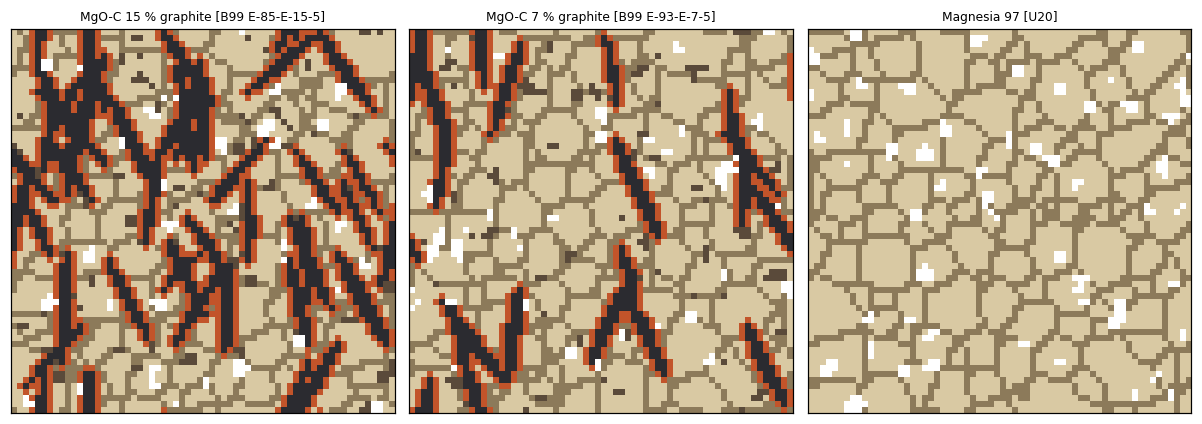

In [22]:
CALE = []
rng_c = np.random.default_rng(4242)
CAL_TAG = dict(zip(CALG, ["MgOC15", "MgOC07", "MAG97"]))
for g, spec in CALG.items():
    tag = CAL_TAG[g]
    for r in range(CONFIG["N_REAL_CAL"]):
        CALE.append(dict(rve_id=f"CAL_{tag}_r{r:02d}", grade=g, family=spec["family"], params=spec["params"],
                         load=dict(RANKED_LOAD), seed=int(rng_c.integers(1, 2**31 - 1)), N=CONFIG["N_PIXELS"],
                         L_mm=CONFIG["L_MM"], grain_source="kanapy", kanapy_nsteps=300, micro_dir=P["MICRO"]))
t0 = time.time()
MIC = dict(zip([e["rve_id"] for e in CALE], par(make_microstructure, CALE)))
print(f"{len(CALE)} calibration realizations ready ({time.time() - t0:.0f} s)")
GR = {g: [e for e in CALE if e["grade"] == g] for g in CALG}
G15, G07, GMG = list(CALG)
ph_of = lambda e: MIC[e["rve_id"]][0]
display(pd.DataFrame([dict(grade=e["grade"], porosity=(ph_of(e) == 0).mean(), graphite=(ph_of(e) == 3).mean(),
                           grains=len(np.unique(MIC[e["rve_id"]][1]))) for e in CALE]).groupby("grade").agg(["mean", "std"]).round(4))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
PH_COLORS = ["#ffffff", "#d9c9a3", "#8c7a5a", "#2b2b30", "#c2542a", "#7fa3d1", "#e8e2d0", "#9c9580", "#5a4a3a"]
PH_CMAP = ListedColormap(PH_COLORS)
def show_phase(ax, ph, title=""):
    ax.imshow(ph, cmap=PH_CMAP, vmin=-0.5, vmax=8.5, origin="lower", interpolation="nearest")
    ax.set_title(title, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
for a, g in zip(axes, CALG):
    show_phase(a, ph_of(GR[g][0]), g)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "calibration_microstructures.png"), dpi=200); plt.show()

In [23]:
from scipy.optimize import brentq
cal_path = os.path.join(P["CAL"], "cal.json")
def E_mean(g, cal):
    v = [youngs_modulus(*props_of(ph_of(e), e["family"], e["params"], cal)) / 1000 for e in GR[g]]
    return float(np.mean(v)), float(np.std(v))
def E_of_job(args):
    e, cal = args
    return youngs_modulus(*props_of(ph_of(e), e["family"], e["params"], cal)) / 1000
def strength_job(args):
    e, cal = args
    return tension_sla(*props_of(ph_of(e), e["family"], e["params"], cal))["strength"]

if os.path.exists(cal_path) and not CONFIG["RECALIBRATE"]:
    CALREC = json.load(open(cal_path)); CAL = CALREC["cal"]
    print("calibration loaded from", cal_path)
else:
    t0 = time.time()
    tgt_E = B99["E-85-E-15-5"]["E_GPa"]
    ls = brentq(lambda x: np.mean(par(E_of_job, [(e, dict(CAL0, s_b=10 ** x)) for e in GR[G15]])) - tgt_E, -4.0, 0.0, xtol=1e-4)
    CAL = dict(CAL0, s_b=10 ** ls)
    print(f"s_b = {CAL['s_b']:.4g} ({time.time() - t0:.0f} s)")
    st15 = par(strength_job, [(e, dict(CAL, k_f=1.0)) for e in GR[G15]])
    st07 = par(strength_job, [(e, dict(CAL, k_f=1.0)) for e in GR[G07]])
    CAL["k_f"] = float(B99["E-85-E-15-5"]["MOR"] / np.mean(st15))
    print(f"k_f = {CAL['k_f']:.4f} ({time.time() - t0:.0f} s)")
    # creep master curves of the magnesia realizations for every exponent of the grid
    def master_job(args):
        e, n = args
        return creep_master_curve(ph_of(e), e["family"], e["params"], CAL, n)
    jobs = [(e, n) for n in CONFIG["CREEP_N_GRID"] for e in GR[GMG]]
    curves = par(master_job, jobs)
    MASTERS = {n: [c for (e, nn), c in zip(jobs, curves) if nn == n] for n in CONFIG["CREEP_N_GRID"]}
    pickle.dump(MASTERS, open(os.path.join(P["CAL"], "creep_masters.pkl"), "wb"))
    best, table = fit_creep(MASTERS, [r for r in u20_targets() if r["T_C"] in (1350, 1425)], CONFIG["CREEP_N_GRID"])
    CAL.update(A_ref=float(10 ** best["log10_A_ref"]), n=float(best["n"]), Q=float(best["Q_kJ"] * 1e3))
    CALREC = dict(cal=CAL, creep_fit=[{k: v for k, v in d.items() if k not in ("model", "x")} for d in table],
                  strength_kf1={"15": list(map(float, st15)), "07": list(map(float, st07))}, time_s=time.time() - t0)
    json.dump(CALREC, open(cal_path, "w"), indent=1)
    print(f"calibration finished in {time.time() - t0:.0f} s -> {cal_path}")
MASTERS = pickle.load(open(os.path.join(P["CAL"], "creep_masters.pkl"), "rb"))
display(pd.DataFrame(CALREC["creep_fit"]).round(3))
cal_tab = pd.DataFrame([
    ("s_b", f"{CAL['s_b']:.4g}", "boundary stiffness / matrix stiffness", "E of MgO-C 15 % [B99]"),
    ("k_f", f"{CAL['k_f']:.4g}", "scale of local strengths and fracture energies", "MOR of MgO-C 15 % [B99]"),
    ("A_ref", f"{CAL['A_ref']:.3e}", f"Norton prefactor of MgO at {T_REF_C:.0f} C [MPa^-n s^-1]", "creep 1350/1425 C [U20]"),
    ("n", f"{CAL['n']:.2f}", "Norton stress exponent", "creep 1350/1425 C [U20]"),
    ("Q", f"{CAL['Q'] / 1e3:.0f} kJ/mol", "activation energy", "creep 1350/1425 C [U20]")],
    columns=["parameter", "value", "meaning", "calibrated on"]).set_index("parameter")
display(cal_tab)
print(f"boundary modulus E_b = {CAL['s_b'] * BASE['MGO']['E'] / 1000:.2f} GPa; local strengths: "
      f"MgO {BASE['MGO']['ft'] * CAL['k_f']:.1f} MPa, interface (k_itf 0.3) {0.3 * BASE['MGO']['ft'] * CAL['k_f']:.1f} MPa")

calibration loaded from MR_RVE_work/calibration/cal.json


,n,log10_A_ref,Q_kJ,rms_dex
0,1.00,-6.700,259.722,0.074
1,1.25,-6.904,264.446,0.063
2,1.50,-7.109,269.185,0.056
3,1.75,-7.313,273.956,0.053
4,2.00,-7.518,278.786,0.057
5,2.50,-7.928,288.743,0.075
6,3.00,-8.338,299.268,0.100


,value,meaning,calibrated on
parameter,,,
s_b,0.01035,boundary stiffness / matrix stiffness,E of MgO-C 15 % [B99]
k_f,0.8006,scale of local strengths and fracture energies,MOR of MgO-C 15 % [B99]
A_ref,4.865e-08,Norton prefactor of MgO at 1550 C [MPa^-n s^-1],creep 1350/1425 C [U20]
n,1.75,Norton stress exponent,creep 1350/1425 C [U20]
Q,274 kJ/mol,activation energy,creep 1350/1425 C [U20]


boundary modulus E_b = 3.11 GPa; local strengths: MgO 64.0 MPa, interface (k_itf 0.3) 19.2 MPa


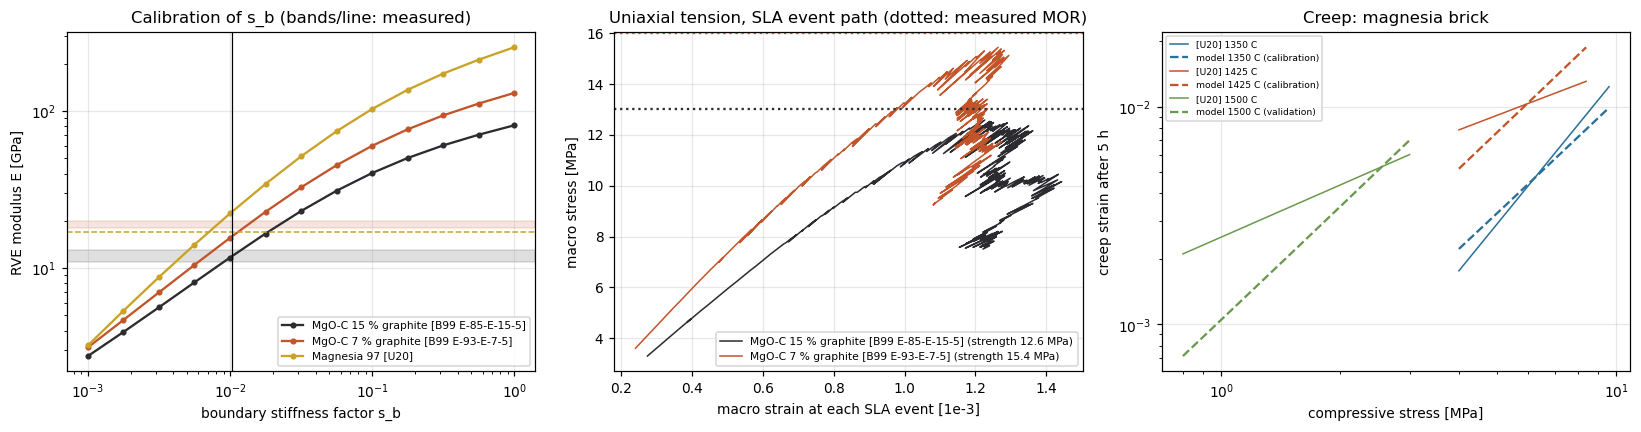

In [24]:
# calibration figures: E(s_b) with the targets, tension curves, creep fit
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sgrid = np.geomspace(1e-3, 1.0, 13)
for g, c in zip(CALG, ["#2b2b30", "#c2542a", "#c9a227"]):
    Em = [np.mean(par(E_of_job, [(e, dict(CAL0, s_b=s)) for e in GR[g][:3]])) for s in sgrid]
    ax[0].plot(sgrid, Em, "o-", color=c, label=g, ms=3)
for key, c in [("E-85-E-15-5", "#2b2b30"), ("E-93-E-7-5", "#c2542a")]:
    ax[0].axhspan(B99[key]["E_GPa"] - B99[key]["E_sd"], B99[key]["E_GPa"] + B99[key]["E_sd"], color=c, alpha=0.15)
ax[0].axhline(U20["E_GPa"], color="#c9a227", ls="--", lw=1); ax[0].axvline(CAL["s_b"], color="k", lw=0.8)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("boundary stiffness factor s_b"); ax[0].set_ylabel("RVE modulus E [GPa]")
ax[0].set_title("Calibration of s_b (bands/line: measured)"); ax[0].legend(fontsize=7)
for g, c in [(G15, "#2b2b30"), (G07, "#c2542a")]:
    th_ = tension_sla(*props_of(ph_of(GR[g][0]), GR[g][0]["family"], GR[g][0]["params"], CAL))
    ax[1].plot(th_["curve"][:, 0] * 1e3, th_["curve"][:, 1], color=c, lw=1, label=f"{g} (strength {th_['strength']:.1f} MPa)")
ax[1].axhline(B99["E-85-E-15-5"]["MOR"], color="#2b2b30", ls=":"); ax[1].axhline(B99["E-93-E-7-5"]["MOR"], color="#c2542a", ls=":")
ax[1].set_xlabel("macro strain at each SLA event [1e-3]"); ax[1].set_ylabel("macro stress [MPa]")
ax[1].set_title("Uniaxial tension, SLA event path (dotted: measured MOR)"); ax[1].legend(fontsize=7)
def creep_pred(T, s, t=U20_TEST_TIME):
    return np.mean([creep_strain_from_master(tm, em, CAL["n"], s, CAL["A_ref"], CAL["Q"], T, t) for tm, em in MASTERS[CAL["n"]]])
cT = {1350: "#2a6f97", 1425: "#c2542a", 1500: "#6a994e"}
for T, d in U20_CREEP.items():
    ss = np.linspace(min(d["stresses"]) * 0.8, max(d["stresses"]) * 1.2, 20)
    ax[2].plot(ss, [nb_creep_strain(d["K"], d["n"], d["a"], s, U20_TEST_TIME) for s in ss], color=cT[T], lw=1, label=f"[U20] {T} C")
    ax[2].plot(ss, [creep_pred(T, s) for s in ss], color=cT[T], ls="--", lw=1.5,
               label=f"model {T} C" + (" (validation)" if T == 1500 else " (calibration)"))
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("compressive stress [MPa]"); ax[2].set_ylabel("creep strain after 5 h")
ax[2].set_title("Creep: magnesia brick"); ax[2].legend(fontsize=6)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "calibration.png"), dpi=200); plt.show()

## 6. Validation on held-out literature data
Acceptance targets (fixed before the comparison, typical of engineering models of refractories): relative error
≤ 25 % for moduli and strength ratios, ≤ 0.3 dex (factor 2) for creep strains. The **uncalibrated** model (dense-phase
data) is shown for reference.

,quantity,source,measured,measured_sd,model,model_sd,uncalibrated,error,error_unit,role,within_target
0,"E, MgO-C 15 % (calibration)",B99,12.0000,1.000,12.0000,0.3212,81.5796,-0.0000,relative,calibration,True
1,"E, MgO-C 7 %",B99,19.0000,1.000,15.9688,0.9164,133.1322,-0.1595,relative,validation,True
2,"E, magnesia 97",U20,17.0000,NaN,22.0860,1.2941,254.9898,0.2992,relative,validation,False
3,strength ratio 7 % / 15 % graphite,B99,1.2308,0.122,1.1611,0.0982,NaN,-0.0566,relative,validation,True
4,"creep strain 5 h, 1350 C, 5.0 MPa (calibration)",U20,0.0029,NaN,0.0032,NaN,NaN,0.0492,dex,calibration,True
5,"creep strain 5 h, 1350 C, 6.0 MPa (calibration)",U20,0.0043,NaN,0.0044,NaN,NaN,0.0080,dex,calibration,True
6,"creep strain 5 h, 1350 C, 8.0 MPa (calibration)",U20,0.0082,NaN,0.0072,NaN,NaN,-0.0562,dex,calibration,True
7,"creep strain 5 h, 1425 C, 5.0 MPa (calibration)",U20,0.0091,NaN,0.0076,NaN,NaN,-0.0781,dex,calibration,True
8,"creep strain 5 h, 1425 C, 6.0 MPa (calibration)",U20,0.0104,NaN,0.0104,NaN,NaN,0.0040,dex,calibration,True
9,"creep strain 5 h, 1425 C, 7.0 MPa (calibration)",U20,0.0115,NaN,0.0136,NaN,NaN,0.0736,dex,calibration,True


validation: 4 of 6 quantities within the acceptance target
PASS  Validation: E, MgO-C 7 % [B99] within target   [error -0.16 relative]
FAIL  Validation: E, magnesia 97 [U20] within target   [error +0.30 relative]
PASS  Validation: strength ratio 7 % / 15 % graphite [B99] within target   [error -0.06 relative]
FAIL  Validation: creep strain 5 h, 1500 C, 1.0 MPa [U20] within target   [error -0.38 dex]
PASS  Validation: creep strain 5 h, 1500 C, 1.5 MPa [U20] within target   [error -0.22 dex]
PASS  Validation: creep strain 5 h, 1500 C, 2.5 MPa [U20] within target   [error -0.01 dex]


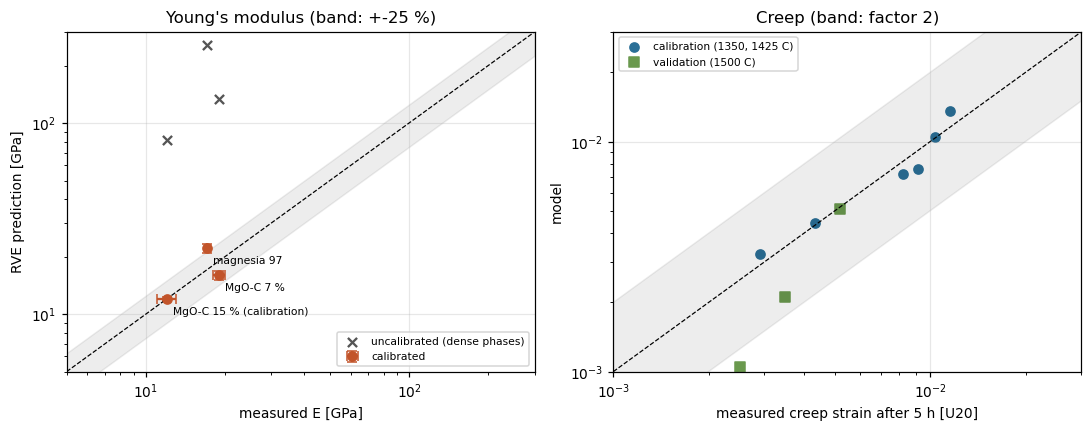

In [25]:
def summarize(vals):
    return float(np.mean(vals)), float(np.std(vals))
E07, E07s = summarize(par(E_of_job, [(e, CAL) for e in GR[G07]]))
EMG, EMGs = summarize(par(E_of_job, [(e, CAL) for e in GR[GMG]]))
E15, E15s = summarize(par(E_of_job, [(e, CAL) for e in GR[G15]]))
E07u = np.mean(par(E_of_job, [(e, CAL0) for e in GR[G07]])); EMGu = np.mean(par(E_of_job, [(e, CAL0) for e in GR[GMG]]))
E15u = np.mean(par(E_of_job, [(e, CAL0) for e in GR[G15]]))
st15 = np.array(CALREC["strength_kf1"]["15"]) * CAL["k_f"]; st07 = np.array(CALREC["strength_kf1"]["07"]) * CAL["k_f"]
ratio_m = st07.mean() / st15.mean()
ratio_e = B99["E-93-E-7-5"]["MOR"] / B99["E-85-E-15-5"]["MOR"]
ratio_es = ratio_e * np.hypot(B99["E-93-E-7-5"]["MOR_sd"] / B99["E-93-E-7-5"]["MOR"], B99["E-85-E-15-5"]["MOR_sd"] / B99["E-85-E-15-5"]["MOR"])
rows = [dict(quantity="E, MgO-C 15 % (calibration)", source="B99", measured=12.0, measured_sd=1.0, model=E15, model_sd=E15s, uncalibrated=E15u, kind="rel"),
        dict(quantity="E, MgO-C 7 %", source="B99", measured=19.0, measured_sd=1.0, model=E07, model_sd=E07s, uncalibrated=E07u, kind="rel"),
        dict(quantity="E, magnesia 97", source="U20", measured=17.0, measured_sd=np.nan, model=EMG, model_sd=EMGs, uncalibrated=EMGu, kind="rel"),
        dict(quantity="strength ratio 7 % / 15 % graphite", source="B99", measured=ratio_e, measured_sd=ratio_es, model=ratio_m,
             model_sd=ratio_m * np.hypot(st07.std() / st07.mean(), st15.std() / st15.mean()), uncalibrated=np.nan, kind="rel")]
for r in u20_targets():
    m_ = creep_pred(r["T_C"], r["sigma"])
    rows.append(dict(quantity=f"creep strain 5 h, {r['T_C']} C, {r['sigma']} MPa" + (" (calibration)" if r["T_C"] < 1500 else ""),
                     source="U20", measured=r["eps"], measured_sd=np.nan, model=m_, model_sd=np.nan, uncalibrated=np.nan, kind="log"))
VAL = pd.DataFrame(rows)
VAL["error"] = np.where(VAL.kind == "rel", VAL.model / VAL.measured - 1, np.log10(VAL.model / VAL.measured))
VAL["error_unit"] = np.where(VAL.kind == "rel", "relative", "dex")
VAL["role"] = np.where(VAL.quantity.str.contains("calibration"), "calibration", "validation")
VAL["within_target"] = np.where(VAL.kind == "rel", VAL.error.abs() <= 0.25, VAL.error.abs() <= 0.30)
display(VAL.drop(columns="kind").round(4))
vv = VAL[VAL.role == "validation"]
print(f"validation: {vv.within_target.sum()} of {len(vv)} quantities within the acceptance target")
for _, r in vv.iterrows():
    check(f"Validation: {r.quantity} [{r.source}] within target", r.within_target, f"error {r.error:+.2f} {r.error_unit}")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ve = VAL[VAL.quantity.str.startswith("E,")]
ax[0].errorbar(ve.measured, ve.model, xerr=ve.measured_sd.fillna(0), yerr=ve.model_sd, fmt="o", color="#c2542a", label="calibrated", capsize=3)
ax[0].scatter(ve.measured, ve.uncalibrated, marker="x", color="#555", label="uncalibrated (dense phases)")
for _, r in ve.iterrows():
    ax[0].annotate(r.quantity.replace("E, ", ""), (r.measured, r.model), fontsize=7, xytext=(4, -10), textcoords="offset points")
lim = [5, 300]; ax[0].plot(lim, lim, "k--", lw=0.8); ax[0].fill_between(lim, [l * 0.75 for l in lim], [l * 1.25 for l in lim], color="k", alpha=0.07)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("measured E [GPa]"); ax[0].set_ylabel("RVE prediction [GPa]"); ax[0].legend(fontsize=7); ax[0].set_title("Young's modulus (band: +-25 %)")
vc = VAL[VAL.kind == "log"]
for role, mk_, c_ in [("calibration", "o", "#2a6f97"), ("validation", "s", "#6a994e")]:
    s_ = vc[vc.role == role]
    ax[1].scatter(s_.measured, s_.model, marker=mk_, color=c_, label=role + (" (1350, 1425 C)" if role == "calibration" else " (1500 C)"))
from matplotlib.ticker import NullFormatter
for a in ax:
    a.xaxis.set_minor_formatter(NullFormatter()); a.yaxis.set_minor_formatter(NullFormatter())
lim = [1e-3, 3e-2]; ax[1].plot(lim, lim, "k--", lw=0.8); ax[1].fill_between(lim, [l / 2 for l in lim], [l * 2 for l in lim], color="k", alpha=0.07)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_xlabel("measured creep strain after 5 h [U20]"); ax[1].set_ylabel("model"); ax[1].legend(fontsize=7); ax[1].set_title("Creep (band: factor 2)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "validation.png"), dpi=200); plt.show()

In [26]:
# consistency checks that are not validation targets (different test conditions or quantities)
mg15 = GR[G15]
a15 = np.mean([alpha_eff(*props_of(ph_of(e), e["family"], e["params"], CAL)) for e in mg15]) * 1e6
aMG = np.mean([alpha_eff(*props_of(ph_of(e), e["family"], e["params"], CAL)) for e in GR[GMG]]) * 1e6
print(f"effective CTE (handbook phase values = 20-1000 C means): MgO-C 15 % {a15:.1f} ppm/K, magnesia {aMG:.1f} ppm/K")
print(f"  [Bz15] commercial MgO-C (12-14 % C) at 300 C: {Bz15['A']['alpha_300C'] * 1e6:.1f}-{Bz15['B']['alpha_300C'] * 1e6:.1f} ppm/K; "
      f"[U20] magnesia (FE input value): {U20['alpha'] * 1e6:.1f} ppm/K")
print("  -> different reference temperatures; the comparison indicates the order of magnitude only.")
print(f"local fracture parameters after calibration: G_F(MgO) = {BASE['MGO']['GF'] * CAL['k_f'] ** 2 * 1000:.0f} N/m, "
      f"G_F(graphite) = {BASE['GRAPHITE']['GF'] * CAL['k_f'] ** 2 * 1000:.0f} N/m;  [S19] brick-scale MgO-C: G_f = {S19['Gf_RT']:.0f} N/m (RT), "
      f"{S19['Gf_inv'][1100]:.0f}-{S19['Gf_inv'][1470]:.0f} N/m (1100-1470 C) - the brick value contains aggregate-scale bridging and branching")
# model-form check: separate stiffness factors for grain boundaries (from the magnesia modulus) and interfaces (MgO-C 15 %)
def E_two(g, s_gb, s_itf):
    vals = []
    for e in GR[g][:5]:
        mats = materials_cal(e["family"], e["params"], dict(CAL0, s_b=s_gb))
        mats["ITF"]["E"] = BASE["MGO"]["E"] * s_itf
        mesh = PixelMesh(ph_of(e)); vals.append(youngs_modulus(mesh, element_props(mesh, mats, PHASES)) / 1000)
    return np.mean(vals)
s_gb2 = 10 ** brentq(lambda x: E_two(GMG, 10 ** x, 1.0) - U20["E_GPa"], -4, 0, xtol=1e-4)
s_itf2 = 10 ** brentq(lambda x: E_two(G15, s_gb2, 10 ** x) - 12.0, -6, 0, xtol=1e-4)
print(f"model-form check (two boundary stiffnesses): s_gb = {s_gb2:.4g}, s_itf = {s_itf2:.4g} -> E(MgO-C 7 %) = {E_two(G07, s_gb2, s_itf2):.1f} GPa "
      f"(one-parameter model: {E07:.1f} GPa; measured 19 +- 1 GPa)")

effective CTE (handbook phase values = 20-1000 C means): MgO-C 15 % 11.0 ppm/K, magnesia 13.5 ppm/K
  [Bz15] commercial MgO-C (12-14 % C) at 300 C: 8.6-10.8 ppm/K; [U20] magnesia (FE input value): 7.9 ppm/K
  -> different reference temperatures; the comparison indicates the order of magnitude only.
local fracture parameters after calibration: G_F(MgO) = 13 N/m, G_F(graphite) = 32 N/m;  [S19] brick-scale MgO-C: G_f = 240 N/m (RT), 162-563 N/m (1100-1470 C) - the brick value contains aggregate-scale bridging and branching
model-form check (two boundary stiffnesses): s_gb = 0.007577, s_itf = 0.013 -> E(MgO-C 7 %) = 14.4 GPa (one-parameter model: 16.0 GPa; measured 19 +- 1 GPa)


## 7. Dataset: 320 Kanapy RVEs with the calibrated model
Latin-hypercube design over the microstructure parameters of each family (table) plus the creep load
(1–8 MPa, 1350–1550 °C: the calibration and validation range of the creep law, 1350–1500 °C, plus the service temperature). **Every RVE uses a Kanapy grain structure.** Each RVE: homogenisation (E₀, α_eff), thermal shock at
the five ΔT levels, creep for 10 h, and (optionally) the uniaxial tensile strength. Results are cached per RVE; the
cell can be interrupted and re-run.

In [27]:
design = build_design(CONFIG["N_PER_FAMILY"], N=CONFIG["N_PIXELS"], L_mm=CONFIG["L_MM"], seed=CONFIG["DESIGN_SEED"])
for e in design:
    e.update(rve_id="K" + e["rve_id"], grain_source="kanapy", kanapy_nsteps=300, micro_dir=P["MICRO"])
json.dump(design, open(os.path.join(P["SIMC"], "..", "design_kanapy.json"), "w"))
print(len(design), "design RVEs:", {f: sum(d["family"] == f for d in design) for f in FAMILIES})
display(pd.DataFrame([{"family": FAMILY_LABEL[f], **{k: f"{a:g}-{b:g}" for k, (a, b) in r.items()}} for f, r in PARAM_RANGES.items()]).set_index("family").fillna("-"))
def sim_job(e):
    return simulate_rve(e, P["SIMC"], cal=CAL, dt_levels=CONFIG["DT_LEVELS"], tension=CONFIG["TENSION_IN_DATASET"])
missing = [e for e in design if not os.path.exists(os.path.join(P["SIMC"], e["rve_id"] + ".npz"))]
print(f"cached: {len(design) - len(missing)} / {len(design)}")
if missing and CONFIG["RUN_SIMULATIONS"]:
    t0 = time.time()
    for k in range(0, len(missing), 2 * CONFIG["N_JOBS"]):
        batch = missing[k:k + 2 * CONFIG["N_JOBS"]]
        par(sim_job, batch)
        print(f"  {min(k + len(batch), len(missing))}/{len(missing)} simulated, {time.time() - t0:.0f} s", flush=True)
df, PH, DAM, CEEQ, LEVELS, CTIMES = load_sim_results(P["SIMC"])
print(df.shape[0], "RVEs loaded:", df.family.value_counts().to_dict(), "| grain source:", df.grain_source.unique())
finite = np.isfinite(df.select_dtypes("number").drop(columns=["sigma_t"]).values).all() and np.isfinite(DAM).all() and np.isfinite(CEEQ).all()
check("Dataset: all values finite", finite)
check("Dataset: every RVE has a Kanapy grain structure", (df.grain_source == "kanapy").all())
check("Dataset: SLA cap reached in < 5 % of RVEs", df.sla_capped.mean() < 0.05, f"{df.sla_capped.mean():.1%}")

320 design RVEs: {'MGOC': 80, 'MGOZR': 80, 'MAG': 80, 'ALC': 80}


,f_second,flake_len_um,aspect,orient_sd,porosity,grain_um,binder,k_gb,k_itf,part_um,pore_um
family,,,,,,,,,,,
MgO-C,0.1-0.3,120-400,5-12,0.1-1.2,0.02-0.08,60-160,0-0.05,0.4-0.8,0.15-0.6,-,-
MgO-ZrO2,0.05-0.25,-,-,-,0.08-0.18,60-160,-,0.4-0.8,0.5-1,30-90,-
Magnesia,-,-,-,-,0.1-0.2,60-160,-,0.4-0.8,-,-,20-60
Al2O3-C,0.1-0.25,120-400,5-12,0.1-1.2,0.02-0.08,40-120,0-0.05,0.4-0.8,0.15-0.6,-,-


cached: 320 / 320
320 RVEs loaded: {'MGOC': 80, 'MGOZR': 80, 'MAG': 80, 'ALC': 80} | grain source: ['kanapy']
PASS  Dataset: all values finite
PASS  Dataset: every RVE has a Kanapy grain structure
PASS  Dataset: SLA cap reached in < 5 % of RVEs   [0.0%]


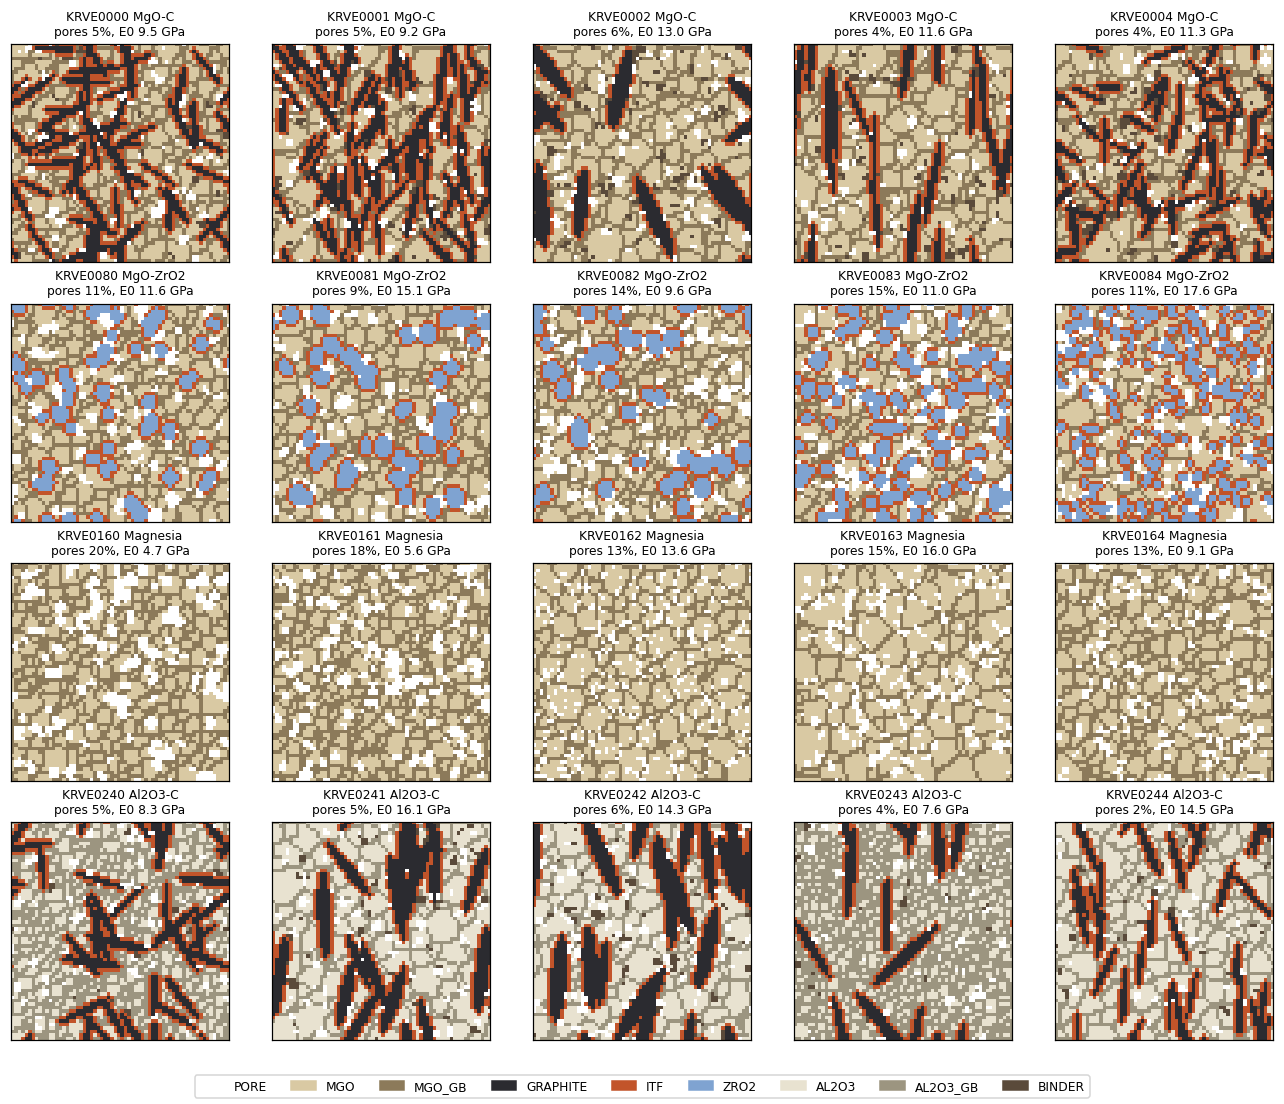

In [28]:
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for r_, fam in enumerate(FAMILIES):
    ids_ = np.where(df.family.values == fam)[0][:5]
    for c_, i in enumerate(ids_):
        show_phase(axes[r_, c_], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[fam]}\npores {df.vf_PORE[i]:.0%}, E0 {df.E0_eff_GPa[i]:.1f} GPa")
from matplotlib.patches import Patch
fig.legend([Patch(color=PH_COLORS[k]) for k in range(N_PHASES)], [PHASES[k] for k in range(N_PHASES)], loc="lower center", ncol=9, fontsize=8)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(os.path.join(FIG, "rve_gallery_kanapy.png"), dpi=200); plt.show()

In [29]:
# SLA step convergence with the calibrated model: production event strategy vs 3-5x finer steps
rows = []
for fam in FAMILIES:
    e = [d for d in design if d["family"] == fam][1]
    ph = make_microstructure(e)[0]
    mesh, props = props_of(ph, fam, e["params"], CAL)
    a = thermal_shock_sla(mesh, props, LEVELS)
    b = thermal_shock_sla(mesh, props, LEVELS, band=0.01, band_cascade=0.05, max_solves=20000)
    for k, lv in enumerate(LEVELS):
        rows.append(dict(family=FAMILY_LABEL[fam], dT=lv, E_ratio_prod=a["snaps"][k]["E_ratio"], E_ratio_fine=b["snaps"][k]["E_ratio"]))
conv = pd.DataFrame(rows)
conv["abs_dlog"] = (np.log10(conv.E_ratio_prod) - np.log10(conv.E_ratio_fine)).abs()
iqr = {(FAMILY_LABEL[f], l): float(np.subtract(*np.percentile(np.log10(df[df.family == f][f"E_ratio_{int(l)}"]), [75, 25])))
       for f in FAMILIES for l in LEVELS}
conv["IQR_realizations"] = [iqr[(a_, b_)] for a_, b_ in zip(conv.family, conv.dT)]
display(conv.round(3))
check("SLA: event-step error below the scatter between microstructures (median)", conv.abs_dlog.median() < conv.IQR_realizations.median(),
      f"{conv.abs_dlog.median():.3f} vs {conv.IQR_realizations.median():.3f} dex")

,family,dT,E_ratio_prod,E_ratio_fine,abs_dlog,IQR_realizations
0,MgO-C,25.0,1.000,1.000,0.000,0.001
1,MgO-C,50.0,0.991,0.991,0.000,0.010
2,MgO-C,100.0,0.895,0.902,0.003,0.050
3,MgO-C,200.0,0.183,0.173,0.025,0.448
4,MgO-C,400.0,0.068,0.067,0.009,0.283
5,MgO-ZrO2,25.0,1.000,1.000,0.000,0.000
6,MgO-ZrO2,50.0,0.967,0.968,0.000,0.033
7,MgO-ZrO2,100.0,0.826,0.833,0.004,0.134
8,MgO-ZrO2,200.0,0.087,0.188,0.336,0.391
9,MgO-ZrO2,400.0,0.024,0.031,0.105,0.243


PASS  SLA: event-step error below the scatter between microstructures (median)   [0.002 vs 0.071 dex]


## 8. Physics in the data

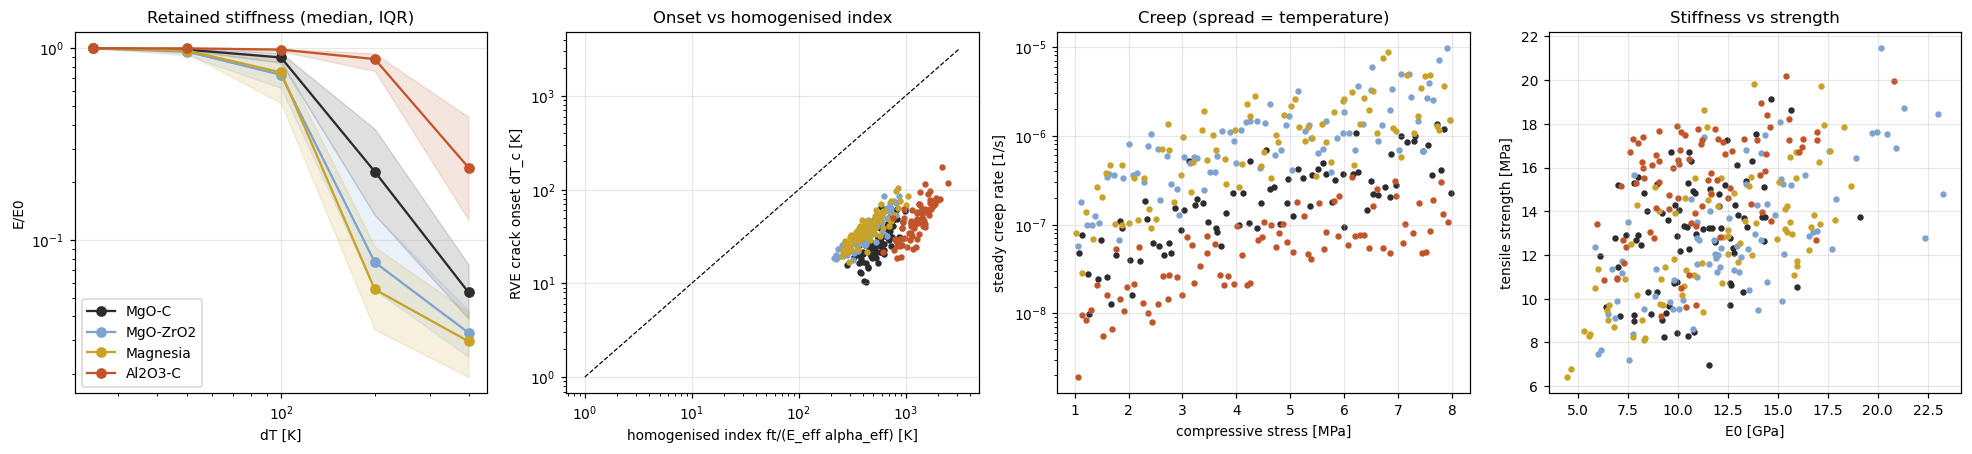

,E_ratio_25,E_ratio_50,E_ratio_100,E_ratio_200,E_ratio_400,dTc,E0_eff_GPa,sigma_t
family,,,,,,,,
Al2O3-C,1.0,0.999,0.984,0.879,0.239,48.349,10.767,15.988
Magnesia,1.0,0.972,0.749,0.055,0.030,34.171,12.086,12.858
MgO-C,1.0,0.984,0.896,0.227,0.053,26.212,10.631,13.194
MgO-ZrO2,1.0,0.960,0.727,0.077,0.033,32.028,12.690,12.392


,MgO-C,magnesia
25 K,1.000,1.000
50 K,0.984,0.972
100 K,0.896,0.749
200 K,0.227,0.055
400 K,0.053,0.030


PASS  Physics: MgO-C retains more stiffness than magnesia after a moderate shock (100 K)   [0.90 vs 0.75]
At the largest shocks a through-crack crosses the 1 mm RVE in both families, so E/E0 of a single RVE no longer discriminates; brick-scale retained stiffness needs aggregate-scale RVEs (Section 14).


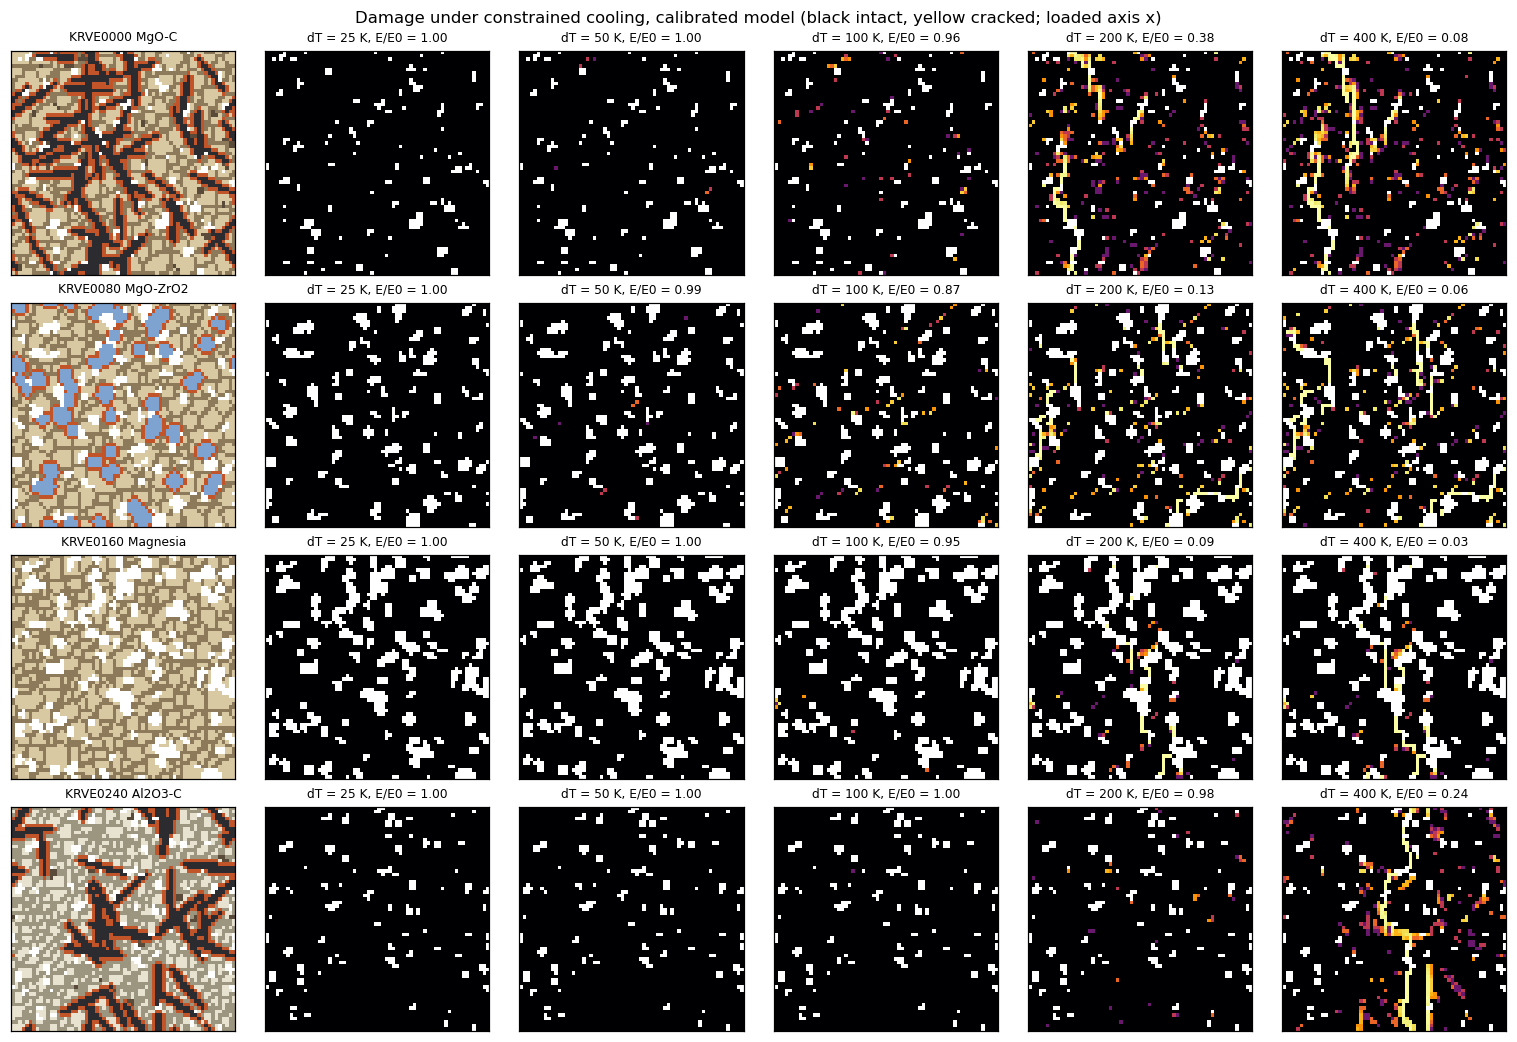

In [30]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
cols = {"MGOC": "#2b2b30", "MGOZR": "#7fa3d1", "MAG": "#c9a227", "ALC": "#c2542a"}
for fam in FAMILIES:
    sub = df[df.family == fam]
    E = np.array([sub[f"E_ratio_{int(l)}"] for l in LEVELS])
    ax[0].plot(LEVELS, np.median(E, 1), "o-", color=cols[fam], label=FAMILY_LABEL[fam])
    ax[0].fill_between(LEVELS, np.percentile(E, 25, 1), np.percentile(E, 75, 1), color=cols[fam], alpha=0.15)
    ax[1].scatter(sub.R_hom, sub.dTc, s=10, color=cols[fam], label=FAMILY_LABEL[fam])
    ax[2].scatter(sub.creep_stress, -sub.creep_rate, s=10, c=cols[fam])
    if np.isfinite(sub.sigma_t).any():
        ax[3].scatter(sub.E0_eff_GPa, sub.sigma_t, s=10, c=cols[fam])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("dT [K]"); ax[0].set_ylabel("E/E0"); ax[0].legend(); ax[0].set_title("Retained stiffness (median, IQR)")
lim = [1, max(df.R_hom.max(), df.dTc.max()) * 1.3]
ax[1].plot(lim, lim, "k--", lw=0.8); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("homogenised index ft/(E_eff alpha_eff) [K]"); ax[1].set_ylabel("RVE crack onset dT_c [K]"); ax[1].set_title("Onset vs homogenised index")
ax[2].set_yscale("log"); ax[2].set_xlabel("compressive stress [MPa]"); ax[2].set_ylabel("steady creep rate [1/s]"); ax[2].set_title("Creep (spread = temperature)")
ax[3].set_xlabel("E0 [GPa]"); ax[3].set_ylabel("tensile strength [MPa]"); ax[3].set_title("Stiffness vs strength")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "physics_overview.png"), dpi=200); plt.show()
med = df.groupby("family")[[f"E_ratio_{int(l)}" for l in LEVELS] + ["dTc", "E0_eff_GPa", "sigma_t"]].median()
display(med.rename(index=FAMILY_LABEL).round(3))
REF = f"E_ratio_{int(LEVELS[2])}"
cmp_ = pd.DataFrame({"MgO-C": med.loc["MGOC", [f"E_ratio_{int(l)}" for l in LEVELS]].values,
                     "magnesia": med.loc["MAG", [f"E_ratio_{int(l)}" for l in LEVELS]].values}, index=[f"{l:.0f} K" for l in LEVELS])
display(cmp_.round(3))
check(f"Physics: MgO-C retains more stiffness than magnesia after a moderate shock ({LEVELS[2]:.0f} K)",
      med.loc["MGOC", REF] > med.loc["MAG", REF], f"{med.loc['MGOC', REF]:.2f} vs {med.loc['MAG', REF]:.2f}")
print("At the largest shocks a through-crack crosses the 1 mm RVE in both families, so E/E0 of a single RVE no longer "
      "discriminates; brick-scale retained stiffness needs aggregate-scale RVEs (Section 14).")
fig, axes = plt.subplots(4, 6, figsize=(14, 9.6))
for r_, fam in enumerate(FAMILIES):
    i = np.where(df.family.values == fam)[0][0]
    show_phase(axes[r_, 0], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[fam]}")
    for k in range(len(LEVELS)):
        axes[r_, k + 1].imshow(np.ma.masked_less(DAM[i, k], 0), cmap="inferno", vmin=0, vmax=1, origin="lower", interpolation="nearest")
        axes[r_, k + 1].set_title(f"dT = {LEVELS[k]:.0f} K, E/E0 = {df.loc[i, f'E_ratio_{int(LEVELS[k])}']:.2f}", fontsize=8)
        axes[r_, k + 1].set_xticks([]); axes[r_, k + 1].set_yticks([])
plt.suptitle("Damage under constrained cooling, calibrated model (black intact, yellow cracked; loaded axis x)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "crack_evolution.png"), dpi=200); plt.show()

## 9. ANN: descriptors → scalar properties
Inputs: family, phase fractions, flake geometry and texture, grain size, boundary/interface strength factors,
FE-homogenised modulus and expansion, creep stress and temperature (with log σ and 1/T). Targets (log₁₀): ΔT_c, E/E₀ at
the five levels, tensile strength, steady creep rate, creep strain after 10 h. Validation: 5-fold CV over RVEs and
leave-one-family-out. Reference: random forest; for the thermal-shock targets also the FE-homogenised Hasselman index.

2026-10-16 19:02:06.375107: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


cross-validation 228 s


,ANN_MAE,ANN_R2,RF_MAE,RF_R2,ANN_MAE_LOFO,RF_MAE_LOFO,Hasselman_R2
target,,,,,,,
log10 dT_c,0.079,0.721,0.098,0.592,0.130,0.146,0.443
log10 E/E0 @25K,0.001,0.286,0.001,0.118,0.002,0.001,0.094
log10 E/E0 @50K,0.006,0.741,0.007,0.599,0.009,0.009,0.459
log10 E/E0 @100K,0.089,0.573,0.102,0.374,0.120,0.126,0.263
log10 E/E0 @200K,0.176,0.815,0.194,0.755,0.235,0.327,0.657
log10 E/E0 @400K,0.161,0.790,0.183,0.739,0.260,0.324,0.638
log10 tensile strength,0.041,0.716,0.060,0.401,0.067,0.077,NaN
log10 creep rate,0.074,0.982,0.165,0.907,0.314,0.315,NaN
log10 creep strain 10h,0.071,0.983,0.160,0.908,0.277,0.307,NaN


FAIL  ANN: residual stiffness at 100 K, R2 > 0.7 (5-fold CV)   [0.57]
PASS  ANN: creep rate R2 > 0.9 (5-fold CV)   [0.982]


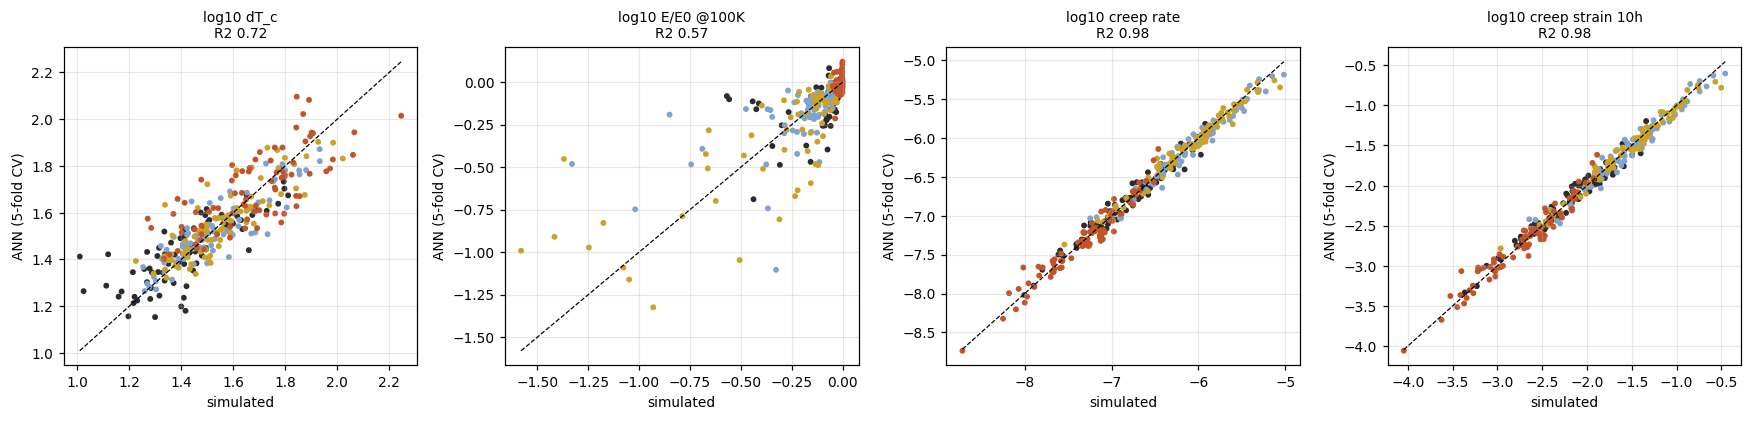

In [31]:
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(CONFIG["TF_THREADS"])
tf.config.threading.set_inter_op_parallelism_threads(1)
import ml_models; importlib.reload(ml_models)
from ml_models import *
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

TARGETS = {"log10 dT_c": np.log10(df.dTc.values)}
for l in LEVELS:
    TARGETS[f"log10 E/E0 @{l:.0f}K"] = np.log10(np.clip(df[f"E_ratio_{int(l)}"].values, 1e-4, None))
if np.isfinite(df.sigma_t).all():
    TARGETS["log10 tensile strength"] = np.log10(df.sigma_t.values)
TARGETS["log10 creep rate"] = np.log10(np.clip(-df.creep_rate.values, 1e-14, None))
TARGETS["log10 creep strain 10h"] = np.log10(np.clip(-df.macro_creep_10h.values, 1e-12, None))
Xd = df[DESC_COLS].values.astype(np.float32)
Yt = np.column_stack(list(TARGETS.values())).astype(np.float32)
tnames = list(TARGETS)

def fit_predict_ann(Xtr, Ytr, Xte, seed):
    sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(Ytr)
    keras.utils.set_random_seed(seed)
    m = build_ann(Xtr.shape[1], Ytr.shape[1])
    m.fit(sx.transform(Xtr), sy.transform(Ytr), validation_split=0.15, epochs=400, batch_size=32, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
    return sy.inverse_transform(m.predict(sx.transform(Xte), verbose=0))

def cv_eval(splits):
    P_ann, P_rf, P_has = np.zeros_like(Yt), np.zeros_like(Yt), np.zeros_like(Yt)
    for k, (tr, te) in enumerate(splits):
        P_ann[te] = fit_predict_ann(Xd[tr], Yt[tr], Xd[te], seed=k)
        P_rf[te] = RandomForestRegressor(300, min_samples_leaf=2, random_state=k, n_jobs=CONFIG["TF_THREADS"]).fit(Xd[tr], Yt[tr]).predict(Xd[te])
        P_has[te] = LinearRegression().fit(np.log10(df.R_hom.values[tr])[:, None], Yt[tr]).predict(np.log10(df.R_hom.values[te])[:, None])
    return P_ann, P_rf, P_has

t0 = time.time()
P_ann, P_rf, P_has = cv_eval(list(KFold(5, shuffle=True, random_state=CONFIG["SEED"]).split(Xd)))
L_ann, L_rf, _ = cv_eval([(np.where(df.family != f)[0], np.where(df.family == f)[0]) for f in FAMILIES])
print(f"cross-validation {time.time() - t0:.0f} s")
res = pd.DataFrame([dict(target=t, ANN_MAE=mean_absolute_error(Yt[:, j], P_ann[:, j]), ANN_R2=r2_score(Yt[:, j], P_ann[:, j]),
                         RF_MAE=mean_absolute_error(Yt[:, j], P_rf[:, j]), RF_R2=r2_score(Yt[:, j], P_rf[:, j]),
                         ANN_MAE_LOFO=mean_absolute_error(Yt[:, j], L_ann[:, j]), RF_MAE_LOFO=mean_absolute_error(Yt[:, j], L_rf[:, j]))
                    for j, t in enumerate(tnames)]).set_index("target")
for j, t in enumerate(tnames[:1 + len(LEVELS)]):
    res.loc[t, "Hasselman_R2"] = r2_score(Yt[:, j], P_has[:, j])
display(res.round(3))
jref = tnames.index(f"log10 E/E0 @{LEVELS[2]:.0f}K")
check(f"ANN: residual stiffness at {LEVELS[2]:.0f} K, R2 > 0.7 (5-fold CV)", res.iloc[jref].ANN_R2 > 0.7, f"{res.iloc[jref].ANN_R2:.2f}")
check("ANN: creep rate R2 > 0.9 (5-fold CV)", res.loc["log10 creep rate", "ANN_R2"] > 0.9, f"{res.loc['log10 creep rate', 'ANN_R2']:.3f}")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.9))
for a, t in zip(ax, [tnames[0], tnames[jref], tnames[-2], tnames[-1]]):
    j = tnames.index(t)
    a.scatter(Yt[:, j], P_ann[:, j], s=8, c=df.family.map(cols).values)
    lo, hi = Yt[:, j].min(), Yt[:, j].max(); a.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    a.set_xlabel("simulated"); a.set_ylabel("ANN (5-fold CV)"); a.set_title(f"{t}\nR2 {res.loc[t, 'ANN_R2']:.2f}", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ann_results.png"), dpi=200); plt.show()

## 10. Shared-encoder dual-head CNN: damage map + creep-strain map
One periodic U-Net encoder, two decoders: a **crack head** (sigmoid damage map, conditioned on ΔT, weighted
cross-entropy) and a **creep head** (standardised log₁₀ creep strain, conditioned on stress, temperature and time, masked
MSE). Targets normalised separately, losses balanced by their initial magnitudes. Split by whole RVE (70/15/15 per
family); augmentation by periodic shifts and mirror images only (exact symmetries of the loading). Baselines: pixel
priors (mean damage / log strain per phase and level in the training set).

PASS  Dual CNN: translation-equivariant; crack head independent of creep conditions   [0.0e+00 / 0.0e+00]
Epoch 1/40
56/56 - 15s - 264ms/step - crack_loss: 0.4015 - creep_loss: 0.3109 - loss: 0.8285 - val_crack_loss: 0.5128 - val_creep_loss: 1.7094 - val_loss: 2.0401 - learning_rate: 0.0020
Epoch 2/40
56/56 - 9s - 167ms/step - crack_loss: 0.2806 - creep_loss: 0.0971 - loss: 0.4880 - val_crack_loss: 0.4235 - val_creep_loss: 2.0321 - val_loss: 2.2094 - learning_rate: 0.0020
Epoch 3/40
56/56 - 9s - 169ms/step - crack_loss: 0.2442 - creep_loss: 0.0696 - loss: 0.4133 - val_crack_loss: 0.3908 - val_creep_loss: 0.3881 - val_loss: 0.8654 - learning_rate: 0.0020
Epoch 4/40
56/56 - 10s - 177ms/step - crack_loss: 0.2147 - creep_loss: 0.0601 - loss: 0.3626 - val_crack_loss: 0.2297 - val_creep_loss: 0.4139 - val_loss: 0.6575 - learning_rate: 0.0020
Epoch 5/40
56/56 - 10s - 182ms/step - crack_loss: 0.2219 - creep_loss: 0.0559 - loss: 0.3700 - val_crack_loss: 0.2557 - val_creep_loss: 0.1723 - val_los

IoU                   F1             cracked_fraction_R2  \
model dual CNN pixel prior dual CNN pixel prior            dual CNN   
dT                                                                    
25.0     0.801       0.792    0.806       0.792               0.040   
50.0     0.387       0.208    0.472       0.208               0.076   
100.0    0.374       0.021    0.521       0.021               0.779   
200.0    0.398       0.000    0.565       0.000               0.792   
400.0    0.384       0.000    0.550       0.000               0.267   

                   
model pixel prior  
dT                 
25.0       -0.137  
50.0       -0.774  
100.0      -1.622  
200.0      -4.975  
400.0      -7.116

,CNN_pixel_R2,prior_pixel_R2,CNN_MAE_dex
t_h,,,
1.0,0.979,0.831,0.149
3.0,0.984,0.861,0.140
10.0,0.986,0.884,0.147


PASS  Dual CNN: crack IoU and creep R2 beat the pixel priors (held-out RVEs)   [IoU 0.47 vs 0.20; R2 0.98]


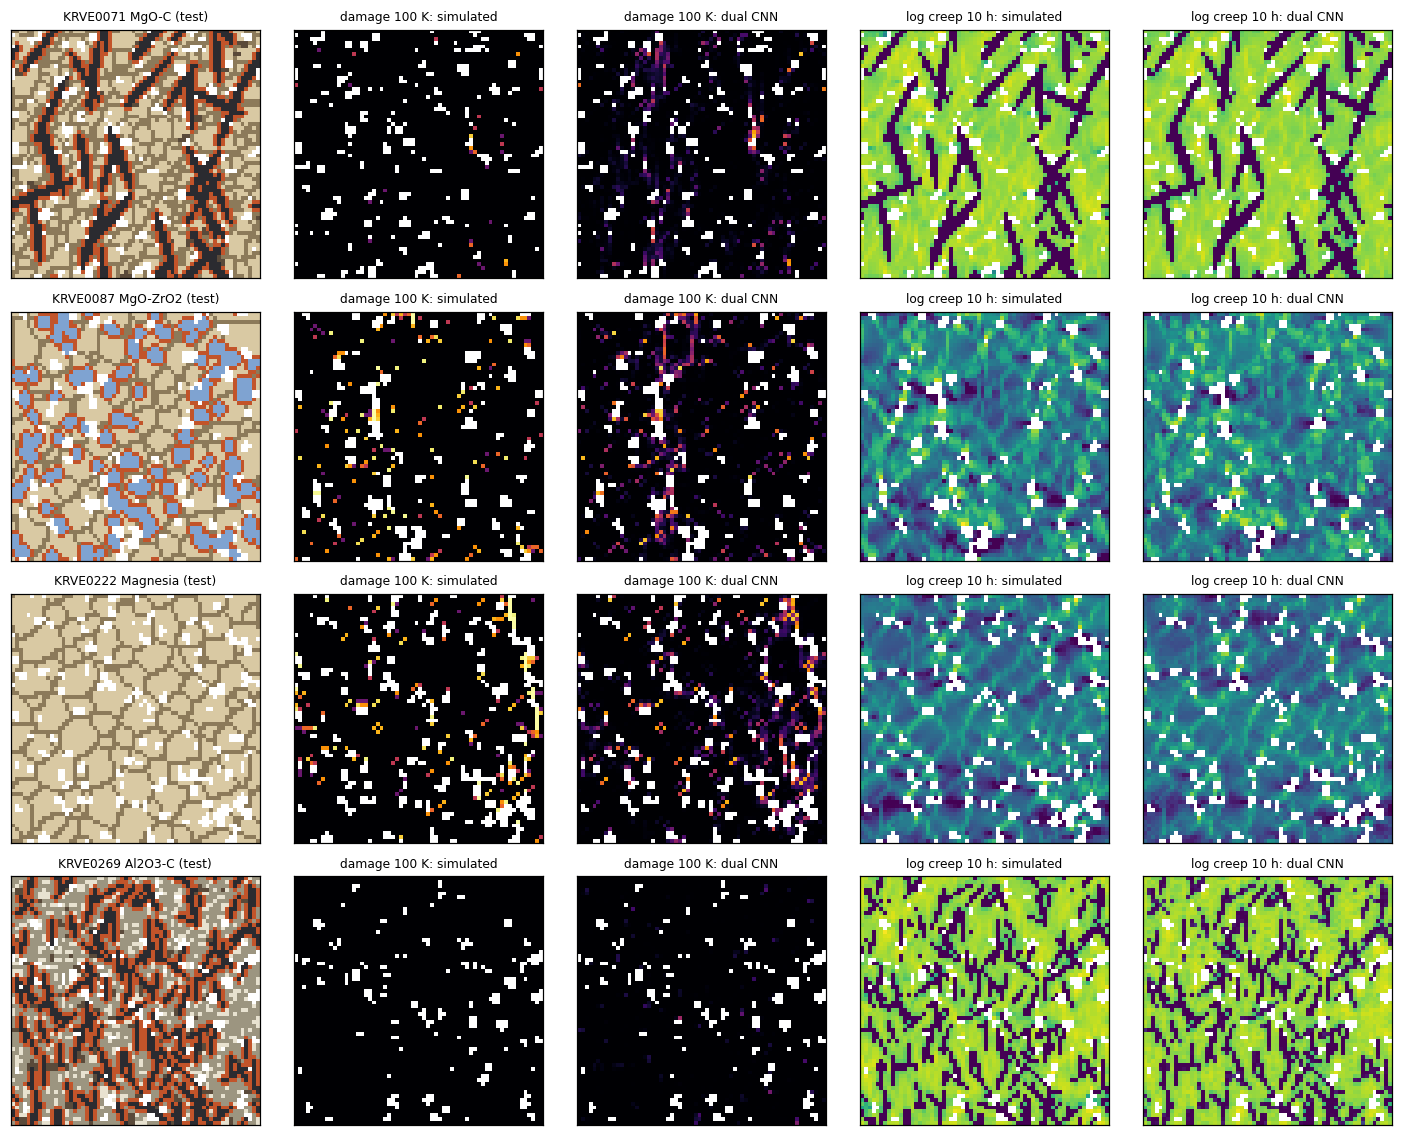

In [32]:
tr_r, va_r, te_r = split_by_rve(len(df), df, seed=CONFIG["SEED"])
OHd, DAMd, LCEd, MASKd, CCK, CCR, mu_d, sd_d = dual_arrays(PH, DAM, CEEQ, df, LEVELS, CTIMES, train_ids=tr_r)
DD = DualData(OHd, DAMd, LCEd, MASKd, CCK, CCR)
v_ids = np.repeat(va_r, len(LEVELS)); v_k = np.tile(np.arange(len(LEVELS)), len(va_r)); v_m = v_k % len(CTIMES)
Xv, Yv = dual_batch(DD, v_ids, v_k, v_m)
keras.utils.set_random_seed(CONFIG["SEED"] + 2)
dual = build_dual_unet(OHd.shape[-1], CCK.shape[1], CCR.shape[2], base=CONFIG["CNN_BASE_FILTERS"], N=CONFIG["N_PIXELS"])
x0, y0 = dual_batch(DD, tr_r[:16], np.zeros(16, int), np.zeros(16, int))
o0 = dual(x0, training=False)
x1 = {k: v.copy() for k, v in x0.items()}; x1["micro"] = np.roll(np.roll(x0["micro"], 8, 1), 24, 2)
o1 = dual(x1, training=False)
eq = max(float(np.abs(np.roll(np.roll(o0[i].numpy(), 8, 1), 24, 2) - o1[i].numpy()).max()) for i in range(2))
x2 = {k: v.copy() for k, v in x0.items()}; x2["cond_creep"] = x2["cond_creep"] * 0 + 0.7
indep = float(np.abs(dual(x2, training=False)[0].numpy() - o0[0].numpy()).max())
check("Dual CNN: translation-equivariant; crack head independent of creep conditions", eq < 1e-5 and indep < 1e-6, f"{eq:.1e} / {indep:.1e}")
loss_ck, loss_cr = masked_bce_weighted(4.0), masked_mse
L0c = float(loss_ck(tf.constant(y0["crack"]), o0[0])); L0r = float(loss_cr(tf.constant(y0["creep"]), o0[1]))
W_CK, W_CR = 1.0 / L0c, 1.0 / L0r
path_dual = os.path.join(P["MOD"], "cnn_dual.keras"); npz_dual = path_dual.replace(".keras", ".weights.npz")
if CONFIG["TRAIN_CNN"] or not os.path.exists(npz_dual):
    dual.compile(optimizer=keras.optimizers.Adam(2e-3), loss={"crack": loss_ck, "creep": loss_cr}, loss_weights={"crack": W_CK, "creep": W_CR})
    cb = [keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    t0 = time.time()
    hist_d = dual.fit(DualSeq(OHd, DAMd, LCEd, MASKd, CCK, CCR, tr_r, batch=16, repeats=4, seed=5), validation_data=(Xv, Yv),
                      epochs=CONFIG["DUAL_EPOCHS"], verbose=2, callbacks=cb)
    print(f"training time {time.time() - t0:.0f} s")
    save_weights_npz(dual, npz_dual); json.dump(hist_d.history, open(path_dual + ".history.json", "w"))
    json.dump({"mu": mu_d, "sd": sd_d, "w_crack": W_CK, "w_creep": W_CR}, open(path_dual + ".scaling.json", "w"))
else:
    dual = load_weights_npz(dual, npz_dual); print("loaded trained weights:", npz_dual)

def dual_predict(model, ids, src, k, m):
    x, _ = dual_batch(src, np.asarray(ids), np.full(len(ids), k), np.full(len(ids), m))
    pc, pr = model.predict(x, batch_size=32, verbose=0)
    return pc[..., 0], pr[..., 0] * sd_d + mu_d
# pixel priors from the training RVEs
prior_c = np.zeros((len(LEVELS), N_PHASES)); prior_r = np.zeros((len(CTIMES), N_PHASES))
for c in range(1, N_PHASES):
    m_ = PH[tr_r] == c
    if m_.any():
        for k in range(len(LEVELS)):
            prior_c[k, c] = np.clip(DAM[tr_r, k], 0, 1)[m_].mean()
        for k in range(len(CTIMES)):
            prior_r[k, c] = np.log10(CEEQ[tr_r, k] + CEEQ_FLOOR)[m_].mean()
rows = []
for k, lv in enumerate(LEVELS):
    pc, _ = dual_predict(dual, te_r, DD, k, 0)
    yt = np.clip(DAM[te_r, k], 0, 1); mk = PH[te_r] != 0; pp = prior_c[k][PH[te_r]]
    for name, pred in [("dual CNN", pc), ("pixel prior", pp)]:
        per = [seg_metrics(yt[i], pred[i], mk[i]) for i in range(len(te_r))]
        fr_t = [(yt[i][mk[i]] >= 0.5).mean() for i in range(len(te_r))]; fr_p = [(pred[i][mk[i]] >= 0.5).mean() for i in range(len(te_r))]
        rows.append(dict(model=name, dT=lv, IoU=np.mean([q["IoU"] for q in per]), F1=np.mean([q["F1"] for q in per]),
                         cracked_fraction_R2=r2_score(fr_t, fr_p) if np.std(fr_t) > 0 else np.nan))
seg_tab = pd.DataFrame(rows)
display(seg_tab.pivot(index="dT", columns="model", values=["IoU", "F1", "cracked_fraction_R2"]).round(3))
rows = []
for m_ in range(len(CTIMES)):
    _, pr = dual_predict(dual, te_r, DD, 0, m_)
    yt = np.log10(CEEQ[te_r, m_] + CEEQ_FLOOR); mk = PH[te_r] != 0; pp = prior_r[m_][PH[te_r]]
    rows.append(dict(t_h=CTIMES[m_] / 3600, CNN_pixel_R2=r2_score(yt[mk], pr[mk]), prior_pixel_R2=r2_score(yt[mk], pp[mk]),
                     CNN_MAE_dex=np.abs(yt - pr)[mk].mean()))
cr_tab = pd.DataFrame(rows).set_index("t_h"); display(cr_tab.round(3))
iou_dual = seg_tab[seg_tab.model == "dual CNN"].IoU.mean(); iou_pr = seg_tab[seg_tab.model == "pixel prior"].IoU.mean()
check("Dual CNN: crack IoU and creep R2 beat the pixel priors (held-out RVEs)",
      iou_dual > iou_pr and cr_tab.CNN_pixel_R2.mean() > cr_tab.prior_pixel_R2.mean(), f"IoU {iou_dual:.2f} vs {iou_pr:.2f}; R2 {cr_tab.CNN_pixel_R2.mean():.2f}")
hd = json.load(open(path_dual + ".history.json"))
show = [te_r[np.where(df.family.values[te_r] == f)[0][0]] for f in FAMILIES]
fig, axes = plt.subplots(4, 5, figsize=(13, 10.4))
for r_, i in enumerate(show):
    show_phase(axes[r_, 0], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[df.family[i]]} (test)")
    pc, pr = dual_predict(dual, [i], DD, 2, 2); mk = PH[i] != 0
    ref = np.log10(CEEQ[i, 2] + CEEQ_FLOOR)[mk]
    for c_, (img, lab, cm_, vr) in enumerate([(np.clip(DAM[i, 2], 0, 1), f"damage {LEVELS[2]:.0f} K: simulated", "inferno", (0, 1)),
                                              (pc[0], f"damage {LEVELS[2]:.0f} K: dual CNN", "inferno", (0, 1)),
                                              (np.log10(CEEQ[i, 2] + CEEQ_FLOOR), "log creep 10 h: simulated", "viridis", (np.percentile(ref, 2), ref.max())),
                                              (pr[0], "log creep 10 h: dual CNN", "viridis", (np.percentile(ref, 2), ref.max()))]):
        a = axes[r_, c_ + 1]
        a.imshow(np.ma.masked_where(~mk, img), cmap=cm_, vmin=vr[0], vmax=vr[1], origin="lower", interpolation="nearest")
        a.set_title(lab, fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(FIG, "cnn_dual_predictions.png"), dpi=200); plt.show()

## 11. Ranked candidate grades: Kanapy realizations, material-level prediction, uncertainty
The candidates ranked by MaterialRanger (MgO–C 15 % C, MgO–C 20 % C, MgO–ZrO₂, magnesia 97, Al₂O₃–C) are represented by
nominal grades; `N_REAL_PER_GRADE` statistically distinct Kanapy realizations each (different packing seeds, grain-size
samples and placement of flakes, particles and pores), all at 5 MPa / 1550 °C creep load. These microstructures are not
part of the training set. Uncertainty bands combine (i) the scatter between realizations and (ii) the calibration
uncertainty of k_f (MOR scatter and realization scatter of the calibration RVEs) and of the creep law (rms of the fit),
propagated with the exact scaling laws (thermal-shock damage at ΔT with k_f equals damage at ΔT/k_f with k_f = 1;
steady creep strain ∝ A_ref).

In [33]:
rdesign = build_ranked_design(CONFIG["N_REAL_PER_GRADE"], N=CONFIG["N_PIXELS"], L_mm=CONFIG["L_MM"])
for e in rdesign:
    e["micro_dir"] = P["MICRO"]
def rank_job(e):
    return simulate_rve(e, P["RANKC"], cal=CAL, dt_levels=CONFIG["DT_LEVELS"], tension=CONFIG["TENSION_IN_DATASET"])
missing = [e for e in rdesign if not os.path.exists(os.path.join(P["RANKC"], e["rve_id"] + ".npz"))]
if missing and CONFIG["RUN_SIMULATIONS"]:
    t0 = time.time(); par(rank_job, missing); print(f"simulated {len(missing)} realizations in {time.time() - t0:.0f} s")
dfk, PHk, DAMk, CEk, _, _ = load_sim_results(P["RANKC"])
print(len(dfk), "realizations:", dfk.grade.value_counts().to_dict())
Xk = dfk[DESC_COLS].values.astype(np.float32)
sx_all, sy_all = StandardScaler().fit(Xd), StandardScaler().fit(Yt)
keras.utils.set_random_seed(7)
ann_all = build_ann(Xd.shape[1], Yt.shape[1])
ann_all.fit(sx_all.transform(Xd), sy_all.transform(Yt), validation_split=0.15, epochs=400, batch_size=32, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
Pk_ann = sy_all.inverse_transform(ann_all.predict(sx_all.transform(Xk), verbose=0))
OHk, DAMk_, LCEk, MASKk, CCKk, CCRk, _, _ = dual_arrays(PHk, DAMk, CEk, dfk, LEVELS, CTIMES, mu=mu_d, sd=sd_d)
DK = DualData(OHk, DAMk_, LCEk, MASKk, CCKk, CCRk)
ids_k = np.arange(len(dfk))
crack_pred = np.stack([dual_predict(dual, ids_k, DK, k, 0)[0] for k in range(len(LEVELS))], 1)
creep_pred = np.stack([dual_predict(dual, ids_k, DK, 0, m_)[1] for m_ in range(len(CTIMES))], 1)
mk_k = PHk != 0
seg_k = [seg_metrics(np.clip(DAMk[i, k], 0, 1), crack_pred[i, k], mk_k[i]) for i in ids_k for k in range(len(LEVELS))]
yk = np.log10(CEk + CEEQ_FLOOR); mk3 = np.repeat(mk_k[:, None], len(CTIMES), 1)
r2_k = r2_score(yk[mk3], creep_pred[mk3]); iou_k = np.mean([q["IoU"] for q in seg_k])
print(f"dual CNN on the ranked-grade realizations (unseen microstructures): crack IoU {iou_k:.3f}, creep pixel R2 {r2_k:.3f}")
frac = lambda D, M: np.array([[(D[i, k][M[i]] >= 0.5).mean() for k in range(D.shape[1])] for i in range(len(D))])
fr_sim, fr_cnn = frac(np.clip(DAMk, 0, 1), mk_k), frac(crack_pred, mk_k)
jE = tnames.index(f"log10 E/E0 @{LEVELS[2]:.0f}K"); jcr = tnames.index("log10 creep strain 10h")
lc = lambda Y: np.array([[Y[i, m_][mk_k[i]].mean() for m_ in range(Y.shape[1])] for i in range(len(Y))])
KREF = f"E/E0 {LEVELS[2]:.0f}K"
mat = pd.DataFrame({"grade": dfk.grade, f"{KREF} sim": dfk[f"E_ratio_{int(LEVELS[2])}"], f"{KREF} ANN": 10 ** Pk_ann[:, jE],
                    "cracked sim": fr_sim[:, 2], "cracked CNN": fr_cnn[:, 2],
                    "creep 10h sim": -dfk.macro_creep_10h, "creep 10h ANN": 10 ** Pk_ann[:, jcr],
                    "log creep map sim": lc(yk)[:, 2], "log creep map CNN": lc(creep_pred)[:, 2],
                    "E0 GPa": dfk.E0_eff_GPa, "tensile strength MPa": dfk.sigma_t, "dT_c": dfk.dTc})
agg = mat.groupby("grade").agg(["mean", "std"]).reindex(list(RANKED)); display(agg.round(4))
from scipy.stats import spearmanr
gm = mat.groupby("grade").mean().reindex(list(RANKED)); gs = mat.groupby("grade").std().reindex(list(RANKED))
rho_ts = spearmanr(gm[f"{KREF} sim"], gm[f"{KREF} ANN"]).correlation
rho_cr = spearmanr(gm["creep 10h sim"], gm["creep 10h ANN"]).correlation
rho_cm = spearmanr(gm["log creep map sim"], gm["log creep map CNN"]).correlation
print(f"Spearman (grade ranking, simulation vs surrogate): stiffness ANN {rho_ts:.2f}, creep ANN {rho_cr:.2f}, creep map CNN {rho_cm:.2f}")
check("Material level: surrogates reproduce the simulated grade ranking (Spearman >= 0.8)", min(rho_ts, rho_cr, rho_cm) >= 0.8,
      f"{rho_ts:.2f} / {rho_cr:.2f} / {rho_cm:.2f}")
dev = (gm["cracked CNN"] - gm["cracked sim"]).abs(); tol = np.maximum(0.02, 2 * gs["cracked sim"])
check("Material level: CNN cracked area within 2 sd of the realization scatter for every grade", (dev <= tol).all(), f"max deviation {dev.max():.3f}")

50 realizations: {'Al2O3-C': 10, 'Magnesia 97': 10, 'MgO-C 15% C': 10, 'MgO-C 20% C': 10, 'MgO-ZrO2': 10}
dual CNN on the ranked-grade realizations (unseen microstructures): crack IoU 0.446, creep pixel R2 0.990


E/E0 100K sim         E/E0 100K ANN         cracked sim          \
                     mean     std          mean     std        mean     std   
grade                                                                         
MgO-C 15% C        0.8736  0.0188        0.8800  0.0105      0.0219  0.0031   
MgO-C 20% C        0.9189  0.0327        0.8671  0.0153      0.0144  0.0045   
MgO-ZrO2           0.5612  0.1220        0.6616  0.0127      0.0289  0.0029   
Magnesia 97        0.5465  0.1559        0.4965  0.0511      0.0289  0.0032   
Al2O3-C            0.9617  0.0124        0.9725  0.0139      0.0062  0.0013   

            cracked CNN         creep 10h sim          ... log creep map sim  \
                   mean     std          mean     std  ...              mean   
grade                                                  ...                     
MgO-C 15% C      0.0208  0.0024        0.0258  0.0011  ...           -2.9657   
MgO-C 20% C      0.0142  0.0032        0.0204  0.0012  ...           -3.3454   
MgO-ZrO2         0.0210  0.0036        0.1280  0.0090  ...           -1.1480   
Magnesia 97      0.0214  0.0037        0.1237  0.0067  ...           -1.1873   
Al2O3-C          0.0034  0.0009        0.0066  0.0002  ...           -3.2234   

                    log creep map CNN           E0 GPa          \
                std              mean     std     mean     std   
grade                                                            
MgO-C 15% C  0.0207           -3.0422  0.0180  11.7391  0.5279   
MgO-C 20% C  0.0180           -3.4095  0.0093  10.2222  0.7520   
MgO-ZrO2     0.0093           -1.0936  0.0260  15.1343  1.0718   
Magnesia 97  0.0050           -1.1110  0.0231  13.2325  0.6746   
Al2O3-C      0.0179           -3.3022  0.0184  13.4450  0.4046   

            tensile strength MPa             dT_c          
                            mean     std     mean     std  
grade                                                      
MgO-C 15% C              12.3377  0.7253  25.4073  4.6995  
MgO-C 20% C              11.5453  0.7631  29.2749  8.6212  
MgO-ZrO2                 12.6471  1.6138  26.5254  6.3133  
Magnesia 97              12.0989  1.2844  29.8443  5.3501  
Al2O3-C                  15.9082  0.9894  34.1594  9.8770  

[5 rows x 22 columns]

Spearman (grade ranking, simulation vs surrogate): stiffness ANN 0.90, creep ANN 1.00, creep map CNN 1.00
PASS  Material level: surrogates reproduce the simulated grade ranking (Spearman >= 0.8)   [0.90 / 1.00 / 1.00]
PASS  Material level: CNN cracked area within 2 sd of the realization scatter for every grade   [max deviation 0.008]


calibration uncertainty: k_f +- 7.8 %, creep prefactor +- 0.05 dex


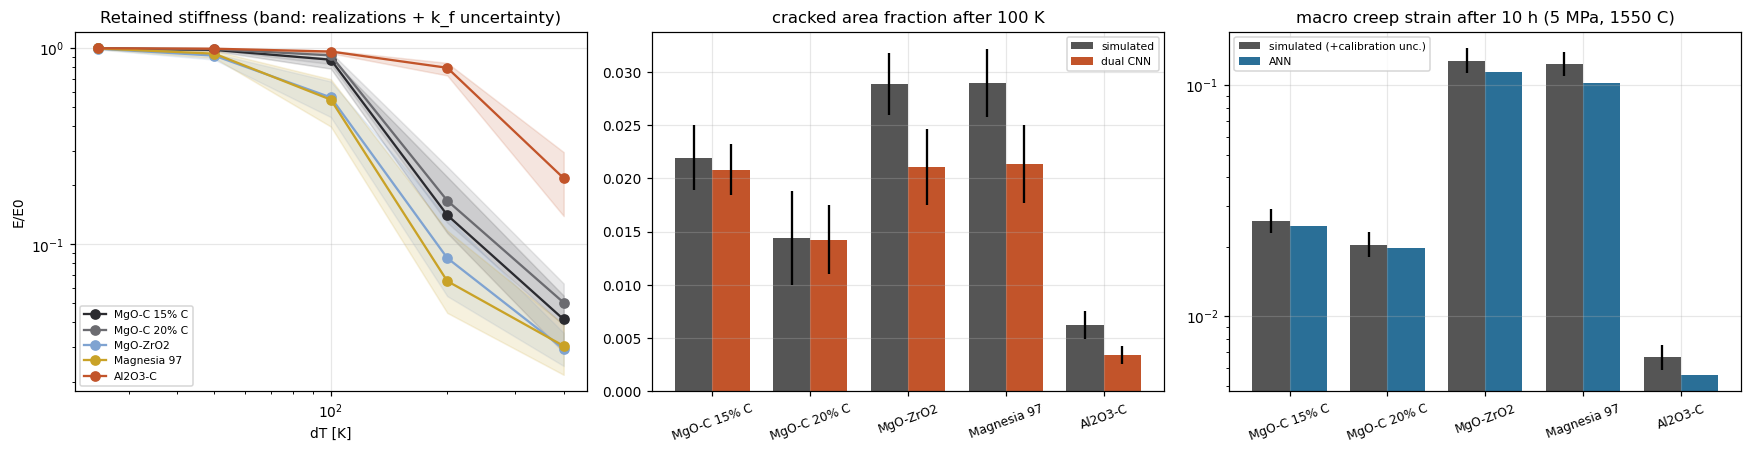

,E/E0 25K,E/E0 50K,E/E0 100K,E/E0 200K,E/E0 400K,creep_10h
grade,,,,,,
MgO-C 15% C,"1.00 [1.00, 1.00]","0.98 [0.97, 0.99]","0.87 [0.79, 0.89]","0.14 [0.11, 0.22]","0.04 [0.03, 0.05]",2.58e-02 x/÷ 1.14
MgO-C 20% C,"1.00 [1.00, 1.00]","0.99 [0.98, 1.00]","0.92 [0.83, 0.95]","0.17 [0.13, 0.25]","0.05 [0.04, 0.06]",2.04e-02 x/÷ 1.14
MgO-ZrO2,"0.99 [0.99, 1.00]","0.92 [0.87, 0.94]","0.56 [0.45, 0.68]","0.09 [0.05, 0.14]","0.03 [0.02, 0.04]",1.28e-01 x/÷ 1.15
Magnesia 97,"1.00 [0.99, 1.00]","0.94 [0.89, 0.97]","0.55 [0.40, 0.69]","0.07 [0.04, 0.12]","0.03 [0.02, 0.04]",1.24e-01 x/÷ 1.14
Al2O3-C,"1.00 [1.00, 1.00]","0.99 [0.99, 1.00]","0.96 [0.94, 0.97]","0.79 [0.73, 0.84]","0.22 [0.14, 0.30]",6.64e-03 x/÷ 1.13


Creep at 1550 C extrapolates the calibration range (1350-1425 C) by 125 K; the validation at 1500 C (Section 6) quantifies the extrapolation error.


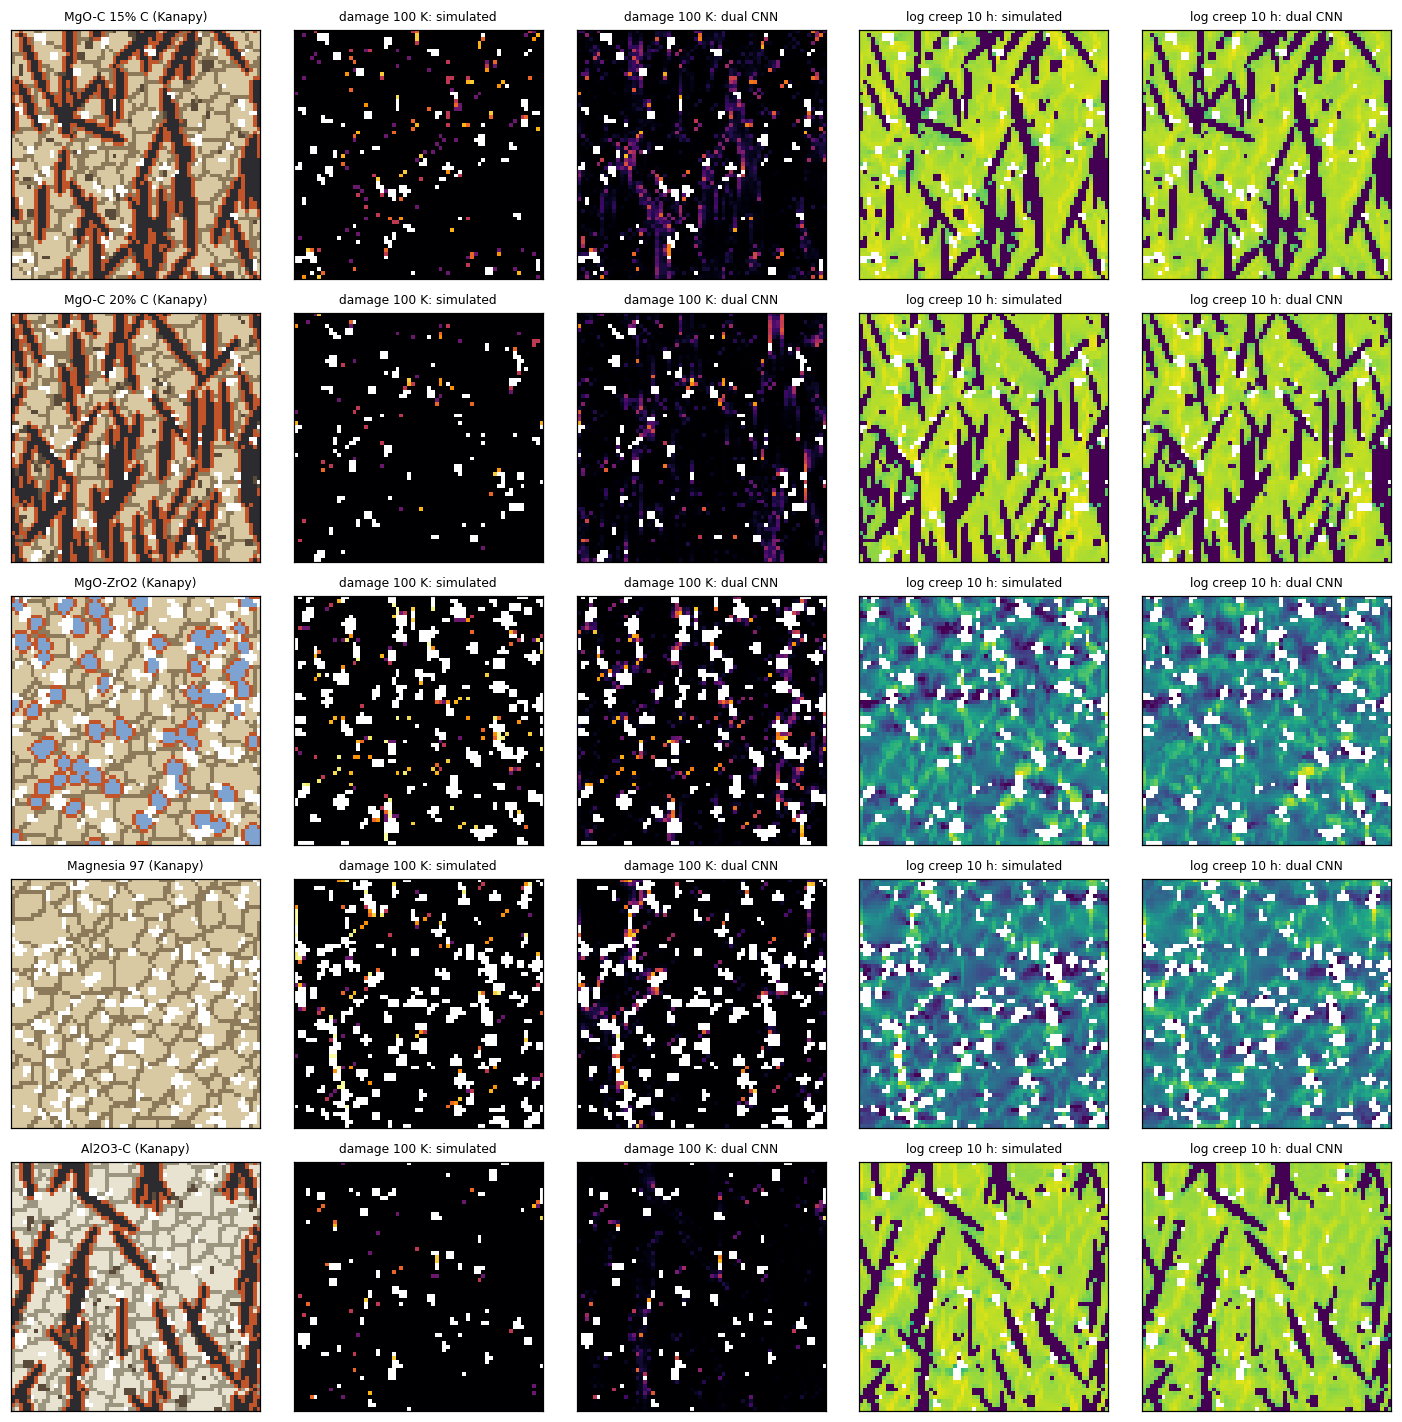

In [34]:
# uncertainty bands: realization scatter + calibration uncertainty (exact scaling laws)
st15_cal = np.array(CALREC["strength_kf1"]["15"])
rel_kf = float(np.hypot(B99["E-85-E-15-5"]["MOR_sd"] / B99["E-85-E-15-5"]["MOR"], st15_cal.std(ddof=1) / st15_cal.mean() / np.sqrt(len(st15_cal))))
creep_rms = float(min(d["rms_dex"] for d in CALREC["creep_fit"]))
print(f"calibration uncertainty: k_f +- {100 * rel_kf:.1f} %, creep prefactor +- {creep_rms:.2f} dex")
def E_curve_shift(Evals, levels, fac):
    """E/E0 at levels for strength scale k_f*fac: damage(dT; k_f*fac) = damage(dT/fac; k_f)."""
    return np.interp(np.log(np.asarray(levels) / fac), np.log(levels), Evals, left=1.0, right=Evals[-1])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
gcol = dict(zip(RANKED, ["#2b2b30", "#6b6b70", "#7fa3d1", "#c9a227", "#c2542a"]))
UQ = []
for g in RANKED:
    sub = dfk[dfk.grade == g]
    E = np.array([sub[f"E_ratio_{int(l)}"] for l in LEVELS]).T                       # (n_real, levels)
    lo = np.array([E_curve_shift(e, LEVELS, 1 - rel_kf) for e in E]); hi = np.array([E_curve_shift(e, LEVELS, 1 + rel_kf) for e in E])
    m_, s_ = E.mean(0), E.std(0)
    band_lo = np.minimum(lo.mean(0), m_ - s_); band_hi = np.maximum(hi.mean(0), m_ + s_)
    ax[0].plot(LEVELS, m_, "o-", color=gcol[g], label=g); ax[0].fill_between(LEVELS, np.clip(band_lo, 1e-3, 1), np.clip(band_hi, 1e-3, 1), color=gcol[g], alpha=0.15)
    cr_ = -sub.macro_creep_10h.values
    UQ.append(dict(grade=g, **{f"E/E0 {l:.0f}K": f"{m_[k]:.2f} [{max(band_lo[k], 0):.2f}, {min(band_hi[k], 1):.2f}]" for k, l in enumerate(LEVELS)},
                   creep_10h=f"{cr_.mean():.2e} x/÷ {10 ** np.hypot(creep_rms, np.std(np.log10(cr_))):.2f}"))
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("dT [K]"); ax[0].set_ylabel("E/E0"); ax[0].legend(fontsize=7)
ax[0].set_title("Retained stiffness (band: realizations + k_f uncertainty)")
idx = np.arange(len(RANKED)); w_ = 0.38
ax[1].bar(idx - w_ / 2, gm["cracked sim"], w_, yerr=gs["cracked sim"], label="simulated", color="#555")
ax[1].bar(idx + w_ / 2, gm["cracked CNN"], w_, yerr=gs["cracked CNN"], label="dual CNN", color="#c2542a")
crm = gm["creep 10h sim"].values
ax[2].bar(idx - w_ / 2, crm, w_, yerr=[crm - crm / 10 ** creep_rms, crm * 10 ** creep_rms - crm], label="simulated (+calibration unc.)", color="#555")
ax[2].bar(idx + w_ / 2, gm["creep 10h ANN"], w_, label="ANN", color="#2a6f97"); ax[2].set_yscale("log")
for a, t_ in [(ax[1], f"cracked area fraction after {LEVELS[2]:.0f} K"), (ax[2], "macro creep strain after 10 h (5 MPa, 1550 C)")]:
    a.set_xticks(idx); a.set_xticklabels(list(RANKED), rotation=20, fontsize=8); a.set_title(t_); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ranked_grades_uncertainty.png"), dpi=200); plt.show()
display(pd.DataFrame(UQ).set_index("grade"))
print("Creep at 1550 C extrapolates the calibration range (1350-1425 C) by 125 K; the validation at 1500 C (Section 6) "
      "quantifies the extrapolation error.")
fig, axes = plt.subplots(len(RANKED), 5, figsize=(13, 13))
for r_, g in enumerate(RANKED):
    i = np.where(dfk.grade.values == g)[0][0]; mk = mk_k[i]; ref = yk[i, 2][mk]
    show_phase(axes[r_, 0], PHk[i], f"{g} (Kanapy)")
    for c_, (img, lab, cm_, vr) in enumerate([(np.clip(DAMk[i, 2], 0, 1), f"damage {LEVELS[2]:.0f} K: simulated", "inferno", (0, 1)),
                                              (crack_pred[i, 2], f"damage {LEVELS[2]:.0f} K: dual CNN", "inferno", (0, 1)),
                                              (yk[i, 2], "log creep 10 h: simulated", "viridis", (np.percentile(ref, 2), ref.max())),
                                              (creep_pred[i, 2], "log creep 10 h: dual CNN", "viridis", (np.percentile(ref, 2), ref.max()))]):
        a = axes[r_, c_ + 1]
        a.imshow(np.ma.masked_where(~mk, img), cmap=cm_, vmin=vr[0], vmax=vr[1], origin="lower", interpolation="nearest")
        a.set_title(lab, fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ranked_grade_maps.png"), dpi=200); plt.show()

## 12. Abaqus
### 12.1 Solver verification with the CIP run (uncalibrated model)
The Abaqus jobs already run on the CIP machine use the **uncalibrated** phase data and the earlier microstructures
(Voronoi design RVEs and the first Kanapy realizations). Solver verification does not depend on the parameter values:
both solvers receive identical meshes, materials and boundary conditions, so the comparison below — Abaqus vs. the
Python reference solver of the *same* (uncalibrated) model — verifies the implementation. Results are read from
`OLD_ABAQUS_RESULTS` (copy the `*_results.npz` files there after `extract_odb.py`).

In [35]:
tmp = os.path.join(W, "abaqus_selftest"); os.makedirs(tmp, exist_ok=True)
f0 = sorted(glob.glob(os.path.join(P["SIMC"], "*.npz")))[0]
present = fake_results_from_python(f0, tmp); z0 = np.load(f0); rid0 = os.path.basename(f0)[:-4]
a_ = read_ts(os.path.join(tmp, f"TS_{rid0}_results.npz"), CONFIG["N_PIXELS"], LEVELS, present)
c_ = read_cr(os.path.join(tmp, f"CR_{rid0}_results.npz"), CONFIG["N_PIXELS"], CTIMES, present)
check("Abaqus reader: round-trip identical (crack + creep)",
      np.array_equal(a_["damage"], z0["damage"]) and np.allclose(c_["ceeq"], z0["ceeq"]) and abs(a_["E_ratio_end"] / z0["E_ratio"][-1] - 1) < 1e-9)

def compare_abaqus(abaqus_dir, records, levels, ctimes):
    """records: rve_id -> dict(ph, dam, ce, row). Returns (thermal-shock table, creep table, maps)."""
    ts_rows, cr_rows, maps = [], [], {}
    for f in sorted(glob.glob(os.path.join(abaqus_dir, "TS_*_results.npz"))):
        rid = os.path.basename(f)[3:-12]
        if rid not in records:
            continue
        R_ = records[rid]; present = np.flatnonzero(R_["ph"].ravel() != 0)
        a = read_ts(f, R_["ph"].shape[0], levels, present)
        if not a.get("ok"):
            print("incomplete:", rid); continue
        maps[rid] = a; mk = R_["ph"] != 0
        ks = [k for k in range(len(levels)) if a["levels_reached"][k]]
        q = [seg_metrics(np.clip(R_["dam"][k], 0, 1), np.clip(a["damage"][k], 0, 1), mk) for k in ks]
        ts_rows.append(dict(rve=rid, completed=a["completed"], dT_reached=a["dT_reached"],
                            E0_python=R_["row"]["E0_eff_GPa"] * 1000, E0_abaqus=a["E0"],
                            dTc_python=R_["row"]["dTc"], dTc_abaqus=a["dT_onset"],
                            E_ratio_end_python=R_["row"][f"E_ratio_{int(levels[-1])}"], E_ratio_end_abaqus=a["E_ratio_end"],
                            IoU_python_vs_abaqus=np.mean([x["IoU"] for x in q]) if ks else np.nan))
    for f in sorted(glob.glob(os.path.join(abaqus_dir, "CR_*_results.npz"))):
        rid = os.path.basename(f)[3:-12]
        if rid not in records:
            continue
        R_ = records[rid]; present = np.flatnonzero(R_["ph"].ravel() != 0)
        c = read_cr(f, R_["ph"].shape[0], ctimes, present)
        if not c.get("ok"):
            print("incomplete:", rid); continue
        mk3 = np.repeat((R_["ph"] != 0)[None], len(ctimes), 0)
        ya = np.log10(np.clip(c["ceeq"], 0, None) + CEEQ_FLOOR); yp = np.log10(R_["ce"] + CEEQ_FLOOR)
        cr_rows.append(dict(rve=rid, t_reached_h=c["t_reached"] / 3600, macro_creep_python=R_["row"]["macro_creep_10h"],
                            macro_creep_abaqus=c["macro_creep"][-1], R2_python_vs_abaqus=r2_score(ya[mk3], yp[mk3]),
                            MAE_dex=np.abs(ya - yp)[mk3].mean()))
    return pd.DataFrame(ts_rows), pd.DataFrame(cr_rows), maps

OLDREC = {}
for folder in [CONFIG["OLD_SIM_DIR"], CONFIG["OLD_RANKED_DIR"]]:
    if os.path.isdir(folder) and glob.glob(os.path.join(folder, "*.npz")):
        dfo, PHo, DAMo, CEo, LVo, CTo = load_sim_results(folder)
        for i in range(len(dfo)):
            OLDREC[dfo.rve_id[i]] = dict(ph=PHo[i], dam=DAMo[i], ce=CEo[i], row=dfo.iloc[i])
print(len(OLDREC), "uncalibrated Python results available for the comparison")
n_old = len(glob.glob(os.path.join(CONFIG["OLD_ABAQUS_RESULTS"], "*_results.npz")))
if OLDREC and n_old:
    ts_v, cr_v, _ = compare_abaqus(CONFIG["OLD_ABAQUS_RESULTS"], OLDREC, LVo, CTo)
    if len(ts_v):
        display(ts_v.round(3))
        e0err = (ts_v.E0_abaqus / ts_v.E0_python - 1).abs()
        check("Abaqus vs Python (same model): elastic modulus E0 within 1 %", (e0err < 0.01).all(), f"max {e0err.max():.2%}")
        print("crack onset ratio Abaqus/Python (median):", np.nanmedian(ts_v.dTc_abaqus / ts_v.dTc_python).round(3),
              "| mean crack-map IoU Python vs Abaqus:", np.nanmean(ts_v.IoU_python_vs_abaqus).round(3))
    if len(cr_v):
        display(cr_v.round(4))
        mc = (cr_v.macro_creep_abaqus / cr_v.macro_creep_python - 1).abs()
        check("Abaqus vs Python (same model): macro creep strain after 10 h within 5 %", (mc < 0.05).all(), f"median {mc.median():.2%}")
else:
    print(f"no Abaqus results in {CONFIG['OLD_ABAQUS_RESULTS']} yet ({n_old} files) - run extract_odb.py on the CIP machine and copy them.")

PASS  Abaqus reader: round-trip identical (crack + creep)
370 uncalibrated Python results available for the comparison


,rve,completed,dT_reached,E0_python,E0_abaqus,dTc_python,dTc_abaqus,E_ratio_end_python,E_ratio_end_abaqus,IoU_python_vs_abaqus
0,KAN_Al2O3C_r00,False,200.0,103396.813,103396.809,5.049,4.925,0.042,-0.500,0.017
1,KAN_Al2O3C_r01,False,200.0,107857.013,107857.013,5.875,4.932,0.042,-0.486,0.013
2,KAN_Magnesia_97_r00,False,200.0,166567.933,166567.934,3.963,3.583,0.027,-0.165,0.136
3,KAN_Magnesia_97_r01,False,200.0,165965.660,165965.664,4.355,4.140,0.024,-0.206,0.031
4,KAN_MgOZrO2_r00,False,200.0,173413.517,173413.515,5.395,5.009,0.022,-0.137,0.044
5,KAN_MgOZrO2_r01,False,200.0,172305.805,172305.810,4.863,4.189,0.017,-0.252,0.052
6,RVE0000,False,200.0,93156.005,93156.004,3.818,3.652,0.042,0.000,0.019
7,RVE0001,False,200.0,59850.016,59850.019,3.958,4.100,0.049,-1.049,0.016
8,RVE0002,False,200.0,93771.268,93771.267,3.928,4.092,0.037,-0.511,0.042
9,RVE0003,False,200.0,90113.294,90113.294,2.303,2.914,0.039,0.000,0.061


PASS  Abaqus vs Python (same model): elastic modulus E0 within 1 %   [max 0.00%]
crack onset ratio Abaqus/Python (median): 0.904 | mean crack-map IoU Python vs Abaqus: 0.059


,rve,t_reached_h,macro_creep_python,macro_creep_abaqus,R2_python_vs_abaqus,MAE_dex
0,KAN_Al2O3C_r00,10.0,-0.0001,-0.0001,0.9980,0.0248
1,KAN_Al2O3C_r01,10.0,-0.0001,-0.0001,0.9979,0.0251
2,KAN_Magnesia_97_r00,10.0,-0.0003,-0.0004,0.9439,0.0920
3,KAN_Magnesia_97_r01,10.0,-0.0003,-0.0004,0.9496,0.0879
4,KAN_MgOC_15C_r00,10.0,-0.0002,-0.0002,0.9981,0.0336
5,KAN_MgOC_15C_r01,10.0,-0.0002,-0.0002,0.9980,0.0337
6,KAN_MgOC_20C_r00,10.0,-0.0001,-0.0002,0.9983,0.0314
7,KAN_MgOC_20C_r01,10.0,-0.0001,-0.0002,0.9986,0.0294
8,KAN_MgOZrO2_r00,10.0,-0.0003,-0.0004,0.9613,0.0757
9,KAN_MgOZrO2_r01,10.0,-0.0003,-0.0004,0.9510,0.0817


FAIL  Abaqus vs Python (same model): macro creep strain after 10 h within 5 %   [median 15.61%]


### 12.1b Abaqus vs Python with the v2 solver
Energy-consistent saw-tooth law and Gauss-point creep, recomputed on the stored microstructures of the Abaqus RVEs (identical meshes, uncalibrated parameters as in the decks). Crack maps are compared with a common crack definition (opening ≥ 5 % of $w_c=2G_F/f_t$), the macro response with the secant ratio $\sigma_{xx}/(E_0\alpha_{eff}\Delta T)$ from the RF1 history of the COOL step.

50 RVEs recomputed with the v2 solver (21 s)


,25 K,50 K,100 K
secant_abaqus,0.613,0.270,0.079
secant_python,0.543,0.203,0.083
crack_area_abaqus,0.015,0.028,0.039
crack_area_python,0.014,0.027,0.038
overlap_1px,0.866,0.905,0.901


,rve,family,porosity,macro_creep_python,macro_creep_abaqus,ratio,map_R2
0,KAN_Al2O3C_r00,ALC,0.0403,-0.0001,-0.0001,0.9914,0.9999
1,KAN_Al2O3C_r01,ALC,0.0400,-0.0001,-0.0001,0.9911,0.9999
2,KAN_Magnesia_97_r00,MAG,0.1611,-0.0004,-0.0004,0.9999,1.0000
3,KAN_Magnesia_97_r01,MAG,0.1606,-0.0004,-0.0004,0.9999,1.0000
4,KAN_MgOC_15C_r00,MGOC,0.0410,-0.0002,-0.0002,0.9947,0.9997
5,KAN_MgOC_15C_r01,MGOC,0.0405,-0.0002,-0.0002,0.9951,0.9996
6,KAN_MgOC_20C_r00,MGOC,0.0415,-0.0002,-0.0002,0.9943,0.9998
7,KAN_MgOC_20C_r01,MGOC,0.0405,-0.0002,-0.0002,0.9942,0.9996
8,KAN_MgOZrO2_r00,MGOZR,0.1409,-0.0004,-0.0004,1.0000,1.0000
9,KAN_MgOZrO2_r01,MGOZR,0.1401,-0.0004,-0.0004,0.9999,1.0000


PASS  Abaqus vs Python v2: elastic modulus E0 within 1 %   [max 5.3e-08]
PASS  Abaqus vs Python v2: macro creep strain after 10 h within 5 % (Gauss-point creep)   [median 0.997, range 0.985-1.000; map R2 min 0.9994]
PASS  Abaqus vs Python v2: secant stiffness after the shock, MAE < 0.05 (25-100 K)   [MAE 0.034]
PASS  Abaqus vs Python v2: crack maps, median 1-px overlap > 0.7 (25-100 K)   [0.89]


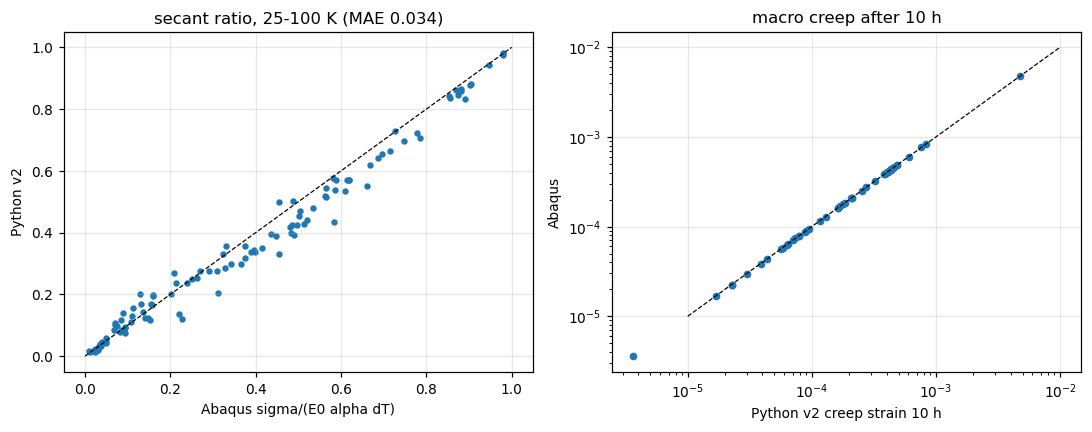

In [36]:
# 12.1b  Abaqus vs Python with the v2 solver (energy-consistent saw-tooth law, Gauss-point creep).
# The old Python results are recomputed on the STORED microstructures of the Abaqus RVEs (identical meshes) with the
# uncalibrated parameters used in the decks. Compared quantities:
#   * macro creep strain after 10 h and creep maps
#   * secant stiffness ratio sigma_xx / (E0 alpha_eff dT): Abaqus from the RF1 history of the COOL step (every increment),
#     Python from the SLA state at the stored levels
#   * crack maps with a COMMON crack definition: opening >= 5 % of w_c = 2 G_F / f_t
#     (Abaqus: DAMAGET = 0.99 w / w_c >= 0.05; Python: secant damage >= 1 - 0.95 eps0 / (0.05 eps_u), per element)
import json, glob, os, time
import numpy as np, pandas as pd
from scipy import ndimage
from fe2d import PixelMesh
from materials import arrhenius, element_props
from calib import materials_cal
from rve_gen import PHASES
from sim import thermal_shock_sla, creep_norton
from driver import alpha_eff
from abaqus_results import read_ts, read_cr

def _old_path(rid):
    for d in [CONFIG["OLD_SIM_DIR"], CONFIG["OLD_RANKED_DIR"]]:
        p = os.path.join(d, rid + ".npz")
        if os.path.exists(p):
            return p
    return None

def resim_v2(rid, do_ts, do_cr):
    z = np.load(_old_path(rid), allow_pickle=True)
    e = json.loads(str(z["meta"]))["entry"]
    mesh = PixelMesh(z["phase"], L=e["L_mm"])
    props = element_props(mesh, materials_cal(e["family"], e["params"], None), PHASES)
    out = dict(rve=rid, family=e["family"], phase=z["phase"], elem_id=mesh.elem_id, dT=list(z["dT_levels"]),
               t=list(z["creep_times"]), porosity=float((z["phase"] == 0).mean()))
    if do_ts:
        ts = thermal_shock_sla(mesh, props, out["dT"])
        out.update(E0=ts["E0_eff"], alpha_eff=alpha_eff(mesh, props), dTc=ts["dTc"],
                   sig_ratio=[s["sig_ratio"] for s in ts["snaps"]], damage=[s["damage"] for s in ts["snaps"]],
                   thr=1.0 - 0.95 * (props["ft"] / props["E"]) / (0.05 * 2.0 * props["GF"] / (props["ft"] * mesh.h)))
    if do_cr:
        cr = creep_norton(mesh, props, -e["load"]["creep_stress"], arrhenius(e["load"]["creep_T"]), 36000.0, out["t"])
        out.update(macro_creep=cr["snaps"][-1]["macro_creep"], ceeq=cr["snaps"][-1]["ceeq"])
    return out

ABQ = CONFIG["OLD_ABAQUS_RESULTS"]
ts_ids = sorted(os.path.basename(f)[3:-12] for f in glob.glob(os.path.join(ABQ, "TS_*_results.npz")))
cr_ids = sorted(os.path.basename(f)[3:-12] for f in glob.glob(os.path.join(ABQ, "CR_*_results.npz")))
ids = [r for r in sorted(set(ts_ids) | set(cr_ids)) if _old_path(r)]
t0 = time.time()
V2 = {r["rve"]: r for r in par(lambda rid: resim_v2(rid, rid in ts_ids, rid in cr_ids), ids)}
print(f"{len(V2)} RVEs recomputed with the v2 solver ({time.time() - t0:.0f} s)")

dil = lambda a: ndimage.binary_dilation(np.pad(a, 1, mode="wrap"))[1:-1, 1:-1]
rows_ts, rows_cr = [], []
for rid in ts_ids:
    if rid not in V2:
        continue
    R_ = V2[rid]; N_ = R_["phase"].shape[0]; present = np.flatnonzero(R_["phase"].ravel() != 0)
    f = os.path.join(ABQ, f"TS_{rid}_results.npz")
    a = read_ts(f, N_, R_["dT"], present)
    if not a.get("ok"):
        continue
    h = np.load(f)["hist_COOL_RP1_RF1"]
    dTs = h[:, 0] * max(R_["dT"])
    with np.errstate(divide="ignore", invalid="ignore"):
        sec = h[:, 1] / (R_["E0"] * R_["alpha_eff"] * dTs)         # RF1/(L*t) / (E0 alpha dT), L = t = 1 mm
    row = dict(rve=rid, family=R_["family"], E0_abaqus=a["E0"], E0_python=R_["E0"], dTc_abaqus=a["dT_onset"], dTc_python=R_["dTc"])
    for k, lv in enumerate(R_["dT"]):
        if not a["levels_reached"][k]:
            continue
        row[f"sec_abq_{lv:.0f}"] = float(sec[int(np.argmin(np.abs(dTs - lv)))])
        row[f"sec_py_{lv:.0f}"] = R_["sig_ratio"][k]
        P = np.zeros(N_ * N_, bool); P[R_["elem_id"]] = R_["damage"][k] >= R_["thr"]; P = P.reshape(N_, N_)
        A_ = a["damage"][k] >= 0.05
        if P.sum() + A_.sum():
            row[f"overlap1px_{lv:.0f}"] = ((P & dil(A_)).sum() + (A_ & dil(P)).sum()) / (P.sum() + A_.sum())
            row[f"area_py_{lv:.0f}"], row[f"area_abq_{lv:.0f}"] = P.sum() / len(present), A_.sum() / len(present)
    rows_ts.append(row)
for rid in cr_ids:
    if rid not in V2:
        continue
    R_ = V2[rid]; N_ = R_["phase"].shape[0]; present = np.flatnonzero(R_["phase"].ravel() != 0)
    c = read_cr(os.path.join(ABQ, f"CR_{rid}_results.npz"), N_, R_["t"], present)
    if not c.get("ok"):
        continue
    img = np.zeros(N_ * N_); img[R_["elem_id"]] = R_["ceeq"]
    am, pm = c["ceeq"][-1].ravel()[present], img[present]
    rows_cr.append(dict(rve=rid, family=R_["family"], porosity=R_["porosity"], macro_creep_python=R_["macro_creep"],
                        macro_creep_abaqus=c["macro_creep"][-1], ratio=c["macro_creep"][-1] / R_["macro_creep"],
                        map_R2=1 - np.sum((am - pm) ** 2) / np.sum((am - am.mean()) ** 2)))
TS2, CR2 = pd.DataFrame(rows_ts), pd.DataFrame(rows_cr)
mid = [l for l in (25, 50, 100) if f"sec_abq_{l}" in TS2]
summ = pd.DataFrame({f"{l} K": dict(secant_abaqus=TS2[f"sec_abq_{l}"].median(), secant_python=TS2[f"sec_py_{l}"].median(),
                                     crack_area_abaqus=TS2[f"area_abq_{l}"].median(), crack_area_python=TS2[f"area_py_{l}"].median(),
                                     overlap_1px=TS2[f"overlap1px_{l}"].median()) for l in mid}).round(3)
display(summ)
display(CR2.round(4))
x = np.concatenate([TS2[f"sec_abq_{l}"] for l in mid]); y = np.concatenate([TS2[f"sec_py_{l}"] for l in mid])
mae_sec = float(np.nanmean(np.abs(x - y)))
check("Abaqus vs Python v2: elastic modulus E0 within 1 %", ((TS2.E0_abaqus / TS2.E0_python - 1).abs() < 0.01).all(),
      f"max {(TS2.E0_abaqus / TS2.E0_python - 1).abs().max():.1e}")
check("Abaqus vs Python v2: macro creep strain after 10 h within 5 % (Gauss-point creep)", ((CR2.ratio - 1).abs() < 0.05).all(),
      f"median {CR2.ratio.median():.3f}, range {CR2.ratio.min():.3f}-{CR2.ratio.max():.3f}; map R2 min {CR2.map_R2.min():.4f}")
check("Abaqus vs Python v2: secant stiffness after the shock, MAE < 0.05 (25-100 K)", mae_sec < 0.05, f"MAE {mae_sec:.3f}")
check("Abaqus vs Python v2: crack maps, median 1-px overlap > 0.7 (25-100 K)",
      np.nanmedian(np.concatenate([TS2[f"overlap1px_{l}"] for l in mid])) > 0.7,
      f"{np.nanmedian(np.concatenate([TS2[f'overlap1px_{l}'] for l in mid])):.2f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(x, y, s=10); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("Abaqus sigma/(E0 alpha dT)"); ax[0].set_ylabel("Python v2"); ax[0].set_title(f"secant ratio, 25-100 K (MAE {mae_sec:.3f})")
ax[1].loglog(-CR2.macro_creep_python, -CR2.macro_creep_abaqus, "o", ms=4); lim = [1e-5, 1e-2]; ax[1].plot(lim, lim, "k--", lw=0.8)
ax[1].set_xlabel("Python v2 creep strain 10 h"); ax[1].set_ylabel("Abaqus"); ax[1].set_title("macro creep after 10 h")
plt.tight_layout(); plt.show()

### 12.2 Abaqus decks of the calibrated model
Decks for the first RVEs of each family and the first realizations of each ranked grade, written with the calibrated
phase table (boundary stiffness, strengths, creep law) and the new ΔT range. Every deck passes the static validator and
the rebuild-from-text check (the model rebuilt only from the deck text must reproduce the reference solver). A smoke
deck of homogeneous dense MgO has the analytic onset ΔT_c = k_f f_t / (E α).

In [37]:
   P = {k: os.path.join(W, v) for k, v in SUB.items()}

In [38]:
DECKS = P["DECKS"]
ph_h = np.ones((16, 16), np.uint8); mesh_h = PixelMesh(ph_h); mats_h = materials_cal("MAG", {"k_gb": 1.0}, CAL)
write_thermal_shock_deck(os.path.join(DECKS, "SMOKE_TS_HOMOG.inp"), mesh_h, mats_h, PHASES, LEVELS, "SMOKE homogeneous MgO, calibrated")
dTc_smoke = mats_h["MGO"]["ft"] / (mats_h["MGO"]["E"] * mats_h["MGO"]["alpha"])
print(f"smoke deck: analytic crack onset {dTc_smoke:.2f} K")
deck_list = []
def write_pair(e, ph):
    mesh = PixelMesh(ph, L=e["L_mm"]); mats = materials_cal(e["family"], e["params"], CAL)
    write_thermal_shock_deck(os.path.join(DECKS, f"TS_{e['rve_id']}.inp"), mesh, mats, PHASES, LEVELS, e["rve_id"])
    write_creep_deck(os.path.join(DECKS, f"CR_{e['rve_id']}.inp"), mesh, mats, PHASES, -e["load"]["creep_stress"],
                     arrhenius_cal(e["load"]["creep_T"], CAL["Q"]), CREEP_T_END, CREEP_SNAPS, e["rve_id"])
    return [f"TS_{e['rve_id']}.inp", f"CR_{e['rve_id']}.inp"]
first_smoke = [d for d in design if d["family"] == "MGOC"][0]
ph_s = make_microstructure(first_smoke)[0][::2, ::2].copy()          # 32 x 32 smoke versions of a real RVE
ph_s[0, 0] = ph_s[0, -1] = ph_s[-1, 0] = ph_s[-1, -1] = 1
keep = largest_periodic_component(ph_s != 0); ph_s[(ph_s != 0) & ~keep] = 0
mesh_s = PixelMesh(ph_s); mats_s = materials_cal("MGOC", first_smoke["params"], CAL)
write_thermal_shock_deck(os.path.join(DECKS, "SMOKE_TS_RVE.inp"), mesh_s, mats_s, PHASES, LEVELS, "SMOKE calibrated 32px")
write_creep_deck(os.path.join(DECKS, "SMOKE_CR_RVE.inp"), mesh_s, mats_s, PHASES, -5.0, arrhenius_cal(1550.0, CAL["Q"]), CREEP_T_END, CREEP_SNAPS, "SMOKE calibrated 32px")
for fam in FAMILIES:
    for e in [d for d in design if d["family"] == fam][:CONFIG["ABAQUS_DECKS_PER_FAMILY"]]:
        deck_list += write_pair(e, make_microstructure(e)[0])
for g in RANKED:
    for e in [d for d in rdesign if d["grade"] == g][:CONFIG["KANAPY_DECKS_PER_GRADE"]]:
        deck_list += write_pair(e, make_microstructure(e)[0])
write_scripts(DECKS)
json.dump(dict(cal=CAL, levels=list(LEVELS)), open(os.path.join(DECKS, "calibration_used.json"), "w"), indent=1)
bad = {os.path.basename(f): validate_deck(f)[1][:3] for f in sorted(glob.glob(os.path.join(DECKS, "*.inp"))) if not validate_deck(f)[0]}
check("Abaqus (calibrated): all decks pass the static validator", not bad, f"{len(deck_list) + 3} decks" if not bad else bad)
from sim import _solve_unit, _probe_E
rows = []
for fam in FAMILIES:
    e = [d for d in design if d["family"] == fam][0]
    ph = make_microstructure(e)[0]; mesh, props = props_of(ph, fam, e["params"], CAL)
    R = deck_linear_response(os.path.join(DECKS, f"TS_{e['rve_id']}.inp"))
    lam_, mu_ = lame(props["E"], props["nu"])
    Kq, free, fidx, lu, s = _solve_unit(mesh, lam_, mu_, props["alpha"])
    s1 = np.maximum(principal_max(s), 0)
    err = np.abs(R["s1_per_K"][np.argsort(R["elem_labels"])] - s1[np.argsort(mesh.elem_id)]).max() / s1.max()
    rows.append(dict(family=FAMILY_LABEL[fam], s1_relerr=err, E_deck=R["E_probe_force"], E_ref=_probe_E(mesh, Kq, free, fidx, lu)))
rb = pd.DataFrame(rows); display(rb)
worst = max(rb.s1_relerr.max(), (rb.E_deck / rb.E_ref - 1).abs().max())
check("Abaqus (calibrated): deck rebuilt from text == reference solver", worst < 1e-6, f"max rel.err {worst:.1e}")
print(f"""
NEXT CIP RUN (calibrated model): copy the folder {DECKS} to the CIP machine (shared home: just cd into it), then
  module load abaqus/latest
  bash run_smoke.sh                           (SMOKE_TS_HOMOG onset must be {dTc_smoke:.2f} K)
  nohup bash run_abaqus.sh 12 > run_all.log 2>&1 &
  abaqus python extract_odb.py .   ;   cp *_results.npz ../{SUB['ARES']}/
and re-run Section 12.3.""")

smoke deck: analytic crack onset 15.81 K
PASS  Abaqus (calibrated): all decks pass the static validator   [63 decks]


,family,s1_relerr,E_deck,E_ref
0,MgO-C,3.279491e-09,9529.468724,9529.468758
1,MgO-ZrO2,3.180142e-09,11640.076580,11640.076632
2,Magnesia,4.477323e-09,4676.240149,4676.240173
3,Al2O3-C,4.057660e-10,8312.706759,8312.706763


PASS  Abaqus (calibrated): deck rebuilt from text == reference solver   [max rel.err 5.2e-09]

NEXT CIP RUN (calibrated model): copy the folder MR_RVE_work/abaqus_decks_cal to the CIP machine (shared home: just cd into it), then
  module load abaqus/latest
  bash run_smoke.sh                           (SMOKE_TS_HOMOG onset must be 15.81 K)
  nohup bash run_abaqus.sh 12 > run_all.log 2>&1 &
  abaqus python extract_odb.py .   ;   cp *_results.npz ../abaqus_results_cal/
and re-run Section 12.3.


### 12.3 Calibrated model: Abaqus vs Python vs CNN
*This notebook was executed before the calibrated Abaqus run had finished, so the cell below finds no results. The comparison of 60 calibrated RVEs is reported in the paper (`paper/`): identical moduli, creep strains within 0.5 % and post-shock stiffness within 0.016 up to 100 K.*

In [39]:
NEWREC = {}
for i in range(len(df)):
    NEWREC[df.rve_id[i]] = dict(ph=PH[i], dam=DAM[i], ce=CEEQ[i], row=df.iloc[i], src=DD, i=i)
for i in range(len(dfk)):
    NEWREC[dfk.rve_id[i]] = dict(ph=PHk[i], dam=DAMk[i], ce=CEk[i], row=dfk.iloc[i], src=DK, i=i)
if glob.glob(os.path.join(P["ARES"], "*_results.npz")):
    ts_c, cr_c, maps_c = compare_abaqus(P["ARES"], NEWREC, LEVELS, CTIMES)
    if len(ts_c):
        iou_cnn = []
        for rid in ts_c.rve:
            R_ = NEWREC[rid]; a = maps_c[rid]; mk = R_["ph"] != 0
            pc = np.stack([dual_predict(dual, [R_["i"]], R_["src"], k, 0)[0][0] for k in range(len(LEVELS))])
            ks = [k for k in range(len(LEVELS)) if a["levels_reached"][k]]
            iou_cnn.append(np.mean([seg_metrics(np.clip(a["damage"][k], 0, 1), pc[k], mk)["IoU"] for k in ks]) if ks else np.nan)
        ts_c["IoU_CNN_vs_abaqus"] = iou_cnn
        display(ts_c.round(3))
        check("Abaqus vs Python (calibrated): E0 within 1 %", ((ts_c.E0_abaqus / ts_c.E0_python - 1).abs() < 0.01).all())
    if len(cr_c):
        display(cr_c.round(4))
else:
    print("no calibrated Abaqus results yet - see the instructions printed in 12.2")

no calibrated Abaqus results yet - see the instructions printed in 12.2


## 13. Verification summary

In [40]:
summary = pd.DataFrame([(k, "PASS" if v[0] else "FAIL", v[1]) for k, v in CHECKS.items()], columns=["check", "result", "value"])
display(summary)
print(f"{(summary.result == 'PASS').sum()} / {len(summary)} checks passed")

,check,result,value
0,FE: constrained cooling sigma_xx = E*alpha*dT ...,PASS,rel.err 1.4e-13
1,FE: laminate series + parallel rules (exact),PASS,
2,FE: periodic shift invariance,PASS,0.0e+00
3,SLA: homogeneous dT_c = ft/(E*alpha) (exact),PASS,19.753 K
4,Creep: homogeneous rate = A*sigma^n,PASS,rel.err 5.1e-13
5,Tension SLA: homogeneous strength = ft and mod...,PASS,80.000 MPa
6,Scaling law: SLA tensile strength proportional...,PASS,ratio 0.370000
7,Scaling law: creep master curve reproduces a d...,PASS,rel.err 4.2e-11 (time discretisation only)
8,Kanapy: ellipsoid rotation convention (surface...,PASS,1.7e-15
9,Kanapy slice: periodic faces add < 1 % extra g...,PASS,face 0.76 vs interior 0.81 (z = -2.8); extra G...


32 / 36 checks passed


## 14. Limitations
* **Scale.** The 1 mm RVE resolves the fine matrix (grains, flakes, pores); the millimetre-sized aggregates of real bricks
  are not represented. Brick-scale fracture energies (Section 6, [S19]) contain aggregate-scale bridging and are therefore
  larger than the local values.
* **Effective boundary stiffness.** s_b lumps microcracks, carbon bond and binder contacts into one factor; the validation
  shows that it reproduces the magnitude of the moduli but underestimates their sensitivity to the graphite content.
  A two-parameter variant (separate grain-boundary and interface factors) did not improve the prediction (Section 6).
* **Strength.** The RVE tensile strength is equated with the modulus of rupture (an upper estimate of the tensile strength);
  only the strength ratio is validated. Thermal-shock damage is a model prediction under the idealised hot-face constraint;
  no quench-test data were used.
* **Creep.** A steady Norton law represents the 5-h strain of primary-creep tests; the creep law is calibrated on magnesia
  only and extrapolated to 1550 °C and to the other grades.
* **Data.** Literature bricks differ from the ranked grades in raw materials and processing; the Al addition of [B99] is
  not modelled explicitly; the porosity of the [U20] brick is derived from its stated density.
* **Small strains.** Creep strains reach several per cent at the upper end of the load range; the model is geometrically
  linear.
* **Two dimensions.** Plane-stress slices; 3-D Kanapy RVEs are the next step.

## 15. Key results, conclusions, references, reproducibility

In [41]:
key = {
    "RVEs (all Kanapy): design / ranked realizations / calibration": f"{len(df)} / {len(dfk)} / {len(CALE)}",
    "calibrated s_b, k_f": f"{CAL['s_b']:.4g}, {CAL['k_f']:.3f}",
    "calibrated creep law (n, Q, A_ref at 1550 C)": f"{CAL['n']:.2f}, {CAL['Q'] / 1e3:.0f} kJ/mol, {CAL['A_ref']:.2e}",
}
for _, r in VAL.iterrows():
    key[f"{r.role}: {r.quantity}"] = f"measured {r.measured:.4g}, model {r.model:.4g} ({r.error:+.2f} {r.error_unit})"
key["validation quantities within target"] = f"{vv.within_target.sum()} / {len(vv)}"
key["ANN 5-fold R2: E/E0 @%.0f K, creep rate" % LEVELS[2]] = f"{res.iloc[jref].ANN_R2:.2f}, {res.loc['log10 creep rate', 'ANN_R2']:.2f}"
key["dual CNN held-out RVEs: crack IoU (prior), creep pixel R2"] = f"{iou_dual:.2f} ({iou_pr:.2f}), {cr_tab.CNN_pixel_R2.mean():.2f}"
key["dual CNN ranked realizations: crack IoU, creep R2"] = f"{iou_k:.2f}, {r2_k:.2f}"
key["grade ranking Spearman (stiffness ANN, creep ANN, creep map CNN)"] = f"{rho_ts:.2f}, {rho_cr:.2f}, {rho_cm:.2f}"
key["checks passed"] = f"{(summary.result == 'PASS').sum()} / {len(summary)}"
KEY = pd.Series(key, name="value"); display(KEY.to_frame())
KEY.to_frame().to_csv(os.path.join(W, "key_results.csv"))
VAL.to_csv(os.path.join(W, "validation_table.csv"), index=False)

,value
RVEs (all Kanapy): design / ranked realizations / calibration,320 / 50 / 30
"calibrated s_b, k_f","0.01035, 0.801"
"calibrated creep law (n, Q, A_ref at 1550 C)","1.75, 274 kJ/mol, 4.87e-08"
"calibration: E, MgO-C 15 % (calibration)","measured 12, model 12 (-0.00 relative)"
"validation: E, MgO-C 7 %","measured 19, model 15.97 (-0.16 relative)"
"validation: E, magnesia 97","measured 17, model 22.09 (+0.30 relative)"
validation: strength ratio 7 % / 15 % graphite,"measured 1.231, model 1.161 (-0.06 relative)"
"calibration: creep strain 5 h, 1350 C, 5.0 MPa (calibration)","measured 0.002896, model 0.003244 (+0.05 dex)"
"calibration: creep strain 5 h, 1350 C, 6.0 MPa (calibration)","measured 0.004343, model 0.004424 (+0.01 dex)"
"calibration: creep strain 5 h, 1350 C, 8.0 MPa (calibration)","measured 0.008231, model 0.007232 (-0.06 dex)"


### Conclusions
1. A grain-scale model with handbook phase data overestimates the modulus of refractory bricks by roughly an order of
   magnitude; one effective boundary-stiffness parameter calibrated on a single brick brings the predictions for other
   bricks to the right magnitude (Section 6 for the numbers).
2. With two exact scaling laws, strength and creep calibration need one simulation per RVE (and creep exponent), so the
   calibration is cheap enough to be repeated whenever new test data arrive.
3. The calibrated dataset of 320 Kanapy RVEs supports surrogates that predict damage and creep maps from the microstructure
   image and reproduce the grade ranking of the simulations on unseen realizations.
4. Thermal-shock predictions remain to be validated with quench tests (residual modulus vs ΔT); this, 3-D Kanapy RVEs and
   aggregate-scale microstructures are the proposed next steps.

### References
* [B99] C. Baudín, C. Alvarez, R.E. Moore, J. Am. Ceram. Soc. 82 (1999) 3529–3538. doi:10.1111/j.1151-2916.1999.tb02276.x
* [U20] G. Unterreiter et al., Ceramics 3 (2020) 210–222. doi:10.3390/ceramics3020019
* [S19] M. Stückelschweiger, D. Gruber, S. Jin, H. Harmuth, Appl. Sci. 9 (2019) 3249. doi:10.3390/app9163249
* [Bz15] E.R. Benavidez et al., Matéria 20 (2015) 571–579. doi:10.1590/S1517-707620150003.0058
* [J14] S. Jin, H. Harmuth, D. Gruber, J. Eur. Ceram. Soc. 34 (2014) 4037–4042. doi:10.1016/j.jeurceramsoc.2014.05.034
* Kanapy: M.R.G. Prasad, N. Vajragupta, A. Hartmaier, J. Open Source Softw. 4 (2019) 1732. doi:10.21105/joss.01732 (https://github.com/ICAMS/Kanapy)
* J.G. Rots, Sequentially linear continuum model for concrete fracture, in: Fracture Mechanics of Concrete Structures (2001).
* W.D. Kingery, J. Am. Ceram. Soc. 38 (1955) 3–15; D.P.H. Hasselman, J. Am. Ceram. Soc. 52 (1969) 600–604.

In [42]:
import kanapy, scipy, sklearn
print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | tensorflow {tf.__version__} | keras {keras.__version__} | kanapy {getattr(kanapy, '__version__', '?')}")
print("random seeds: design", CONFIG["DESIGN_SEED"], "| calibration 4242 | ranked 777 | ML", CONFIG["SEED"])
print("calibration file:", cal_path, "| decks:", P["DECKS"])

Python 3.11.14 | numpy 2.4.2 | scipy 1.17.0 | pandas 2.3.3 | scikit-learn 1.8.0 | tensorflow 2.20.0 | keras 3.13.2 | kanapy 6.5.4
random seeds: design 2026 | calibration 4242 | ranked 777 | ML 0
calibration file: MR_RVE_work/calibration/cal.json | decks: MR_RVE_work/abaqus_decks_cal
